# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 10 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de 5 min de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações por sorteio.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [304]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import traceback
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "C:/Users/Usuário/OneDrive/Desktop/dados/"

In [305]:
# Carregar o arquivo .csv definido para o projeto
df = pd.read_csv(DADOS + "delivery_pedidos.csv")

In [306]:
#visualização das primeiras linhas da base de dados
df.head()

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


In [307]:
# Conferir a quantidade de linhas e colunas
df.shape

(8058, 18)

In [308]:
# Visualizar os nomes das colunas
df.columns

Index(['pedido_id', 'data_hora', 'cidade', 'bairro', 'restaurante_id',
       'tipo_cozinha', 'plataforma', 'forma_pagamento', 'cupom',
       'cliente_novo', 'chuva', 'distancia_km', 'tempo_entrega_min',
       'valor_pedido', 'taxa_entrega', 'avaliacao', 'pais', 'moeda'],
      dtype='object')

In [309]:
# Avaliação das Colunas, tipos de dados e os valores não nulos 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   object 
 2   cidade             8058 non-null   object 
 3   bairro             8058 non-null   object 
 4   restaurante_id     8058 non-null   object 
 5   tipo_cozinha       8058 non-null   object 
 6   plataforma         7905 non-null   object 
 7   forma_pagamento    8058 non-null   object 
 8   cupom              8058 non-null   object 
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   object 
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais               8058 

In [310]:
# Executando um teste aleatório para visualização uma amostra.
df.sample(5, random_state=42)

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
3826,503826,2024-07-06 14:10,Belo Horizonte,Savassi,R326,Hambúrguer,Android,VR,Sim,False,False,5.67,46,56.51,0.00,2.0,Brasil,BRL
4823,504823,2024-08-16 16:13,São Paulo,Vila Mariana,R960,Doces,iOS,Dinheiro,Não,False,False,0.46,28,49.92,5.40,5.0,Brasil,BRL
2034,502034,2024-04-12 23:13,São Paulo,Tatuapé,R885,Hambúrguer,iOS,PIX,Não,False,False,2.06,11,42.27,6.85,4.0,Brasil,BRL
5928,505928,2024-10-04 20:18,São Paulo,Tatuapé,R509,Doces,Web,Cartão de crédito,Não,False,True,0.66,31,45.43,5.59,4.0,Brasil,BRL
3341,503341,2024-06-14 23:18,São Paulo,Vila Mariana,R195,Hambúrguer,Android,Cartão de crédito,Não,True,False,5.55,42,70.92,9.98,5.0,Brasil,BRL


---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

1. Operação: Em quais dias da semana e horários ocorre a maior concentração de pedidos em cada cidade?
Colunas: data_hora, cidade e pedido_id.
Granularidade: cidade, dia da semana e hora.

2. Operação: Como o tempo de entrega varia entre São Paulo, Rio de Janeiro e Belo Horizonte e conforme a distância do pedido?
Colunas: cidade, distancia_km e tempo_entrega_min.
Granularidade: pedido, com sumarização por cidade e faixa de distância.

3. Clientes: Clientes novos apresentam ticket e avaliação diferentes dos demais clientes?
Colunas: cliente_novo, valor_pedido e avaliacao.
Granularidade: pedido, agrupado pela condição de cliente novo.

4. Alavancas: Pedidos com cupom possuem ticket diferente dos pedidos sem cupom e esse comportamento mudou durante a campanha “Julho de cupons”?
Colunas: cupom, valor_pedido e data_hora.
Granularidade: pedido, com comparação mensal e por uso de cupom.

5. Alavancas: Em dias de chuva, as entregas levam mais tempo do que em dias sem chuva?
Colunas: chuva e tempo_entrega_min.
Granularidade: pedido, agrupado pela ocorrência de chuva.

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6 do grupo** — algo que vocês genuinamente não sabem a resposta.

### Para evitar confusão entre a numeração das hipóteses do projeto e a hipótese alternativa, uso o HO para hipótese nula e H1 estatística para a hipótese alternativa

**H1 — Chuva e tempo de entrega**

Hipótese de negócio: em dias de chuva, as entregas demoram mais.

H0: o tempo de entrega dos pedidos em dias de chuva não é maior do que o tempo de entrega em dias sem chuva.
H1 estatística: o tempo de entrega dos pedidos em dias de chuva é maior do que o tempo de entrega em dias sem chuva.
Variáveis: chuva e tempo_entrega_min.
Teste pretendido: teste de Mann-Whitney unilateral.
Justificativa: chuva separa os pedidos em dois grupos independentes, enquanto tempo_entrega_min é uma variável quantitativa. O teste de Mann-Whitney permite comparar os dois grupos sem exigir normalidade dos tempos de entrega. A escolha será confirmada após o tratamento do valor 999 e a avaliação da distribuição.

**H2 — Cupom e valor do pedido**

Hipótese de negócio: pedidos com cupom têm ticket diferente dos pedidos sem cupom.

H0: não há diferença na distribuição do valor_pedido entre pedidos com cupom e pedidos sem cupom.
H1 estatística: há diferença na distribuição do valor_pedido entre pedidos com cupom e pedidos sem cupom.
Variáveis: cupom e valor_pedido.
Teste pretendido: teste de Mann-Whitney bilateral.
Justificativa: cupom divide os pedidos em dois grupos independentes, e valor_pedido é uma variável quantitativa. Como a hipótese afirma que os tickets são diferentes, sem indicar previamente qual grupo possui o maior valor, o teste será bilateral. A adequação do teste será confirmada após a análise da distribuição do valor_pedido.

**H3 — Tempo de entrega e avaliação**

Hipótese de negócio: quanto mais demorada a entrega, pior a avaliação.

H0: não existe associação monotônica entre tempo_entrega_min e avaliacao.
H1 estatística: existe uma associação monotônica negativa entre tempo_entrega_min e avaliacao, ou seja, quanto maior o tempo de entrega, menor tende a ser a avaliação.
Variáveis: tempo_entrega_min e avaliacao.
Teste pretendido: correlação de Spearman, com teste unilateral para associação negativa.
Justificativa: tempo_entrega_min é uma variável quantitativa, enquanto avaliacao é uma variável ordinal com valores de 1 a 5. A correlação de Spearman é adequada para avaliar uma relação monotônica sem exigir normalidade. Serão considerados apenas os pedidos com avaliação registrada e tempo de entrega válido.

**H4 — Tipo de cozinha e valor do pedido**

Hipótese de negócio: o ticket varia conforme o tipo de cozinha.

H0: a distribuição do valor_pedido é igual entre os tipos de cozinha.
H1 estatística: pelo menos um tipo de cozinha apresenta distribuição do valor_pedido diferente dos demais.
Variáveis: tipo_cozinha e valor_pedido.
Teste pretendido: teste de Kruskal-Wallis.
Justificativa: tipo_cozinha é uma variável categórica com mais de dois grupos, e valor_pedido é uma variável quantitativa. O teste de Kruskal-Wallis permite comparar os tipos de cozinha sem exigir normalidade do valor dos pedidos. Se o resultado indicar diferença estatisticamente significativa, será necessária uma análise complementar para identificar quais tipos de cozinha apresentam as diferenças.

**H5 — Cidade e forma de pagamento**

Hipótese de negócio: a forma de pagamento depende da cidade.

H0: cidade e forma_pagamento são variáveis independentes.
H1 estatística: existe associação entre cidade e forma_pagamento.
Variáveis: cidade e forma_pagamento.
Teste pretendido: teste qui-quadrado de independência.
Justificativa: tanto cidade quanto forma_pagamento são variáveis categóricas. O teste qui-quadrado de independência permite verificar se a distribuição das formas de pagamento varia entre São Paulo, Rio de Janeiro e Belo Horizonte. Antes da conclusão, também serão verificadas as frequências esperadas da tabela de contingência.

**H6 — Campanha “Julho de cupons”**

Hipótese própria: a proporção de pedidos com cupom foi diferente em julho, durante a campanha “Julho de cupons”, em comparação com os demais meses de 2024.

H0: a proporção de pedidos com cupom em julho é igual à proporção observada nos demais meses de 2024.
H1 estatística: a proporção de pedidos com cupom em julho é diferente da proporção observada nos demais meses de 2024.
Variáveis: data_hora e cupom.
Teste pretendido: teste qui-quadrado de independência.
Justificativa: a partir de data_hora, os pedidos serão classificados em julho ou demais meses de 2024. Essa classificação e cupom são variáveis categóricas, portanto o qui-quadrado permite verificar se o uso de cupom está associado ao período da campanha.

A H6 foi formulada diretamente a partir da alavanca citada no projeto, a campanha “Julho de cupons”, sem antecipar se a campanha aumentou ou reduziu o uso de cupons.


---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [311]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
bruto.shape

(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [312]:
display(df.head())

df.info(memory_usage="deep")

print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

memoria_bytes = df.memory_usage(deep = True).sum()
print(f"Memória:{memoria_bytes / 1024**2:.2f}MB")

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   object 
 2   cidade             8058 non-null   object 
 3   bairro             8058 non-null   object 
 4   restaurante_id     8058 non-null   object 
 5   tipo_cozinha       8058 non-null   object 
 6   plataforma         7905 non-null   object 
 7   forma_pagamento    8058 non-null   object 
 8   cupom              8058 non-null   object 
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   object 
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais               8058 

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [313]:
# Tipos atribúidos atualmente, sem alterações

df.dtypes

pedido_id              int64
data_hora             object
cidade                object
bairro                object
restaurante_id        object
tipo_cozinha          object
plataforma            object
forma_pagamento       object
cupom                 object
cliente_novo            bool
chuva                   bool
distancia_km         float64
tempo_entrega_min      int64
valor_pedido          object
taxa_entrega         float64
avaliacao            float64
pais                  object
moeda                 object
dtype: object

In [314]:
# Tentativa de conversão direta de valor_pedido para número
print("Tentativa de conversão direto de valor_perdido:")

try:
    pd.to_numeric(df["valor_pedido"])

except ValueError:
    traceback.print_exc()
    print("\nErro esperado: valor_perdido contém textos como 'R$ 44,02'.")
    print("A execução do notebook continuará normalmente")

Tentativa de conversão direto de valor_perdido:

Erro esperado: valor_perdido contém textos como 'R$ 44,02'.
A execução do notebook continuará normalmente


Traceback (most recent call last):
  File "pandas/_libs/lib.pyx", line 2407, in pandas._libs.lib.maybe_convert_numeric
ValueError: Unable to parse string "R$ 44,02"

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "C:\Users\Usuário\AppData\Local\Temp\ipykernel_12996\3402918441.py", line 5, in <module>
    pd.to_numeric(df["valor_pedido"])
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\site-packages\pandas\core\tools\numeric.py", line 235, in to_numeric
    values, new_mask = lib.maybe_convert_numeric(  # type: ignore[call-overload]
                       ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        values,
        ^^^^^^^
    ...<4 lines>...
        and values_dtype.na_value is libmissing.NA,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "pandas/_libs/lib.pyx", line 2449, in pandas._libs.lib.maybe_convert_numeric
ValueError: Unable to parse string "R$

In [315]:
# Verificação para as colunas com o tipo inadequado
print("Tipo de data_hora:", df["data_hora"].dtype)
print("Tipo de valor_pedido", df["valor_pedido"].dtype)

Tipo de data_hora: object
Tipo de valor_pedido object


In [316]:
# Correção de diagnóstico
data_hora_teste = pd.to_datetime(
    df["data_hora"],
    errors = "coerce"
)
print("Tipo atual:", df["data_hora"].dtype)
print("Tipo após a conversão de teste, data_hora_teste.dtype")
print("Datas que não puderam ser convertidas:", data_hora_teste.isna().sum())

Tipo atual: object
Tipo após a conversão de teste, data_hora_teste.dtype
Datas que não puderam ser convertidas: 0


As colunas data_hora e valor_pedido vieram com tipos incompatíveis com o que representam. 
A coluna data_hora foi carregada como object, embora represente data e hora e deva ser convertida para um tipo de data. 
A coluna valor_pedido também foi carregada como object, embora represente um valor monetário e deva ser numérica.

A tentativa de conversão direta de valor_pedido com pd.to_numeric() gerou o erro Unable to parse string "R$ 44,02" at position 0. Isso comprova que seus valores estão armazenados como texto, utilizando o símbolo R$ e a vírgula como separador decimal.

As colunas cliente_novo e chuva vieram como booleanas, o que é compatível com o que representam. As colunas distancia_km, taxa_entrega e avaliacao vieram como numéricas. A coluna tempo_entrega_min também veio como numérica, embora o valor especial 999, informado no dicionário, ainda precise ser tratado como um problema de qualidade.

A coluna cupom será avaliada a partir dos seus valores únicos antes de decidir se seu tipo object é adequado ou se deve ser convertido.

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [317]:
# Cálculo de valores distintos para todas as colunas:
df.nunique()

pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              3
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1043
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               5
pais                    1
moeda                   1
dtype: int64

In [318]:
# Cálculo dos valores distintos considerando também as ausências como uma categoria distinta
df.nunique(dropna=False)


pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              4
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1044
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               6
pais                    1
moeda                   1
dtype: int64

In [319]:
# Visualização mais organizada e agradável
valores_distintos = (
    df.nunique(dropna=False)
    .rename("Quantidade_valores_distintos")
    .to_frame()
)

display(valores_distintos)

,Quantidade_valores_distintos
pedido_id,8058
data_hora,7913
cidade,13
bairro,15
restaurante_id,101
tipo_cozinha,6
plataforma,4
forma_pagamento,8
cupom,2
cliente_novo,2


In [320]:
# Listando os valores das colunas - cidade e forma_pagamento: Utilizando o value_counts() porque mostra tanto os valores existentes quanto a quantidade de ocorrências de cada um.
print("Valores de cidade")
print(df["cidade"].value_counts(dropna=False)) 

print("\nValores de forma_pagamento:")
print(df["forma_pagamento"].value_counts(dropna=False))

Valores de cidade
cidade
São Paulo         3579
Rio de Janeiro    2064
Belo Horizonte    1418
SÃO PAULO          124
SP                 123
São Paulo          115
sao paulo          114
rio de janeiro     103
RJ                 103
Rio                101
BH                  79
belo horizonte      72
B. Horizonte        63
Name: count, dtype: int64

Valores de forma_pagamento:
forma_pagamento
Cartão de crédito    3351
Pix                  2411
Vale-refeição        1120
Dinheiro              510
cartao credito        291
PIX                   222
VR                    102
dinheiro               51
Name: count, dtype: int64


In [321]:
print("Valores de cidade:")
display(df["cidade"].value_counts(dropna=False).rename_axis("cidade").reset_index(name="quantidade"))

print("Valores de forma_pagamento:")
display(
    df["forma_pagamento"]
        .value_counts(dropna=False)
        .rename_axis("forma_pagamento")
        .reset_index(name="quantidade")
)

Valores de cidade:


,cidade,quantidade
0,São Paulo,3579
1,Rio de Janeiro,2064
2,Belo Horizonte,1418
3,SÃO PAULO,124
4,SP,123
5,São Paulo,115
6,sao paulo,114
7,rio de janeiro,103
8,RJ,103
9,Rio,101


Valores de forma_pagamento:


,forma_pagamento,quantidade
0,Cartão de crédito,3351
1,Pix,2411
2,Vale-refeição,1120
3,Dinheiro,510
4,cartao credito,291
5,PIX,222
6,VR,102
7,dinheiro,51


In [322]:
# Aqui vamos exibir apenas os valores distintos, como solicitado:
print("Valores distintos de cidade")
display(df["cidade"].nunique())

print("\nValores distintos de forma_pagamento:")
display(df["forma_pagamento"].nunique())


Valores distintos de cidade


13


Valores distintos de forma_pagamento:


8

O cálculo de nunique() mostrou a quantidade de valores distintos em todas as colunas. Nas colunas cidade e forma_pagamento, foram encontradas categorias duplicadas por falta de padronização.

A coluna cidade apresentou 13 valores distintos, embora o dicionário de dados indique apenas três cidades. 
São Paulo aparece como São Paulo, SÃO PAULO, SP, São Paulo  e sao paulo; 
Rio de Janeiro aparece como Rio de Janeiro, rio de janeiro, RJ e Rio; e 
Belo Horizonte aparece como Belo Horizonte, BH, belo horizonte e B. Horizonte.

A coluna forma_pagamento apresentou 8 valores distintos, embora o dicionário indique somente quatro formas de pagamento. Foram encontradas as variações Cartão de crédito e cartao credito, Pix e PIX, Vale-refeição e VR, além de Dinheiro e dinheiro.

Os problemas identificados envolvem diferenças de letras maiúsculas e minúsculas, acentuação, abreviações e, em cidade, espaço em branco. Essas inconsistências fazem o Pandas interpretar uma mesma categoria como valores diferentes e precisam ser padronizadas antes dos agrupamentos e das análises.

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [323]:
faltantes = pd.DataFrame({
    "quantidade_faltantes": df.isna().sum(),
    "percentual_faltantes": df.isna().mean() * 100   
})

faltantes = (
    faltantes[faltantes["quantidade_faltantes"] > 0]
    .sort_values("quantidade_faltantes", ascending=False)
)

display(
    faltantes.style
    .format({"percentual_faltantes": "{:.2f}%"})
    .set_properties(**{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props":[("text-align","left")]}
    ])
)

,quantidade_faltantes,percentual_faltantes
avaliacao,1342,16.65%
distancia_km,315,3.91%
plataforma,153,1.90%


### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [324]:
display(df.describe())

,pedido_id,distancia_km,tempo_entrega_min,taxa_entrega,avaliacao
count,8058.000000,7743.000000,8058.000000,8058.000000,6716.000000
mean,504028.500000,3.797731,38.848349,7.268727,4.348868
std,2326.288568,9.409026,54.728561,3.285336,0.685299
min,500000.000000,0.080000,-33.000000,0.000000,1.000000
25%,502014.250000,1.770000,28.000000,6.160000,4.000000
50%,504028.500000,3.030000,35.000000,7.420000,4.000000
75%,506042.750000,4.770000,43.000000,9.077500,5.000000
max,508057.000000,399.650000,999.000000,26.940000,5.000000


In [325]:
Q1 = df["distancia_km"].quantile(0.25)
Q3 = df["distancia_km"].quantile(0.75)
IQR = Q3 - Q1

print("Tempo de entrega negativo:")
print((df["tempo_entrega_min"] < 0).sum())

print("\nTempo de entrega igual a 999:")
print((df["tempo_entrega_min"] == 999).sum())

print("\nValores discrepantes em distancia_km:")
print(
    (
        (df["distancia_km"] < Q1 - 1.5 * IQR) |
        (df["distancia_km"] > Q3 + 1.5 * IQR)
    ).sum()
)

Tempo de entrega negativo:
8

Tempo de entrega igual a 999:
25

Valores discrepantes em distancia_km:
194


In [326]:
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

distancias_discrepantes = df[
    (df["distancia_km"] < limite_inferior) |
    (df["distancia_km"] > limite_superior)
]

display(distancias_discrepantes)

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
72,500072,2024-01-04 18:49,São Paulo,Santana,R943,Hambúrguer,Android,cartao credito,Não,True,False,10.75,44,79.9,14.67,5.0,Brasil,BRL
180,500180,2024-01-10 20:19,São Paulo,Moema,R134,Japonesa,Android,Cartão de crédito,Não,False,True,12.79,70,170.33,16.50,2.0,Brasil,BRL
259,500259,2024-01-13 11:06,Rio de Janeiro,Tijuca,R915,Brasileira,Android,Vale-refeição,Não,False,True,10.68,60,39.41,14.60,4.0,Brasil,BRL
281,500281,2024-01-14 21:58,São Paulo,Tatuapé,R996,Doces,Android,Vale-refeição,Não,False,True,11.58,83,47.17,15.41,3.0,Brasil,BRL
388,500388,2024-01-19 13:33,Belo Horizonte,Pampulha,R986,Hambúrguer,Android,Dinheiro,Não,False,False,12.57,60,85.43,16.30,NaN,Brasil,BRL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7906,507906,2024-12-26 12:55,Rio de Janeiro,Botafogo,R643,Doces,iOS,Pix,Não,False,False,9.95,47,30.19,13.95,NaN,Brasil,BRL
7976,507976,2024-12-28 14:31,rio de janeiro,Tijuca,R638,Pizza,Android,Pix,Não,False,True,10.89,61,"R$ 84,54",14.79,4.0,Brasil,BRL
7977,507977,2024-12-28 21:39,Rio de Janeiro,Barra da Tijuca,R694,Saudável,iOS,Pix,Sim,False,True,10.09,84,25.81,14.07,2.0,Brasil,BRL
8002,508002,2024-12-29 12:58,Rio de Janeiro,Méier,R605,Saudável,Android,Cartão de crédito,Sim,False,False,11.70,66,61.86,0.00,3.0,Brasil,BRL


In [327]:
display(
    distancias_discrepantes[
        ["pedido_id", "distancia_km"]
    ].sort_values("distancia_km")
)

print("Quantidade de valores discrepantes:")
print(distancias_discrepantes.shape[0])

,pedido_id,distancia_km
4163,504163,9.30
4918,504918,9.30
4103,504103,9.31
3939,503939,9.32
2266,502266,9.32
...,...,...
5826,505826,252.99
1539,501539,300.21
3926,503926,369.22
706,500706,391.89


Quantidade de valores discrepantes:
194


O describe() revelou valores problemáticos nas colunas:

 tempo_entrega_min e  distancia_km. 
 
 Em tempo_entrega_min, foram encontrados 8 registros negativos, que são impossíveis, e 25 registros iguais a 999, valor utilizado pelo sistema quando não há registro do tempo de entrega. 

 Em distancia_km, foram identificados 194 valores discrepantes pelo método do intervalo interquartil (IQR). Esses valores discrepantes não são necessariamente impossíveis, mas precisam ser investigados antes da decisão de tratamento. As demais colunas numéricas não apresentaram valores impossíveis com base nos limites definidos no dicionário de dados, elas não podem ser classificadas automaticamente como erros. Como o projeto não estabelece uma distância máxima válida, somente distâncias menores ou iguais a zero podem ser consideradas impossíveis com segurança. Os demais valores devem permanecer na base até que exista uma regra de validação que justifique sua alteração ou exclusão.

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [328]:
print("linhas totalmente duplicadas:")
print(df.duplicated().sum())

print("\npedido_id repetido:")
print(df["pedido_id"].duplicated().sum())

linhas totalmente duplicadas:
0

pedido_id repetido:
0


Não foram encontradas linhas totalmente duplicadas na base. Também não foram identificados valores repetidos na coluna pedido_id. Portanto, cada um dos 8.058 registros possui um identificador único e não há duplicidades completas.

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

 | Problema | Coluna | Linhas afetadas | Decisão planejada|
 |---|---|---|---|
| Tipo de data inadequado |	data_hora | 8058 | Converter para o tipo datetime |
| Valores monetários armazenados como texto| valor_pedido |720 | Remover a formatação monetária e converter para número |
| Categorias de cidade sem padronização	| cidade | 997 | Padronizar as variações para São Paulo, Rio de Janeiro e Belo Horizonte |
| Categorias de forma de pagamento sem padronização | forma_pagamento | 666	| Padronizar as variações para Cartão de crédito, Pix, Vale-refeição e Dinheiro |
| Valores faltantes	| avaliacao	| 1342	| Manter como faltante, pois a avaliação é opcional |
| Valores faltantes	| distancia_km | 315 | Investigar antes de decidir o tratamento |
| Valores faltantes	| plataforma | 153 | Investigar antes de decidir o tratamento |
| Tempo de entrega negativo	| tempo_entrega_min	| 8	|Converter em valor faltante, pois tempo negativo é impossível|
| Valor 999 representa ausência de registro | tempo_entrega_min	| 25 | Converter em valor faltante, conforme o dicionário de dados |
| Distâncias discrepantes pelo IQR | distancia_km | 194 | Investigar; não remover automaticamente, pois discrepante não significa erro |
| Linhas totalmente duplicadas | todas as colunas | 0 | Remover somente se existirem linhas completamente duplicadas |
| pedido_id repetido | pedido_id | 0 |Investigar e manter apenas um registro se a duplicidade for confirmada |


---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [329]:
bruto = df.copy()

df = bruto.copy()


In [330]:
# Dedectar as colunas constantes
colunas_constantes = df.columns[df.nunique(dropna=False) == 1].tolist()

# Mostra as colunas constantes encontradas
print("Colunas constantes:")
print(colunas_constantes)

# Remove as colunas constantes de df
df = df.drop(columns=colunas_constantes)

# Mostra a nova dimensão de df
print("\nDimensão de df após a remoção:")
print(df.shape)

Colunas constantes:
['pais', 'moeda']

Dimensão de df após a remoção:
(8058, 16)


### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [331]:
# Converte data_hora para datetime
df["data_hora"] = pd.to_datetime(df["data_hora"])

# Cria as novas colunas
df["data"] = df["data_hora"].dt.date
df["mes"] = df["data_hora"].dt.month
df["hora"] = df["data_hora"].dt.hour

# Cria dia_semana com abreviações em português
dias_semana = {
    0:"Seg",
    1:"Ter",
    2:"Qua",
    3:"Qui",
    4:"Sex",
    5:"Sáb",
    6:"Dom"                       
}

df["dia_semana"] = df["data_hora"].dt.dayofweek.map(dias_semana)

# Ordena dia_semana como categoria
ordem_dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

df["dia_semana"] = pd.Categorical(
    df["dia_semana"],
    categories=ordem_dias,
    ordered=True
)

# Mostra o período coberto
print("Início do período:", df["data_hora"].min())
print("Fim do período:", df["data_hora"].max())

# Confere as colunas criadas
display(
    df[
        ["data_hora", "data", "mes", "hora", "dia_semana"]
    ].head()
)

Início do período: 2024-01-01 11:11:00
Fim do período: 2024-12-31 23:38:00


,data_hora,data,mes,hora,dia_semana
0,2024-01-01 11:21:00,2024-01-01,1,11,Seg
1,2024-01-01 20:09:00,2024-01-01,1,20,Seg
2,2024-01-01 11:20:00,2024-01-01,1,11,Seg
3,2024-01-01 22:14:00,2024-01-01,1,22,Seg
4,2024-01-01 12:50:00,2024-01-01,1,12,Seg


### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [332]:
# Remove os espaços antes e depois dos valores
df["cidade"] = df["cidade"].str.strip()

# Padronização das variações de nomes de cidade
mapa_cidades = {
    "São Paulo": "São Paulo",
    "SÃO PAULO": "São Paulo",
    "SP": "São Paulo",
    "sao paulo": "São Paulo",
    "Rio de Janeiro": "Rio de Janeiro",
    "rio de janeiro": "Rio de Janeiro",
    "RJ": "Rio de Janeiro",
    "Rio": "Rio de Janeiro",
    "Belo Horizonte": "Belo Horizonte",
    "belo horizonte": "Belo Horizonte",
    "BH": "Belo Horizonte",
    "B. Horizonte": "Belo Horizonte",
}

df["cidade"] = df["cidade"].replace(mapa_cidades)

# Confere os valores após a padronização
display(
    df["cidade"]
        .value_counts(dropna=False)
        .rename_axis("cidade")
        .reset_index(name="quantidade")
)

# Confirma que existem exatamente 3 cidades
print("Quantidade de cidades distintas:", df["cidade"].nunique())

# Confirma que nehuma lista dicou sem cidade
print("Linhas sem cidade:", df["cidade"].isna().sum())


,cidade,quantidade
0,São Paulo,4055
1,Rio de Janeiro,2371
2,Belo Horizonte,1632


Quantidade de cidades distintas: 3
Linhas sem cidade: 0


A coluna cidade foi padronizada para exatamente três valores: São Paulo, Rio de Janeiro e Belo Horizonte. Após a padronização, a coluna apresentou 3 valores distintos e 0 linhas sem cidade, confirmando que todos os 8.058 pedidos permaneceram com uma cidade identificada.*Sua resposta aqui*

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [333]:
# Padronização das variações de forma de pagamento, seguindo o racional do passo anterior
mapa_pagamentos = {
    "Cartões de crédito": "Cartão de crédito",
    "cartao credito": "Cartão de crédito",
    "Cartão de Crédito": "Cartão de crédito",
    "Pix": "Pix",
    "PIX": "Pix",
    "Vale-Refeição": "Vale-refeição",
    "Vale-refeição": "Vale-refeição",
    "VR": "Vale-refeição",
    "Dinheiro": "Dinheiro",
    "dinheiro": "Dinheiro",
}

df["forma_pagamento"] = df["forma_pagamento"].replace(mapa_pagamentos)

# Confere os valores após a padronização
display(
    df["forma_pagamento"]
       .value_counts(dropna=False)
       .rename_axis("forma_pagamento")
       .reset_index(name="quantidade")
)

# Confirma a quantidade de valores distintos
print(
    "Quantidade de formas de pagamento distintas",
    df["forma_pagamento"].nunique()
)

,forma_pagamento,quantidade
0,Cartão de crédito,3642
1,Pix,2633
2,Vale-refeição,1222
3,Dinheiro,561


Quantidade de formas de pagamento distintas 4


A coluna forma_pagamento foi padronizada para os quatro valores canônicos do dicionário: Cartão de crédito, Pix, Vale-refeição e Dinheiro. Após o tratamento, a coluna apresentou exatamente 4 valores distintos.

### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [334]:
# Remove o símbolo R$, os espaços e troca a vírgula por ponto
df["valor_pedido"] = (
    df["valor_pedido"]
    .astype(str)
    .str.replace("R$", "", regex=False)
    .str.strip()
    .str.replace(",", ".", regex=False) 
)

# Converte valor_pedido para número
df["valor_pedido"] = pd.to_numeric(
    df["valor_pedido"],
    errors="coerce"
)

# Verifica o tipo e se algum valor virou NaN
print("Tipo de valor_pedido", df["valor_pedido"].dtype)
print("Valores NaN após a conversão:", df["valor_pedido"].isna().sum())

Tipo de valor_pedido float64
Valores NaN após a conversão: 0


A coluna valor_pedido foi limpa pela remoção do símbolo R$, dos espaços e pela substituição da vírgula decimal por ponto. Em seguida, foi convertida para um tipo numérico. Após a conversão, foram encontrados 0 valores NaN, confirmando que nenhum valor válido foi perdido durante o tratamento.

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [335]:
# Conversão do cupom para booleano
df["cupom"] = df["cupom"].map({
    "Sim": True,
    "Não": False
})

# Confere o tipo e os valores após a conversão
print("Tipo da coluna cupom:", df["cupom"].dtype)
print("Valores distintos:", df["cupom"].unique())
print("Valores ausentes", df["cupom"].isna().sum())

Tipo da coluna cupom: bool
Valores distintos: [False  True]
Valores ausentes 0


A coluna cupom foi convertida de texto para o tipo booleano, substituindo Sim por True e Não por False. Após a conversão, a coluna contém apenas os dois valores booleanos e nenhum valor ficou ausente.

### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [336]:
# Confirmar os faltantes atuais
faltantes_3_7 = pd.DataFrame({
    "quantidade": df[
        ["plataforma", "avaliacao", "distancia_km"]
    ].isna().sum(),

    "percentual": df[
        ["plataforma", "avaliacao", "distancia_km"]
    ].isna().mean() * 100
})

display(
    faltantes_3_7.style
        .format({"percentual": "{:.2f}%"})
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

,quantidade,percentual
plataforma,153,1.90%
avaliacao,1342,16.65%
distancia_km,315,3.91%


In [337]:
# Investigar avaliação por cidade
avaliacao_por_cidade = (
    df.assign(avaliacao_faltante=df["avaliacao"].isna())
      .groupby("cidade", observed=False)["avaliacao_faltante"]
      .agg(["sum", "count", "mean"])
      .rename(columns={
          "sum": "avaliacoes_faltantes",
          "count": "total_pedidos",
          "mean": "percentual_faltante"
      })
)

display(
    avaliacao_por_cidade.style
        .format({"percentual_faltante": "{:.2%}"})
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

,avaliacoes_faltantes,total_pedidos,percentual_faltante
cidade,,,
Belo Horizonte,277,1632,16.97%
Rio de Janeiro,401,2371,16.91%
São Paulo,664,4055,16.37%


In [338]:
# Investigar por tipo de cozinha
avaliacao_por_cozinha = (
    df.assign(avaliacao_faltante=df["avaliacao"].isna())
      .groupby("tipo_cozinha", observed=False)["avaliacao_faltante"]
      .agg(["sum", "count", "mean"])
      .rename(columns={
          "sum": "avaliacoes_faltantes",
          "count": "total_pedidos",
          "mean": "percentual_faltante"
      })
      .sort_values("percentual_faltante", ascending=False)
)

display(
    avaliacao_por_cozinha.style
        .format({"percentual_faltante": "{:.2%}"})
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

,avaliacoes_faltantes,total_pedidos,percentual_faltante
tipo_cozinha,,,
Doces,145,814,17.81%
Saudável,152,860,17.67%
Hambúrguer,327,1921,17.02%
Japonesa,183,1116,16.40%
Pizza,287,1786,16.07%
Brasileira,248,1561,15.89%


*Sua resposta aqui*

In [339]:
#Investigar avaliacao pelo tempo de entrega
tempo_valido = df[
    (df["tempo_entrega_min"] >= 0) &
    (df["tempo_entrega_min"] != 999)
].copy()

avaliacao_por_registro = (
    tempo_valido.assign(
        situacao_avaliacao=np.where(
            tempo_valido["avaliacao"].isna(),
            "Sem avaliação",
            "Com avaliação"
        )
    )
    .groupby("situacao_avaliacao")["tempo_entrega_min"]
    .agg(["count", "mean", "median"])
    .rename(columns={
        "count": "quantidade",
        "mean": "tempo_médio",
        "median": "tempo_mediano"
    })
)

display(
    avaliacao_por_registro.style
        .format({
            "tempo_médio": "{:.2f}",
            "tempo_mediano": "{:.2f}"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

,quantidade,tempo_médio,tempo_mediano
situacao_avaliacao,,,
Com avaliação,6685,35.94,35.00
Sem avaliação,1340,35.79,35.00


In [340]:
# Plataforma: preserva os pedidos e identifica a ausência da informação
df["plataforma"] = df["plataforma"].fillna("Não informado")

# Avaliação: permanece como NaN porque é opcional
# Distância: permanece como NaN porque não pode ser reconstruída com segurança

print("Faltantes após as decisões:")
display(
    df[["plataforma", "avaliacao", "distancia_km"]]
    .isna()
    .sum()
    .rename("quantidade_faltantes")
    .to_frame()
)

Faltantes após as decisões:


,quantidade_faltantes
plataforma,0
avaliacao,1342
distancia_km,315


A coluna plataforma apresentou 153 faltantes, equivalentes a 1,90% da base. Como não é possível determinar se esses pedidos foram realizados por Android, iOS ou Web, os valores foram classificados como Não informado, preservando as linhas sem atribuir uma plataforma arbitrária.

A coluna avaliacao apresentou 1.342 faltantes, equivalentes a 16,65% dos pedidos. A ausência apresentou percentuais próximos entre as cidades e os tipos de cozinha. Além disso, os pedidos com e sem avaliação apresentaram a mesma mediana de tempo de entrega, de 35 minutos, e médias de 35,94 e 35,79 minutos, respectivamente. Dessa forma, a investigação não indicou uma dependência relevante da ausência em relação às variáveis analisadas. Como a avaliação é opcional, os valores foram mantidos como NaN, sem preenchimento artificial.

A coluna distancia_km apresentou 315 faltantes, equivalentes a 3,91% da base. Como não existe informação suficiente para reconstruir as distâncias, elas foram mantidas como NaN. Nas análises que dependem dessa variável, serão utilizados apenas os pedidos com distância registrada.

### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [341]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 20)


---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

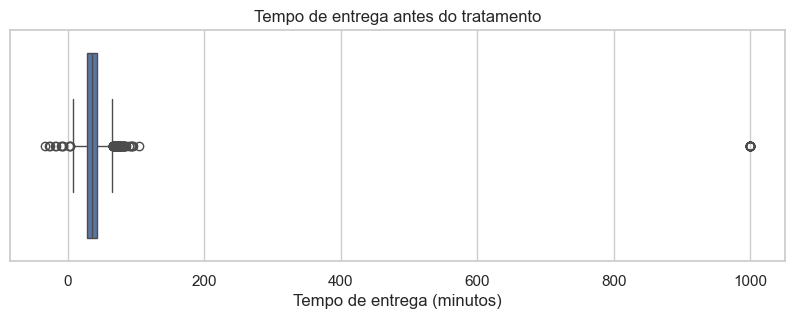

In [342]:
# Boxplot antes do tratamento
plt.figure(figsize=(10, 3))

sns.boxplot(
    x=df["tempo_entrega_min"]
)

plt.title("Tempo de entrega antes do tratamento")
plt.xlabel("Tempo de entrega (minutos)")
plt.show()


In [343]:
# Identifica tempos negativos ou iguais a 999
df["tempo_invalido"] = (
    (df["tempo_entrega_min"] < 0) |
    (df["tempo_entrega_min"] == 999)
)

# Conta os registros inválidos
print("Tempos inválidos:", df["tempo_invalido"].sum())

# Transforma os tempos inválidos em NaN
df.loc[
    df["tempo_invalido"],
    "tempo_entrega_min"
] = np.nan

Tempos inválidos: 33


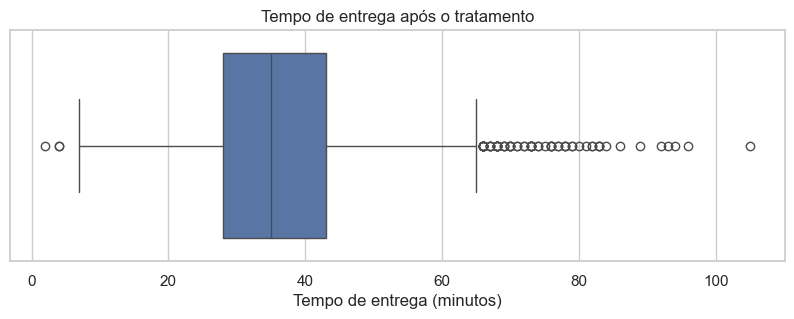

In [344]:
# Boxplot depois do tratamento
plt.figure(figsize=(10, 3))

sns.boxplot(
    x=df["tempo_entrega_min"]
)

plt.title("Tempo de entrega após o tratamento")
plt.xlabel("Tempo de entrega (minutos)")
plt.show()

In [345]:
print("Valores 999 restantes:")
print((df["tempo_entrega_min"] == 999).sum())

print("\nValores negativos restantes:")
print((df["tempo_entrega_min"] < 0).sum())

print("\nValores NaN em tempo_entrega_min:")
print(df["tempo_entrega_min"].isna().sum())

print("\nRegistros marcados como tempo_invalido:")
print(df["tempo_invalido"].sum())

Valores 999 restantes:
0

Valores negativos restantes:
0

Valores NaN em tempo_entrega_min:
33

Registros marcados como tempo_invalido:
33


Antes do tratamento, o boxplot de tempo_entrega_min foi distorcido pela presença de valores negativos e do código 999. Foram identificados 33 registros inválidos, sendo 8 tempos negativos e 25 valores iguais a 999. Esses registros foram marcados na coluna booleana tempo_invalido e seus valores em tempo_entrega_min foram substituídos por NaN. Nenhuma linha foi removida. Depois do tratamento, o boxplot passou a representar apenas os tempos de entrega válidos.

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [346]:
df["distancia_km"] = bruto["distancia_km"].copy()

print(df["distancia_km"].notna().sum())

7743


*Sua resposta aqui*

In [347]:
# Critério 1: z-score > 3
z_score = np.abs(
    stats.zscore(df["distancia_km"], nan_policy="omit")
)

criterio_zscore = z_score > 3

# Critério 2: 1,5 × IQR
Q1 = df["distancia_km"].quantile(0.25)
Q3 = df["distancia_km"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

criterio_iqr = (
    (df["distancia_km"] < limite_inferior) |
    (df["distancia_km"] > limite_superior)
)

# Quantidades sinalizadas por cada critério
print("Pedidos sinalizados pelo z-score > 3:")
print(criterio_zscore.sum())

print("\nPedidos sinalizados por 1,5 × IQR:")
print(criterio_iqr.sum())

print("\nLimite superior do IQR:")
print(round(limite_superior, 2))

# Maiores distâncias observadas
display(
    df[["pedido_id", "distancia_km"]]
    .sort_values("distancia_km", ascending=False)
    .head(15)
)

Pedidos sinalizados pelo z-score > 3:
7

Pedidos sinalizados por 1,5 × IQR:
194

Limite superior do IQR:
9.27


,pedido_id,distancia_km
3242,503242,399.65
706,500706,391.89
3926,503926,369.22
1539,501539,300.21
5826,505826,252.99
5749,505749,163.23
7133,507133,160.26
5200,505200,24.39
6687,506687,18.58
8003,508003,18.30


In [348]:
# A fronteira foi definida pela quebra entre 24,39 km e 160,26 km
df["distancia_invalida"] = df["distancia_km"] > 100

print("Distâncias classificadas como inválidas:")
print(df["distancia_invalida"].sum())

# Exibe os registros que serão tratados
display(
    df.loc[
        df["distancia_invalida"],
        ["pedido_id", "distancia_km"]
    ].sort_values("distancia_km", ascending=False)
)

# Transforma as distâncias inválidas em NaN
df.loc[
    df["distancia_invalida"],
    "distancia_km"
] = np.nan

Distâncias classificadas como inválidas:
7


,pedido_id,distancia_km
3242,503242,399.65
706,500706,391.89
3926,503926,369.22
1539,501539,300.21
5826,505826,252.99
5749,505749,163.23
7133,507133,160.26


In [349]:
# Distâncias originais, sem os valores faltantes
distancias = bruto["distancia_km"].dropna()

# Critério 1: z-score > 3
z_score = np.abs(stats.zscore(distancias))
quantidade_zscore = (z_score > 3).sum()

# Critério 2: 1,5 × IQR
Q1 = distancias.quantile(0.25)
Q3 = distancias.quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

quantidade_iqr = (
    (distancias < limite_inferior) |
    (distancias > limite_superior)
).sum()

# Exibe os resultados
print("Pedidos sinalizados pelo z-score > 3:", quantidade_zscore)
print("Pedidos sinalizados por 1,5 × IQR:", quantidade_iqr)
print("Limite inferior do IQR:", round(limite_inferior, 2))
print("Limite superior do IQR:", round(limite_superior, 2))

Pedidos sinalizados pelo z-score > 3: 7
Pedidos sinalizados por 1,5 × IQR: 194
Limite inferior do IQR: -2.73
Limite superior do IQR: 9.27


O critério de z-score maior que 3 sinalizou 7 pedidos, enquanto o critério de 1,5 × IQR sinalizou 194 pedidos. Pelo IQR, foram considerados discrepantes os valores abaixo de -2,73 km ou acima de 9,27 km. Como distâncias negativas não ocorreram, os 194 casos sinalizados estão acima do limite superior.

A diferença entre os critérios ocorre porque o IQR é mais sensível à assimetria da distribuição e classifica como discrepantes diversas entregas longas que ainda podem ser reais. Portanto, um valor ser sinalizado pelo IQR não significa automaticamente que seja um erro.

Ao ordenar as maiores distâncias, foi observada uma quebra acentuada entre 24,39 km e 160,26 km, sem valores intermediários nesse intervalo. Assim, as distâncias de até 24,39 km foram mantidas como entregas distantes, mas possíveis. As 7 distâncias acima de 100 km, entre 160,26 km e 399,65 km, foram consideradas incompatíveis com o padrão observado na base.

Foi criada a flag booleana distancia_invalida para identificar esses 7 pedidos. Em seguida, os respectivos valores de distancia_km foram transformados em NaN, sem remover nenhuma linha. Dessa forma, foram tratados apenas os valores considerados erros, enquanto os extremos legítimos foram preservados.

### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [350]:
# Calcula os limites considerando todos os pedidos
Q1_geral = df["valor_pedido"].quantile(0.25)
Q3_geral = df["valor_pedido"].quantile(0.75)
IQR_geral = Q3_geral - Q1_geral

limite_inferior_geral = Q1_geral - 1.5 * IQR_geral
limite_superior_geral = Q3_geral + 1.5 * IQR_geral

# Identifica os pedidos sinalizados
iqr_base_inteira = (
    (df["valor_pedido"] < limite_inferior_geral) |
    (df["valor_pedido"] > limite_superior_geral)
)

# Conta por tipo de cozinha
contagem_iqr_geral = (
    df.assign(sinalizado=iqr_base_inteira)
      .groupby("tipo_cozinha")["sinalizado"]
      .sum()
      .rename("IQR_base_inteira")
)

print("Limite inferior geral:", round(limite_inferior_geral, 2))
print("Limite superior geral:", round(limite_superior_geral, 2))
print("Total sinalizado pelo IQR na base inteira:", iqr_base_inteira.sum())


Limite inferior geral: -14.63
Limite superior geral: 144.97
Total sinalizado pelo IQR na base inteira: 352


In [351]:
Q1_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform(
    lambda x: x.quantile(0.25)
)

Q3_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform(
    lambda x: x.quantile(0.75)
)

IQR_cozinha = Q3_cozinha - Q1_cozinha

iqr_por_cozinha = (
    (df["valor_pedido"] < Q1_cozinha - 1.5 * IQR_cozinha) |
    (df["valor_pedido"] > Q3_cozinha + 1.5 * IQR_cozinha)
)

contagem_iqr_cozinha = (
    df.assign(sinalizado=iqr_por_cozinha)
      .groupby("tipo_cozinha")["sinalizado"]
      .sum()
      .rename("IQR_por_cozinha")
)

print(
    "Total sinalizado pelo IQR dentro das cozinhas:",
    iqr_por_cozinha.sum()
)

Total sinalizado pelo IQR dentro das cozinhas: 214


In [352]:
zscore_por_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform(
    lambda x: np.abs(stats.zscore(x))
)

criterio_zscore = zscore_por_cozinha > 3

contagem_zscore = (
    df.assign(sinalizado=criterio_zscore)
      .groupby("tipo_cozinha")["sinalizado"]
      .sum()
      .rename("z_score_maior_3")
)

print(
    "Total sinalizado pelo z-score > 3:",
    criterio_zscore.sum()
)

Total sinalizado pelo z-score > 3: 32


In [353]:
comparacao_outliers = pd.concat(
    [
        contagem_iqr_geral,
        contagem_iqr_cozinha,
        contagem_zscore
    ],
    axis=1
)

comparacao_outliers["diferença_IQR"] = (
    comparacao_outliers["IQR_por_cozinha"] -
    comparacao_outliers["IQR_base_inteira"]
)

display(
    comparacao_outliers.style
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

,IQR_base_inteira,IQR_por_cozinha,z_score_maior_3,diferença_IQR
tipo_cozinha,,,,
Brasileira,6,38,6,32
Doces,3,18,4,15
Hambúrguer,19,43,6,24
Japonesa,246,24,5,-222
Pizza,70,60,4,-10
Saudável,8,31,7,23


O critério de 1,5 × IQR aplicado à base inteira sinalizou 352 pedidos. A maior parte ficou concentrada nas cozinhas Japonesa, com 246 pedidos, e Pizza, com 70. Isso acontece porque o limite geral compara todos os pedidos com uma única distribuição, sem considerar que os tipos de cozinha podem ter padrões diferentes de ticket.

Quando o IQR foi calculado separadamente dentro de cada tipo de cozinha, o total caiu para 214 pedidos. A principal mudança ocorreu na cozinha Japonesa, que passou de 246 para 24 pedidos sinalizados, uma redução de 222. Em Pizza, a quantidade passou de 70 para 60. Por outro lado, aumentou o número de sinalizações em Brasileira, de 6 para 38; Doces, de 3 para 18; Hambúrguer, de 19 para 43; e Saudável, de 8 para 31.

Essa mudança demonstra que o valor_pedido possui distribuições diferentes conforme o tipo_cozinha. O IQR geral sinalizou muitos pedidos da cozinha Japonesa porque seus valores são comparados com os mesmos limites usados para toda a base. Quando cada cozinha recebe seus próprios limites, passam a ser considerados discrepantes apenas os pedidos incomuns dentro daquele tipo de cozinha.

O z-score maior que 3, calculado dentro de cada cozinha, foi mais restritivo e sinalizou somente 32 pedidos: 6 de Brasileira, 4 de Doces, 6 de Hambúrguer, 5 de Japonesa, 4 de Pizza e 7 de Saudável. A diferença ocorre porque o z-score utiliza média e desvio-padrão, enquanto o IQR utiliza quartis.

Portanto, os critérios automáticos produzem resultados bastante diferentes: 352 pedidos pelo IQR geral, 214 pelo IQR por cozinha e 32 pelo z-score por cozinha. Esses pedidos não devem ser removidos automaticamente, pois um valor alto pode ser um ticket legítimo. A comparação mostra que considerar o contexto de cada tipo de cozinha evita classificar como anormais pedidos que são compatíveis com o padrão de sua categoria.

### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [354]:
# Mediana do valor do pedido dentro de cada tipo de cozinha
mediana_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform("median")

# Razão entre o valor do pedido e a mediana da sua cozinha
df["razao_mediana_cozinha"] = df["valor_pedido"] / mediana_cozinha


In [355]:
razoes_ordenadas = (
    df["razao_mediana_cozinha"]
    .sort_values()
    .reset_index(drop=True)
)

saltos = razoes_ordenadas.diff()

posicao_maior_salto = saltos.idxmax()
limite_pedido_grande = razoes_ordenadas.iloc[posicao_maior_salto]

print("Maior salto encontrado:", round(saltos.max(), 2))
print("Razão antes do salto:", round(razoes_ordenadas.iloc[posicao_maior_salto - 1], 2))
print("Razão depois do salto:", round(limite_pedido_grande, 2))

Maior salto encontrado: 10.49
Razão antes do salto: 20.45
Razão depois do salto: 30.94


In [356]:
display(
    df[
        [
            "pedido_id",
            "tipo_cozinha",
            "valor_pedido",
            "razao_mediana_cozinha"
        ]
    ]
    .sort_values("razao_mediana_cozinha", ascending=False)
    .head(20)
)

,pedido_id,tipo_cozinha,valor_pedido,razao_mediana_cozinha
6904,506904,Pizza,2299.10,30.941390
3553,503553,Japonesa,2207.79,20.448180
4023,504023,Pizza,1441.97,19.406096
6787,506787,Hambúrguer,1071.77,17.379115
491,500491,Pizza,1035.26,13.932575
3246,503246,Doces,505.64,13.159141
1035,501035,Japonesa,1394.73,12.917755
1263,501263,Brasileira,614.31,12.846299
1736,501736,Hambúrguer,700.91,11.365494
4045,504045,Hambúrguer,625.71,10.146100


In [357]:
df["pedido_grande"] = (
    df["razao_mediana_cozinha"] >= limite_pedido_grande
)

print("Pedidos classificados como grandes:")
print(df["pedido_grande"].sum())

Pedidos classificados como grandes:
1


In [358]:
display(
    df.loc[
        df["pedido_grande"],
        [
            "pedido_id",
            "cidade",
            "data",
            "tipo_cozinha",
            "valor_pedido",
            "razao_mediana_cozinha",
            "distancia_km",
            "taxa_entrega",
            "tempo_entrega_min"
        ]
    ]
    .sort_values("razao_mediana_cozinha", ascending=False)
)

,pedido_id,cidade,data,tipo_cozinha,valor_pedido,razao_mediana_cozinha,distancia_km,taxa_entrega,tempo_entrega_min
6904,506904,Rio de Janeiro,2024-11-17,Pizza,2299.1,30.94139,2.03,6.82,25.0


A razão entre valor_pedido e a mediana do respectivo tipo_cozinha foi calculada para todos os pedidos. Após ordenar as razões, o maior salto encontrado foi de 10,49, entre as razões 20,45 e 30,94. Esse salto foi utilizado como fronteira para identificar pedidos excepcionalmente grandes.

Apenas 1 pedido ficou acima dessa fronteira: o pedido 506904, realizado em 17/11/2024, no Rio de Janeiro, do tipo de cozinha Pizza. O pedido teve valor de R$ 2.299,10, equivalente a 30,94 vezes a mediana dos pedidos de Pizza.

As demais características não apresentam inconsistências evidentes: a distância foi de 2,03 km, a taxa de entrega foi de R$ 6,82 e o tempo de entrega foi de 25 minutos. Esses valores são compatíveis com uma entrega próxima e concluída em tempo plausível. Portanto, não há evidência suficiente para classificar o alto valor como erro de digitação. O registro parece mais compatível com um pedido real e excepcionalmente grande, possivelmente um pedido corporativo ou coletivo.

A flag booleana pedido_grande foi criada para identificar esse registro, mas o valor foi mantido na base. Essa decisão preserva um possível extremo legítimo, evitando excluir uma transação real apenas por apresentar valor muito superior ao padrão.

Como a base não contém quantidade de itens nem informação sobre o responsável pelo pedido, não é possível confirmar que se trata de um pedido corporativo. Essa classificação permanece como uma interpretação plausível, e não como uma conclusão definitiva.

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [359]:
# 1. Comparação na base inteira
comparacao_geral = pd.DataFrame({
    "cenário": [
        "Com pedidos grandes",
        "Sem pedidos grandes"
    ],
    "média": [
        df["valor_pedido"].mean(),
        df.loc[~df["pedido_grande"], "valor_pedido"].mean()
    ],
    "mediana": [
        df["valor_pedido"].median(),
        df.loc[~df["pedido_grande"], "valor_pedido"].median()
    ]
})

display(
    comparacao_geral.style
        .format({
            "média": "R$ {:.2f}",
            "mediana": "R$ {:.2f}"
        })
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


cenário,média,mediana
Com pedidos grandes,R$ 71.55,R$ 61.61
Sem pedidos grandes,R$ 71.28,R$ 61.61


In [360]:
# Comparação por tipo de cozinha
por_cozinha_com_grandes = (
    df.groupby("tipo_cozinha")["valor_pedido"]
      .agg(["mean", "median"])
      .rename(columns={
          "mean": "média_com_grandes",
          "median": "mediana_com_grandes"
      })
)

por_cozinha_sem_grandes = (
    df.loc[~df["pedido_grande"]]
      .groupby("tipo_cozinha")["valor_pedido"]
      .agg(["mean", "median"])
      .rename(columns={
          "mean": "média_sem_grandes",
          "median": "mediana_sem_grandes"
      })
)

comparacao_por_cozinha = por_cozinha_com_grandes.join(
    por_cozinha_sem_grandes
)

display(
    comparacao_por_cozinha.style
        .format({
            "média_com_grandes": "R$ {:.2f}",
            "mediana_com_grandes": "R$ {:.2f}",
            "média_sem_grandes": "R$ {:.2f}",
            "mediana_sem_grandes": "R$ {:.2f}"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

,média_com_grandes,mediana_com_grandes,média_sem_grandes,mediana_sem_grandes
tipo_cozinha,,,,
Brasileira,R$ 51.17,R$ 47.82,R$ 51.17,R$ 47.82
Doces,R$ 41.79,R$ 38.42,R$ 41.79,R$ 38.42
Hambúrguer,R$ 67.65,R$ 61.67,R$ 67.65,R$ 61.67
Japonesa,R$ 120.37,R$ 107.97,R$ 120.37,R$ 107.97
Pizza,R$ 82.79,R$ 74.31,R$ 81.55,R$ 74.30
Saudável,R$ 58.77,R$ 53.73,R$ 58.77,R$ 53.73


In [361]:
# Mostrar o impacto da retirada dos pedidos grandes
comparacao_por_cozinha["variação_média"] = (
    comparacao_por_cozinha["média_com_grandes"] -
    comparacao_por_cozinha["média_sem_grandes"]
)

comparacao_por_cozinha["variação_mediana"] = (
    comparacao_por_cozinha["mediana_com_grandes"] -
    comparacao_por_cozinha["mediana_sem_grandes"]
)

display(
    comparacao_por_cozinha[
        ["variação_média", "variação_mediana"]
    ].style
        .format("R$ {:.2f}")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

,variação_média,variação_mediana
tipo_cozinha,,
Brasileira,R$ 0.00,R$ 0.00
Doces,R$ 0.00,R$ 0.00
Hambúrguer,R$ 0.00,R$ 0.00
Japonesa,R$ 0.00,R$ 0.00
Pizza,R$ 1.24,R$ 0.01
Saudável,R$ 0.00,R$ 0.00


***Decisão sobre o “ticket típico” ***

A métrica mais adequada será a mediana, porque o valor_pedido apresenta valores extremos legítimos, incluindo o pedido de R$ 2.299,10 identificado na Tarefa 4.4. A média é influenciada por esse pedido, especialmente na cozinha Pizza, enquanto a mediana é mais resistente a valores muito altos.
A comparação foi realizada com e sem os pedidos classificados pela flag pedido_grande, tanto na base inteira quanto por tipo_cozinha. A retirada dos pedidos grandes afetou principalmente a média, pois essa medida é sensível a valores extremos. A mediana apresentou uma alteração menor, ou nenhuma alteração, por depender da posição central dos valores e não da magnitude dos maiores pedidos.

O impacto por cozinha ficou concentrado em Pizza, pois o único pedido classificado como grande, no valor de R$ 2.299,10, pertence a essa categoria. Nas demais cozinhas, os resultados com e sem pedidos grandes permanecem iguais, já que nenhuma delas teve pedido marcado pela flag.

Daqui em diante, a mediana será utilizada para representar o “ticket típico”, pois descreve melhor o comportamento central dos pedidos em uma distribuição com valores extremos. A média ainda poderá ser apresentada quando o objetivo for calcular faturamento médio por pedido, mas deverá ser interpretada considerando sua sensibilidade aos pedidos excepcionalmente grandes.


In [362]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [363]:
# Colunas solicitadas
colunas_resumo = [
    "valor_pedido",
    "taxa_entrega",
    "distancia_km",
    "tempo_entrega_min",
    "avaliacao"
]

# Métricas do describe()
resumo = df[colunas_resumo].describe().T

# IQR = terceiro quartil - primeiro quartil
resumo["IQR"] = resumo["75%"] - resumo["25%"]

# Coeficiente de variação = desvio-padrão / média × 100
resumo["coeficiente_variacao_%"] = (
    resumo["std"] / resumo["mean"]
) * 100

# Assimetria
resumo["assimetria"] = df[colunas_resumo].skew()

# Moda
resumo["moda"] = df[colunas_resumo].mode().iloc[0]

# Renomeia as métricas para melhorar a leitura
resumo = resumo.rename(columns={
    "count": "quantidade",
    "mean": "média",
    "std": "desvio_padrão",
    "min": "mínimo",
    "25%": "1º_quartil",
    "50%": "mediana",
    "75%": "3º_quartil",
    "max": "máximo"
})

# Exibe a tabela
display(
    resumo.style
        .format({
            "quantidade": "{:.0f}",
            "média": "{:.2f}",
            "desvio_padrão": "{:.2f}",
            "mínimo": "{:.2f}",
            "1º_quartil": "{:.2f}",
            "mediana": "{:.2f}",
            "3º_quartil": "{:.2f}",
            "máximo": "{:.2f}",
            "IQR": "{:.2f}",
            "coeficiente_variacao_%": "{:.2f}%",
            "assimetria": "{:.2f}",
            "moda": "{:.2f}"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


,quantidade,média,desvio_padrão,mínimo,1º_quartil,mediana,3º_quartil,máximo,IQR,coeficiente_variacao_%,assimetria,moda
valor_pedido,8058,71.55,60.26,11.03,45.22,61.61,85.12,2299.10,39.90,84.22%,17.52,48.52
taxa_entrega,8058,7.27,3.29,0.00,6.16,7.42,9.08,26.94,2.92,45.20%,-0.51,0.00
distancia_km,7736,3.54,2.39,0.08,1.77,3.02,4.76,24.39,2.99,67.55%,1.37,2.70
tempo_entrega_min,8025,35.91,11.10,2.00,28.00,35.00,43.00,105.00,15.00,30.92%,0.52,34.00
avaliacao,6716,4.35,0.69,1.00,4.00,4.00,5.00,5.00,1.00,15.76%,-0.70,5.00


### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

(a) Variável mais assimétrica

A variável mais assimétrica é valor_pedido, com assimetria de 17,52, indicando uma distribuição fortemente assimétrica à direita. A maior parte dos pedidos está concentrada em valores menores, enquanto poucos pedidos muito altos, como o máximo de R$ 2.299,10, alongam a cauda da distribuição e elevam a média.

Isso aparece na diferença entre a média de R$ 71,55 e a mediana de R$ 61,61. Portanto, a mediana é mais adequada para representar o ticket típico, pois sofre menos influência dos pedidos excepcionalmente grandes.

(b) Maior variabilidade relativa

valor_pedido também possui a maior variabilidade relativa, com coeficiente de variação de 84,22%. Isso significa que os valores dos pedidos apresentam grande dispersão em relação à própria média.

A ordem observada foi:

valor_pedido: 84,22%;
distancia_km: 67,55%;
taxa_entrega: 45,20%;
tempo_entrega_min: 30,92%;
avaliacao: 15,76%.

Assim, avaliacao é a variável mais homogênea entre as analisadas.

(c) Moda da taxa de entrega

A moda de taxa_entrega é R$ 0,00, indicando que a taxa mais frequente na base é a entrega sem cobrança. Entretanto, a moda sozinha não mostra qual percentual dos pedidos recebeu taxa zero nem explica o motivo. Esse resultado pode estar relacionado a cupons ou outras condições comerciais, mas isso precisa ser investigado antes de concluir.

(d) Avaliação média

A avaliação média é 4,35 em uma escala de 1 a 5, portanto é alta. A mediana é 4 e a moda é 5, mostrando concentração das avaliações nas notas mais altas.

A assimetria negativa de -0,70 reforça essa interpretação: as notas estão concentradas na parte superior da escala, com uma cauda formada pelas avaliações mais baixas. A conclusão considera apenas os 6.716 pedidos que possuem avaliação, pois os 1.342 valores faltantes foram mantidos como NaN.

### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [364]:
colunas_categoricas = [
    "cidade",
    "tipo_cozinha",
    "forma_pagamento",
    "plataforma"
]

modas_categoricas = pd.DataFrame({
    "coluna": colunas_categoricas,
    "moda": [
        df[coluna].mode().iloc[0]
        for coluna in colunas_categoricas
    ]
})

display(
    modas_categoricas.style
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


coluna,moda
cidade,São Paulo
tipo_cozinha,Hambúrguer
forma_pagamento,Cartão de crédito
plataforma,Android


In [365]:
for coluna in colunas_categoricas:

    distribuicao = (
        df[coluna]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .rename("percentual")
        .reset_index()
    )

    print(f"\nDistribuição percentual de {coluna}:")

    display(
        distribuicao.style
            .format({"percentual": "{:.2f}%"})
            .hide(axis="index")
            .set_properties(**{"text-align": "left"})
            .set_table_styles([
                {"selector": "th", "props": [("text-align", "left")]}
            ])
    )


Distribuição percentual de cidade:


cidade,percentual
São Paulo,50.32%
Rio de Janeiro,29.42%
Belo Horizonte,20.25%



Distribuição percentual de tipo_cozinha:


tipo_cozinha,percentual
Hambúrguer,23.84%
Pizza,22.16%
Brasileira,19.37%
Japonesa,13.85%
Saudável,10.67%
Doces,10.10%



Distribuição percentual de forma_pagamento:


forma_pagamento,percentual
Cartão de crédito,45.20%
Pix,32.68%
Vale-refeição,15.17%
Dinheiro,6.96%



Distribuição percentual de plataforma:


plataforma,percentual
Android,55.21%
iOS,31.94%
Web,10.95%
Não informado,1.90%


A moda de cidade é São Paulo, que concentra 50,32% dos pedidos. Rio de Janeiro representa 29,42%, e Belo Horizonte, 20,25%. Portanto, pouco mais da metade dos pedidos da base ocorreu em São Paulo.

Em tipo_cozinha, a moda é Hambúrguer, com 23,84% dos pedidos, seguida de Pizza, com 22,16%, e Brasileira, com 19,37%. A distribuição é relativamente diversificada, pois nenhuma cozinha concentra sozinha mais de um quarto dos pedidos.

Na coluna forma_pagamento, a moda é Cartão de crédito, utilizado em 45,20% dos pedidos. Pix aparece em segundo lugar, com 32,68%. Juntas, essas duas formas representam 77,88% dos pedidos, indicando predominância dos pagamentos eletrônicos na base.

Em plataforma, a moda é Android, responsável por 55,21% dos pedidos. O iOS representa 31,94%, a Web, 10,95%, e a categoria Não informado, criada para preservar os faltantes, corresponde a 1,90%.

Assim, o perfil categórico mais frequente é formado por pedidos de São Paulo, de cozinha Hambúrguer, pagos com Cartão de crédito e realizados pela plataforma Android. Essa combinação reúne as modas individuais das variáveis, mas não significa necessariamente que seja a combinação conjunta mais frequente, pois isso exigiria um agrupamento simultâneo das quatro colunas.

### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [366]:
# Considera somente os tempos de entrega válidos
tempos_validos = df["tempo_entrega_min"].dropna()

# Calcula os percentis solicitados
percentis_tempo = tempos_validos.quantile([0.50, 0.75, 0.90, 0.95])

tabela_percentis = (
    percentis_tempo
    .rename(index={
        0.50: "P50",
        0.75: "P75",
        0.90: "P90",
        0.95: "P95"
    })
    .rename("tempo_entrega_min")
    .to_frame()
)

display(
    tabela_percentis.style
        .format({"tempo_entrega_min": "{:.2f} minutos"})
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


,tempo_entrega_min
P50,35.00 minutos
P75,43.00 minutos
P90,50.00 minutos
P95,55.00 minutos


In [367]:
# Pedidos acima de 35 e 45 minutos
quantidade_acima_35 = (tempos_validos > 35).sum()
percentual_acima_35 = (tempos_validos > 35).mean() * 100

quantidade_acima_45 = (tempos_validos > 45).sum()
percentual_acima_45 = (tempos_validos > 45).mean() * 100

metricas_tempo = pd.DataFrame({
    "critério": [
        "Acima de 35 minutos",
        "Acima de 45 minutos"
    ],
    "quantidade_pedidos": [
        quantidade_acima_35,
        quantidade_acima_45
    ],
    "percentual": [
        percentual_acima_35,
        percentual_acima_45
    ]
})

display(
    metricas_tempo.style
        .format({"percentual": "{:.2f}%"})
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

critério,quantidade_pedidos,percentual
Acima de 35 minutos,3908,48.70%
Acima de 45 minutos,1476,18.39%


Considerando os 8.025 pedidos com tempo de entrega válido, 50% foram entregues em até 35 minutos, 75% em até 43 minutos, 90% em até 50 minutos e 95% em até 55 minutos.

Foram identificados 3.908 pedidos acima de 35 minutos, correspondentes a 48,70% dos pedidos com tempo válido. Acima de 45 minutos, foram encontrados 1.476 pedidos, equivalentes a 18,39%.

Portanto, se a empresa prometesse entrega em até 45 minutos, 1.476 pedidos de 2024 teriam quebrado a promessa, considerando apenas os pedidos com tempo de entrega válido. Isso significa que aproximadamente 1 em cada 5 pedidos avaliáveis não cumpriria o prazo prometido.

Os 33 pedidos com tempo inválido, sendo 8 valores negativos e 25 registros originalmente codificados como 999, não foram incluídos no cálculo. Pedidos entregues em exatamente 45 minutos foram considerados dentro da promessa, pois “em até 45 minutos” inclui o limite de 45 minutos.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [368]:
# Percentual acima de 45 min calculado somente entre tempos válidos
tempos_validos = df["tempo_entrega_min"].dropna()

kpis_2024 = pd.Series({
    "Nº de pedidos": len(df),
    "Faturamento em itens (R$)": df["valor_pedido"].sum(),
    "Receita de taxa de entrega (R$)": df["taxa_entrega"].sum(),
    "Ticket médio (R$)": df["valor_pedido"].mean(),
    "Ticket mediano (R$)": df["valor_pedido"].median(),
    "% de pedidos com cupom": df["cupom"].mean() * 100,
    "% de clientes novos": df["cliente_novo"].mean() * 100,
    "% com frete grátis": (df["taxa_entrega"] == 0).mean() * 100,
    "Tempo médio de entrega (min)": tempos_validos.mean(),
    "% de entregas acima de 45 min": (tempos_validos > 45).mean() * 100,
    "Avaliação média": df["avaliacao"].mean(),
    "% de pedidos avaliados": df["avaliacao"].notna().mean() * 100
}, name="KPIs de 2024")

display(kpis_2024)


Nº de pedidos                        8058.000000
Faturamento em itens (R$)          576584.750000
Receita de taxa de entrega (R$)     58571.400000
Ticket médio (R$)                      71.554325
Ticket mediano (R$)                    61.610000
% de pedidos com cupom                 21.208737
% de clientes novos                    17.374038
% com frete grátis                     11.169025
Tempo médio de entrega (min)           35.914268
% de entregas acima de 45 min          18.392523
Avaliação média                         4.348868
% de pedidos avaliados                 83.345743
Name: KPIs de 2024, dtype: float64

In [369]:
kpis_formatados = kpis_2024.copy()

kpis_formatados["Nº de pedidos"] = (
    f"{kpis_2024['Nº de pedidos']:,.0f}"
    .replace(",", ".")
)

kpis_formatados["Faturamento em itens (R$)"] = (
    f"R$ {kpis_2024['Faturamento em itens (R$)']:,.2f}"
    .replace(",", "X")
    .replace(".", ",")
    .replace("X", ".")
)

kpis_formatados["Receita de taxa de entrega (R$)"] = (
    f"R$ {kpis_2024['Receita de taxa de entrega (R$)']:,.2f}"
    .replace(",", "X")
    .replace(".", ",")
    .replace("X", ".")
)

kpis_formatados["Ticket médio (R$)"] = (
    f"R$ {kpis_2024['Ticket médio (R$)']:.2f}"
    .replace(".", ",")
)

kpis_formatados["Ticket mediano (R$)"] = (
    f"R$ {kpis_2024['Ticket mediano (R$)']:.2f}"
    .replace(".", ",")
)

for indicador in [
    "% de pedidos com cupom",
    "% de clientes novos",
    "% com frete grátis",
    "% de entregas acima de 45 min",
    "% de pedidos avaliados"
]:
    kpis_formatados[indicador] = (
        f"{kpis_2024[indicador]:.2f}%"
        .replace(".", ",")
    )

kpis_formatados["Tempo médio de entrega (min)"] = (
    f"{kpis_2024['Tempo médio de entrega (min)']:.2f} min"
    .replace(".", ",")
)

kpis_formatados["Avaliação média"] = (
    f"{kpis_2024['Avaliação média']:.2f}"
    .replace(".", ",")
)

display(
    kpis_formatados
        .rename("valor")
        .to_frame()
        .style
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

C:\Users\Usuário\AppData\Local\Temp\ipykernel_12996\1838473239.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '8.058' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  kpis_formatados["Nº de pedidos"] = (


,valor
Nº de pedidos,8.058
Faturamento em itens (R$),"R$ 576.584,75"
Receita de taxa de entrega (R$),"R$ 58.571,40"
Ticket médio (R$),"R$ 71,55"
Ticket mediano (R$),"R$ 61,61"
% de pedidos com cupom,"21,21%"
% de clientes novos,"17,37%"
% com frete grátis,"11,17%"
Tempo médio de entrega (min),"35,91 min"
% de entregas acima de 45 min,"18,39%"


### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [370]:
# Resumo por cidade com named aggregation
resumo_cidade = (
    df.groupby("cidade")
      .agg(
          pedidos=("pedido_id", "count"),
          faturamento=("valor_pedido", "sum"),
          ticket_mediano=("valor_pedido", "median"),
          tempo_medio_entrega=("tempo_entrega_min", "mean"),
          avaliacao_media=("avaliacao", "mean"),
          percentual_com_cupom=("cupom", "mean")
      )
)

# Participação de cada cidade no total de pedidos
resumo_cidade["participacao_percentual"] = (
    resumo_cidade["pedidos"] / resumo_cidade["pedidos"].sum() * 100
)

# Um registro por cidade e dia para não contar o mesmo dia várias vezes
chuva_cidade_dia = (
    df.groupby(["cidade", "data"])
      .agg(
          dia_com_chuva=("chuva", "max")
      )
      .reset_index()
)

# Percentual de dias com chuva em cada cidade
percentual_dias_chuva = (
    chuva_cidade_dia.groupby("cidade")
                    .agg(
                        percentual_dias_com_chuva=("dia_com_chuva", "mean")
                    )
)

# Adiciona o percentual de dias com chuva à tabela
resumo_cidade = resumo_cidade.join(percentual_dias_chuva)

# Converte as proporções para percentuais
resumo_cidade["percentual_com_cupom"] *= 100
resumo_cidade["percentual_dias_com_chuva"] *= 100

# Coloca as colunas na ordem solicitada e ordena por pedidos
resumo_cidade = (
    resumo_cidade[
        [
            "pedidos",
            "participacao_percentual",
            "faturamento",
            "ticket_mediano",
            "tempo_medio_entrega",
            "avaliacao_media",
            "percentual_com_cupom",
            "percentual_dias_com_chuva"
        ]
    ]
    .sort_values("pedidos", ascending=False)
)

display(
    resumo_cidade.style
        .format({
            "pedidos": "{:.0f}",
            "participacao_percentual": "{:.2f}%",
            "faturamento": "R$ {:,.2f}",
            "ticket_mediano": "R$ {:.2f}",
            "tempo_medio_entrega": "{:.2f} min",
            "avaliacao_media": "{:.2f}",
            "percentual_com_cupom": "{:.2f}%",
            "percentual_dias_com_chuva": "{:.2f}%"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


,pedidos,participacao_percentual,faturamento,ticket_mediano,tempo_medio_entrega,avaliacao_media,percentual_com_cupom,percentual_dias_com_chuva
cidade,,,,,,,,
São Paulo,4055,50.32%,"R$ 289,275.55",R$ 61.54,35.86 min,4.35,21.60%,25.21%
Rio de Janeiro,2371,29.42%,"R$ 172,029.24",R$ 61.43,35.71 min,4.36,20.75%,24.45%
Belo Horizonte,1632,20.25%,"R$ 115,279.96",R$ 62.05,36.34 min,4.34,20.89%,26.39%


*Sua resposta aqui*

### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [371]:
resumo_cozinha = (
    df.groupby("tipo_cozinha")
      .agg(
          pedidos=("pedido_id", "count"),
          ticket_medio=("valor_pedido", "mean"),
          ticket_mediano=("valor_pedido", "median"),
          faturamento=("valor_pedido", "sum")
      )
)

# Participação de cada cozinha no faturamento total
resumo_cozinha["participacao_faturamento_%"] = (
    resumo_cozinha["faturamento"]
    / resumo_cozinha["faturamento"].sum()
    * 100
)

# Ordena pelo volume de pedidos
resumo_cozinha = resumo_cozinha.sort_values(
    "pedidos",
    ascending=False
)

display(
    resumo_cozinha.style
        .format({
            "pedidos": "{:.0f}",
            "ticket_medio": "R$ {:.2f}",
            "ticket_mediano": "R$ {:.2f}",
            "faturamento": "R$ {:,.2f}",
            "participacao_faturamento_%": "{:.2f}%"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


,pedidos,ticket_medio,ticket_mediano,faturamento,participacao_faturamento_%
tipo_cozinha,,,,,
Hambúrguer,1921,R$ 67.65,R$ 61.67,"R$ 129,963.40",22.54%
Pizza,1786,R$ 82.79,R$ 74.31,"R$ 147,857.26",25.64%
Brasileira,1561,R$ 51.17,R$ 47.82,"R$ 79,871.60",13.85%
Japonesa,1116,R$ 120.37,R$ 107.97,"R$ 134,328.26",23.30%
Saudável,860,R$ 58.77,R$ 53.73,"R$ 50,544.31",8.77%
Doces,814,R$ 41.79,R$ 38.42,"R$ 34,019.92",5.90%


In [372]:
print(
    "Maior ticket médio:",
    resumo_cozinha["ticket_medio"].idxmax(),
    f"- R$ {resumo_cozinha['ticket_medio'].max():.2f}"
)

print(
    "Menor ticket médio:",
    resumo_cozinha["ticket_medio"].idxmin(),
    f"- R$ {resumo_cozinha['ticket_medio'].min():.2f}"
)

print(
    "\nMaior ticket mediano:",
    resumo_cozinha["ticket_mediano"].idxmax(),
    f"- R$ {resumo_cozinha['ticket_mediano'].max():.2f}"
)

print(
    "Menor ticket mediano:",
    resumo_cozinha["ticket_mediano"].idxmin(),
    f"- R$ {resumo_cozinha['ticket_mediano'].min():.2f}"
)

Maior ticket médio: Japonesa - R$ 120.37
Menor ticket médio: Doces - R$ 41.79

Maior ticket mediano: Japonesa - R$ 107.97
Menor ticket mediano: Doces - R$ 38.42


In [373]:
ordem_volume = resumo_cozinha.sort_values(
    "pedidos",
    ascending=False
).index.tolist()

ordem_faturamento = resumo_cozinha.sort_values(
    "faturamento",
    ascending=False
).index.tolist()

print("Ordem por volume:")
print(ordem_volume)

print("\nOrdem por faturamento:")
print(ordem_faturamento)

print(
    "\nA ordem por volume é igual à ordem por faturamento?",
    ordem_volume == ordem_faturamento
)

Ordem por volume:
['Hambúrguer', 'Pizza', 'Brasileira', 'Japonesa', 'Saudável', 'Doces']

Ordem por faturamento:
['Pizza', 'Japonesa', 'Hambúrguer', 'Brasileira', 'Saudável', 'Doces']

A ordem por volume é igual à ordem por faturamento? False


Considerando a mediana como medida do ticket típico, a cozinha Japonesa apresentou o maior ticket, com R$ 107,97, enquanto Doces apresentou o menor, com R$ 38,42. Pelas médias, essas duas categorias também ocupam os extremos, com R$ 120,37 e R$ 41,79, respectivamente.

A ordem por volume de pedidos não é igual à ordem por faturamento. Por volume, a sequência foi: Hambúrguer, Pizza, Brasileira, Japonesa, Saudável e Doces. Por faturamento, a ordem foi: Pizza, Japonesa, Hambúrguer, Brasileira, Saudável e Doces.

Hambúrguer teve o maior volume, com 1.921 pedidos, mas ficou em terceiro lugar no faturamento, com R$ 129.963,40. Já Japonesa, mesmo ocupando apenas o quarto lugar em volume, com 1.116 pedidos, alcançou o segundo maior faturamento, de R$ 134.328,26, devido ao seu ticket mais elevado.

Pizza apresentou o maior faturamento, com R$ 147.857,26, equivalente a 25,64% do faturamento total. Esse resultado combina um volume alto, de 1.786 pedidos, com o segundo maior ticket mediano, de R$ 74,31.

Portanto, o faturamento não depende apenas da quantidade de pedidos. O valor típico dos pedidos também altera a importância financeira de cada cozinha, como demonstra a cozinha Japonesa, que gera faturamento elevado mesmo com volume menor.

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [374]:
resumo_plataforma = (
    df.groupby("plataforma")
      .agg(
          ticket_mediano=("valor_pedido", "median"),
          avaliacao_media=("avaliacao", "mean")
      )
      .sort_values("ticket_mediano", ascending=False)
)

display(
    resumo_plataforma.style
        .format({
            "ticket_mediano": "R$ {:.2f}",
            "avaliacao_media": "{:.2f}"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


,ticket_mediano,avaliacao_media
plataforma,,
Web,R$ 62.97,4.33
Não informado,R$ 62.44,4.39
Android,R$ 61.67,4.35
iOS,R$ 60.75,4.35


In [375]:
pagamento_por_cidade = pd.crosstab(
    df["cidade"],
    df["forma_pagamento"],
    normalize="index"
) * 100

display(
    pagamento_por_cidade.style
        .format("{:.2f}%")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.26%,6.86%,32.60%,14.28%
Rio de Janeiro,45.47%,6.87%,33.11%,14.55%
São Paulo,44.61%,7.05%,32.45%,15.88%


In [376]:
normalize="index"

In [377]:
print("Soma dos percentuais por cidade:")

display(
    pagamento_por_cidade.sum(axis=1)
        .rename("percentual_total")
        .to_frame()
)

Soma dos percentuais por cidade:


,percentual_total
cidade,
Belo Horizonte,100.0
Rio de Janeiro,100.0
São Paulo,100.0


O ticket mediano varia pouco entre as plataformas. A Web apresentou o maior ticket mediano, de R$ 62,97, seguida por Não informado, com R$ 62,44, Android, com R$ 61,67, e iOS, com R$ 60,75. A diferença entre Web e iOS, os extremos entre as plataformas identificadas, foi de apenas R$ 2,22.

As avaliações médias também são muito próximas: 4,33 na Web, 4,35 no Android, 4,35 no iOS e 4,39 em Não informado. Descritivamente, não há diferenças expressivas de avaliação entre as plataformas. A categoria Não informado deve ser interpretada com cautela, pois representa somente os 1,90% de pedidos cuja plataforma original estava ausente.

(b) Cidade × forma de pagamento

Cada linha da tabela totaliza 100%, portanto os percentuais mostram como os pedidos de cada cidade se distribuem entre as formas de pagamento.

As três cidades apresentam um padrão muito semelhante. O cartão de crédito é a forma mais utilizada em todas elas, variando de 44,61% em São Paulo a 46,26% em Belo Horizonte. O Pix ocupa a segunda posição, com percentuais entre 32,45% e 33,11%. O dinheiro permanece próximo de 7% nas três cidades.

A maior diferença observada aparece no Vale-refeição: 15,88% em São Paulo, 14,55% no Rio de Janeiro e 14,28% em Belo Horizonte. Mesmo assim, a diferença máxima é de apenas 1,60 ponto percentual.

Portanto, pela análise descritiva, as cidades não parecem pagar de forma muito diferente, pois as distribuições são bastante próximas. Entretanto, essa tabela não determina se existe associação estatisticamente significativa. Essa conclusão será validada na hipótese H5 pelo teste qui-quadrado de independência.

### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [378]:
# Série diária
pedidos_dia = (
    df.set_index("data_hora")
      .resample("D")
      .size()
      .rename("pedidos")
)

# Série semanal, encerrando aos domingos
pedidos_semana = (
    df.set_index("data_hora")
      .resample("W-SUN")
      .size()
      .rename("pedidos")
)

# Série mensal
pedidos_mes = (
    df.set_index("data_hora")
      .resample("MS")
      .size()
      .rename("pedidos")
)

print("Pedidos por dia:")
display(pedidos_dia.to_frame())

print("Pedidos por semana:")
display(pedidos_semana.to_frame())

print("Pedidos por mês:")
display(pedidos_mes.to_frame())


Pedidos por dia:


,pedidos
data_hora,
2024-01-01,18
2024-01-02,23
2024-01-03,27
2024-01-04,13
2024-01-05,19
...,...
2024-12-27,33
2024-12-28,33
2024-12-29,24


Pedidos por semana:


,pedidos
data_hora,
2024-01-07,141
2024-01-14,152
2024-01-21,150
2024-01-28,128
2024-02-04,129
2024-02-11,125
2024-02-18,129
2024-02-25,133
2024-03-03,169


Pedidos por mês:


,pedidos
data_hora,
2024-01-01,618
2024-02-01,559
2024-03-01,647
2024-04-01,580
2024-05-01,660
2024-06-01,630
2024-07-01,822
2024-08-01,662
2024-09-01,664


In [379]:
resumo_granularidades = pd.DataFrame({
    "granularidade": ["Dia", "Semana", "Mês"],
    "quantidade_periodos": [
        pedidos_dia.size,
        pedidos_semana.size,
        pedidos_mes.size
    ],
    "mínimo_pedidos": [
        pedidos_dia.min(),
        pedidos_semana.min(),
        pedidos_mes.min()
    ],
    "média_pedidos": [
        pedidos_dia.mean(),
        pedidos_semana.mean(),
        pedidos_mes.mean()
    ],
    "máximo_pedidos": [
        pedidos_dia.max(),
        pedidos_semana.max(),
        pedidos_mes.max()
    ]
})

display(
    resumo_granularidades.style
        .format({
            "quantidade_periodos": "{:.0f}",
            "mínimo_pedidos": "{:.0f}",
            "média_pedidos": "{:.2f}",
            "máximo_pedidos": "{:.0f}"
        })
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

granularidade,quantidade_periodos,mínimo_pedidos,média_pedidos,máximo_pedidos
Dia,366,1,22.02,41
Semana,53,49,152.04,202
Mês,12,559,671.50,840


In [380]:
Q1_dia = pedidos_dia.quantile(0.25)
Q3_dia = pedidos_dia.quantile(0.75)
IQR_dia = Q3_dia - Q1_dia

limite_inferior_dia = Q1_dia - 1.5 * IQR_dia
limite_superior_dia = Q3_dia + 1.5 * IQR_dia

dias_anomalos = pedidos_dia[
    (pedidos_dia < limite_inferior_dia) |
    (pedidos_dia > limite_superior_dia)
]

print("Limite inferior diário:", round(limite_inferior_dia, 2))
print("Limite superior diário:", round(limite_superior_dia, 2))
print("Quantidade de dias anômalos:", len(dias_anomalos))

display(
    dias_anomalos
        .sort_values(ascending=False)
        .to_frame()
)

Limite inferior diário: 6.0
Limite superior diário: 38.0
Quantidade de dias anômalos: 3


,pedidos
data_hora,
2024-07-16,41
2024-07-19,40
2024-08-14,1


In [381]:
print("Dia com menor volume:")
display(pedidos_dia.nsmallest(5).to_frame())

print("Dia com maior volume:")
display(pedidos_dia.nlargest(5).to_frame())

Dia com menor volume:


,pedidos
data_hora,
2024-08-14,1
2024-11-06,8
2024-03-20,10
2024-04-09,10
2024-06-24,10


Dia com maior volume:


,pedidos
data_hora,
2024-07-16,41
2024-07-19,40
2024-12-20,38
2024-10-25,37
2024-11-01,37


In [382]:
dias_por_semana = (
    df[["data"]]
    .drop_duplicates()
    .assign(data=lambda x: pd.to_datetime(x["data"]))
    .set_index("data")
    .resample("W-SUN")
    .size()
    .rename("dias_na_semana")
)

analise_semanal = pd.concat(
    [pedidos_semana, dias_por_semana],
    axis=1
)

analise_semanal["semana_completa"] = (
    analise_semanal["dias_na_semana"] == 7
)

display(analise_semanal)

,pedidos,dias_na_semana,semana_completa
2024-01-07,141,7,True
2024-01-14,152,7,True
2024-01-21,150,7,True
2024-01-28,128,7,True
2024-02-04,129,7,True
2024-02-11,125,7,True
2024-02-18,129,7,True
2024-02-25,133,7,True
2024-03-03,169,7,True
2024-03-10,132,7,True


In [383]:
print("Semanas que não devem ser comparadas diretamente com semanas completas:")

display(
    analise_semanal[
        ~analise_semanal["semana_completa"]
    ]
)

Semanas que não devem ser comparadas diretamente com semanas completas:


,pedidos,dias_na_semana,semana_completa
2025-01-05,49,2,False


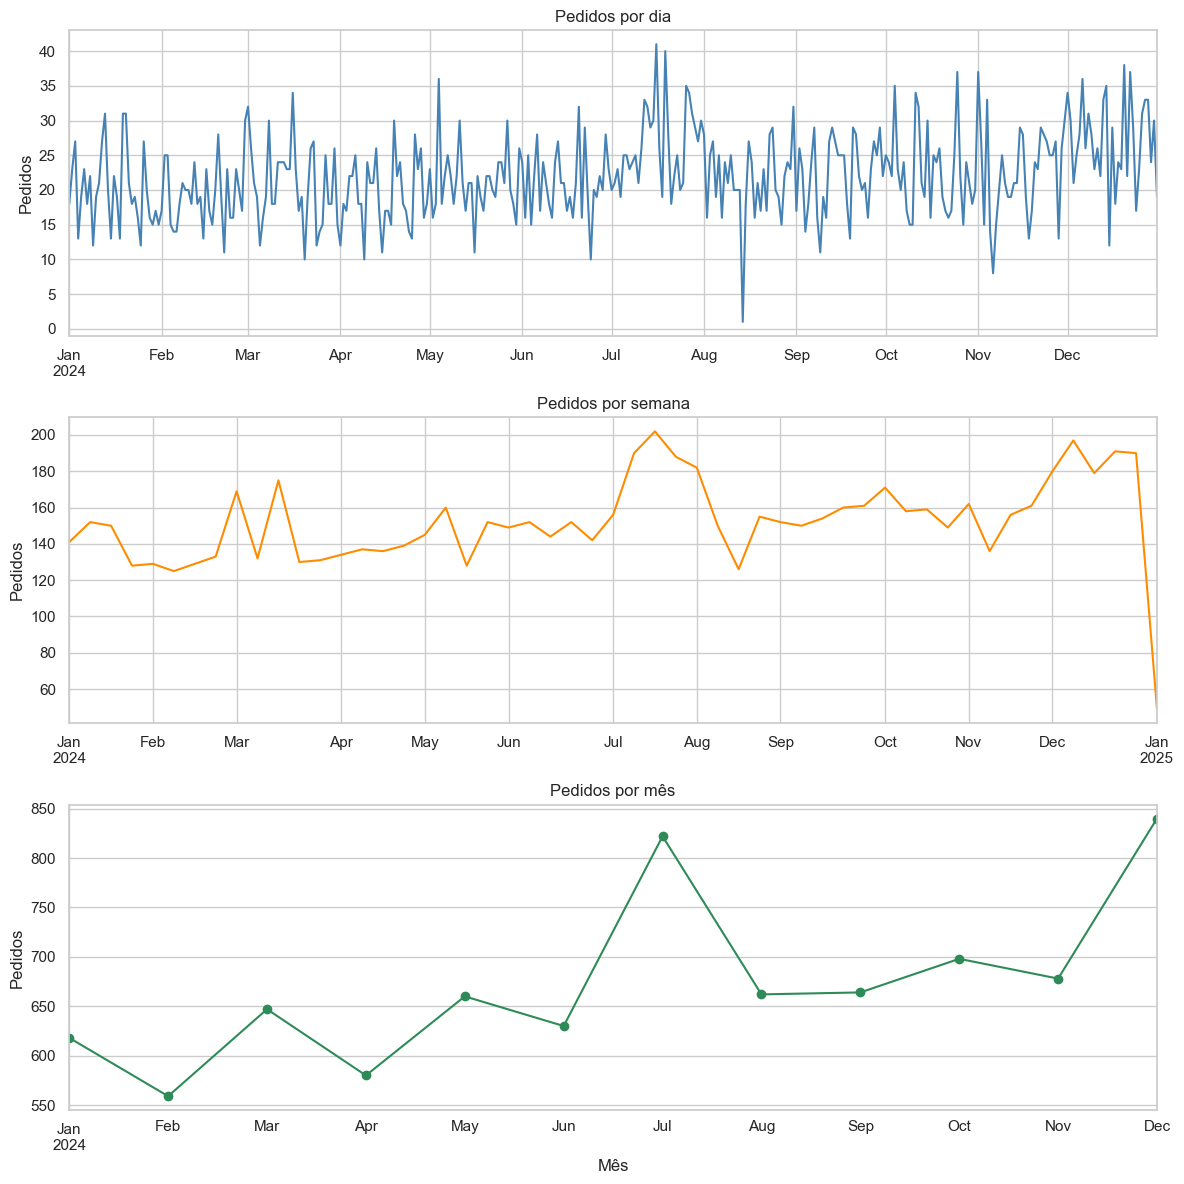

In [384]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

pedidos_dia.plot(
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Pedidos por dia")
axes[0].set_xlabel("")
axes[0].set_ylabel("Pedidos")

pedidos_semana.plot(
    ax=axes[1],
    color="darkorange"
)
axes[1].set_title("Pedidos por semana")
axes[1].set_xlabel("")
axes[1].set_ylabel("Pedidos")

pedidos_mes.plot(
    ax=axes[2],
    color="seagreen",
    marker="o"
)
axes[2].set_title("Pedidos por mês")
axes[2].set_xlabel("Mês")
axes[2].set_ylabel("Pedidos")

plt.tight_layout()
plt.show()

A série diária apresenta o maior nível de detalhe e permite identificar dias específicos com volume excepcionalmente alto ou baixo. Esses movimentos podem desaparecer quando os pedidos são agregados por semana ou por mês. Os dias classificados como anômalos pelo IQR foram apresentados separadamente e devem ser investigados antes de qualquer conclusão.

A série semanal reduz a oscilação diária e facilita a comparação do volume entre semanas. Entretanto, a última semana do período não deve ser comparada diretamente com as demais, pois contém somente 30 e 31 de dezembro de 2024, enquanto as semanas completas possuem sete dias. Seu volume mais baixo decorre da cobertura parcial, e não necessariamente de uma queda real na demanda.

A série mensal oferece uma visão mais estável da evolução ao longo de 2024 e permite observar tendências e diferenças entre meses. Em contrapartida, ela esconde variações diárias, dias anômalos e oscilações que acontecem dentro de cada mês.

Assim, a granularidade diária é mais adequada para detectar anomalias operacionais; a semanal é útil para acompanhar oscilações de curto prazo; e a mensal é mais adequada para analisar tendências gerais. A conclusão sobre qual dia foi anômalo deve usar exatamente os resultados apresentados em dias_anomalos.

### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [385]:
pedidos_hora_dia = pd.pivot_table(
    df,
    index="hora",
    columns="dia_semana",
    values="pedido_id",
    aggfunc="count",
    fill_value=0,
    observed=True
)

display(
    pedidos_hora_dia.style
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


dia_semana,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
7,2,5,1,3,4,4,3
8,7,3,10,4,6,13,13
9,11,13,7,8,23,11,13
10,22,17,15,20,22,17,19
11,79,81,71,77,78,117,71
12,175,154,128,143,186,195,157
13,126,110,99,124,161,156,107
14,45,33,40,40,54,58,41
15,23,20,27,18,31,28,31


In [386]:
# Conta os pedidos de cada data real da base
pedidos_por_data = (
    df.groupby(["data", "dia_semana"], observed=True)
      .agg(
          pedidos=("pedido_id", "count")
      )
      .reset_index()
)

# Calcula a média para cada dia da semana
media_pedidos_dia_semana = (
    pedidos_por_data
    .groupby("dia_semana", observed=True)
    .agg(
        quantidade_dias=("data", "count"),
        total_pedidos=("pedidos", "sum"),
        media_pedidos_por_dia=("pedidos", "mean")
    )
)

display(
    media_pedidos_dia_semana.style
        .format({
            "quantidade_dias": "{:.0f}",
            "total_pedidos": "{:.0f}",
            "media_pedidos_por_dia": "{:.2f}"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

,quantidade_dias,total_pedidos,media_pedidos_por_dia
dia_semana,,,
Seg,53,1107,20.89
Ter,53,1064,20.08
Qua,52,1020,19.62
Qui,52,1049,20.17
Sex,52,1379,26.52
Sáb,52,1365,26.25
Dom,52,1074,20.65


In [387]:
print(
    "Total de datas contabilizadas:",
    media_pedidos_dia_semana["quantidade_dias"].sum()
)

print(
    "Total de pedidos contabilizados:",
    media_pedidos_dia_semana["total_pedidos"].sum()
)

Total de datas contabilizadas: 366
Total de pedidos contabilizados: 8058


In [388]:
print(
    "Maior média de pedidos por dia:",
    media_pedidos_dia_semana["media_pedidos_por_dia"].idxmax(),
    f"- {media_pedidos_dia_semana['media_pedidos_por_dia'].max():.2f}"
)

print(
    "Menor média de pedidos por dia:",
    media_pedidos_dia_semana["media_pedidos_por_dia"].idxmin(),
    f"- {media_pedidos_dia_semana['media_pedidos_por_dia'].min():.2f}"
)

Maior média de pedidos por dia: Sex - 26.52
Menor média de pedidos por dia: Qua - 19.62


(a) Pedidos por hora e dia da semana

A tabela mostra dois períodos principais de concentração da demanda: o almoço, principalmente entre 12h e 13h, e o jantar, entre 19h e 21h.

O maior volume acumulado ocorreu na sexta-feira às 20h, com 212 pedidos em 2024. Em seguida aparecem a sexta-feira às 19h, com 208 pedidos, e o sábado às 20h, com 201 pedidos.

Os resultados indicam maior pressão operacional nas noites de sexta-feira e sábado. É importante observar que os valores da tabela representam o total acumulado de todas as ocorrências de cada combinação de hora e dia da semana em 2024, e não o volume de um único dia.

(b) Média de pedidos por dia da semana

A sexta-feira apresentou a maior média, com 26,52 pedidos por dia, seguida pelo sábado, com 26,25. A quarta-feira apresentou a menor média, com 19,62 pedidos por dia.

A média é mais justa do que a simples contagem anual porque os dias da semana não ocorreram o mesmo número de vezes em 2024. Segunda-feira e terça-feira apareceram 53 vezes, enquanto os demais dias apareceram 52 vezes. A contagem total poderia favorecer segunda e terça apenas por terem ocorrido uma vez a mais.

Ao dividir o total de pedidos pela quantidade efetiva de ocorrências de cada dia da semana, a média representa melhor a demanda típica. Mesmo após esse ajuste, sexta-feira e sábado permanecem como os dias de maior movimento, indicando que o resultado não decorre apenas da composição do calendário.

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [389]:
comparacao_cupom = (
    df.groupby("cupom")
      .agg(
          pedidos=("pedido_id", "count"),
          ticket_mediano=("valor_pedido", "median"),
          percentual_clientes_novos=("cliente_novo", "mean"),
          percentual_frete_gratis=(
              "taxa_entrega",
              lambda x: (x == 0).mean()
          ),
          avaliacao_media=("avaliacao", "mean")
      )
      .rename(index={
          False: "Sem cupom",
          True: "Com cupom"
      })
)

# Converte as proporções em percentuais
comparacao_cupom["percentual_clientes_novos"] *= 100
comparacao_cupom["percentual_frete_gratis"] *= 100

display(
    comparacao_cupom.style
        .format({
            "pedidos": "{:.0f}",
            "ticket_mediano": "R$ {:.2f}",
            "percentual_clientes_novos": "{:.2f}%",
            "percentual_frete_gratis": "{:.2f}%",
            "avaliacao_media": "{:.2f}"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


,pedidos,ticket_mediano,percentual_clientes_novos,percentual_frete_gratis,avaliacao_media
cupom,,,,,
Sem cupom,6349,R$ 62.82,12.81%,0.00%,4.36
Com cupom,1709,R$ 57.22,34.35%,52.66%,4.31


In [390]:
taxa_cupom_mes = (
    df.groupby("mes")
      .agg(
          pedidos=("pedido_id", "count"),
          pedidos_com_cupom=("cupom", "sum"),
          taxa_uso_cupom=("cupom", "mean")
      )
)

taxa_cupom_mes["taxa_uso_cupom"] *= 100

In [391]:
pedidos_por_data = (
    df.groupby(["mes", "data"])
    .agg(pedidos_dia=("pedido_id", "count"))
    .reset_index()
)

media_diaria_mes = (
    pedidos_por_data.groupby("mes")
    .agg(
        quantidade_dias=("data", "count"),
        media_pedidos_por_dia=("pedidos_dia", "mean")
    )
)

display(media_diaria_mes)

,quantidade_dias,media_pedidos_por_dia
mes,,
1,31,19.935484
2,29,19.275862
3,31,20.870968
4,30,19.333333
5,31,21.290323
6,30,21.000000
7,31,26.516129
8,31,21.354839
9,30,22.133333


In [392]:
resumo_mensal_cupom = taxa_cupom_mes.join(media_diaria_mes)

display(
    resumo_mensal_cupom.style
        .format({
            "pedidos": "{:.0f}",
            "pedidos_com_cupom": "{:.0f}",
            "taxa_uso_cupom": "{:.2f}%",
            "quantidade_dias": "{:.0f}",
            "media_pedidos_por_dia": "{:.2f}"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

,pedidos,pedidos_com_cupom,taxa_uso_cupom,quantidade_dias,media_pedidos_por_dia
mes,,,,,
1,618,100,16.18%,31,19.94
2,559,132,23.61%,29,19.28
3,647,129,19.94%,31,20.87
4,580,96,16.55%,30,19.33
5,660,123,18.64%,31,21.29
6,630,123,19.52%,30,21.00
7,822,375,45.62%,31,26.52
8,662,140,21.15%,31,21.35
9,664,125,18.83%,30,22.13


In [393]:
# Calcula o número de pedidos em cada dia de cada mês
pedidos_por_data_mes = (
    df.groupby(["mes", "data"])
      .agg(
          pedidos_dia=("pedido_id", "count")
      )
      .reset_index()
)

# Compara julho com os demais meses
comparacao_julho = pd.DataFrame({
    "período": ["Julho", "Demais meses"],

    "taxa_uso_cupom": [
        df.loc[df["mes"] == 7, "cupom"].mean() * 100,
        df.loc[df["mes"] != 7, "cupom"].mean() * 100
    ],

    "media_pedidos_por_dia": [
        pedidos_por_data_mes.loc[
            pedidos_por_data_mes["mes"] == 7,
            "pedidos_dia"
        ].mean(),

        pedidos_por_data_mes.loc[
            pedidos_por_data_mes["mes"] != 7,
            "pedidos_dia"
        ].mean()
    ]
})

display(
    comparacao_julho.style
        .format({
            "taxa_uso_cupom": "{:.2f}%",
            "media_pedidos_por_dia": "{:.2f}"
        })
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {
                "selector": "th",
                "props": [("text-align", "left")]
            }
        ])
)

período,taxa_uso_cupom,media_pedidos_por_dia
Julho,45.62%,26.52
Demais meses,18.44%,21.60


(a) Pedidos com e sem cupom

Os pedidos sem cupom apresentaram ticket mediano de R$ 62,82, enquanto os pedidos com cupom tiveram ticket mediano de R$ 57,22, uma diferença de R$ 5,60. Portanto, os pedidos com cupom tiveram ticket típico menor.

A participação de clientes novos foi de 34,35% nos pedidos com cupom, contra 12,81% nos pedidos sem cupom. Isso indica que o uso de cupom foi proporcionalmente mais frequente entre clientes novos.

O frete grátis ocorreu em 52,66% dos pedidos com cupom e em 0% dos pedidos sem cupom. Assim, na base analisada, o frete grátis está fortemente associado ao uso de cupom.

A avaliação média foi de 4,31 nos pedidos com cupom e 4,36 nos pedidos sem cupom. A diferença de 0,05 ponto é pequena, indicando avaliações muito semelhantes entre os grupos.

(b) Uso mensal de cupom e média diária de pedidos

Julho apresentou uma mudança evidente em relação ao restante do ano:

taxa de uso de cupom em julho: 45,62%;
taxa nos demais meses: 18,44%;
média diária em julho: 26,52 pedidos;
média diária nos demais meses: 21,60 pedidos;
total de julho: 822 pedidos, dos quais 375 usaram cupom.

Julho teve uma taxa de uso de cupom 27,18 pontos percentuais maior que a dos demais meses. A média diária também foi 4,92 pedidos maior, uma elevação de aproximadamente 22,8% em relação aos demais meses.

Portanto, durante a campanha “Julho de cupons”, houve uma concentração muito maior no uso de cupons e um volume diário de pedidos superior ao padrão dos outros meses. Julho teve a segunda maior média diária e o segundo maior volume mensal de 2024, ficando atrás apenas de dezembro, que registrou média de 27,10 pedidos por dia e 840 pedidos.

Os resultados mostram uma associação entre a campanha, o aumento no uso de cupons e o maior volume de pedidos. Entretanto, não comprovam que os cupons causaram o crescimento, pois outros fatores específicos de julho também podem ter influenciado a demanda.

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [394]:
tempo_medio_chuva = (
    df.groupby("chuva")
      .agg(
          quantidade_pedidos=("pedido_id", "count"),
          pedidos_com_tempo_valido=("tempo_entrega_min", "count"),
          tempo_medio_entrega=("tempo_entrega_min", "mean")
      )
      .rename(index={
          False: "Sem chuva",
          True: "Com chuva"
      })
)

display(
    tempo_medio_chuva.style
        .format({
            "quantidade_pedidos": "{:.0f}",
            "pedidos_com_tempo_valido": "{:.0f}",
            "tempo_medio_entrega": "{:.2f} min"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)


,quantidade_pedidos,pedidos_com_tempo_valido,tempo_medio_entrega
chuva,,,
Sem chuva,5691,5667,33.23 min
Com chuva,2367,2358,42.36 min


In [395]:
pedidos_cidade_dia = (
    df.groupby(["cidade", "data"])
      .agg(
          pedidos=("pedido_id", "count"),
          chuva=("chuva", "first")
      )
      .reset_index()
)


In [396]:
media_pedidos_chuva_cidade = (
    pedidos_cidade_dia
    .groupby(["cidade", "chuva"])
    .agg(
        quantidade_dias=("data", "count"),
        total_pedidos=("pedidos", "sum"),
        media_pedidos_cidade_dia=("pedidos", "mean")
    )
    .reset_index()
)

media_pedidos_chuva_cidade["chuva"] = (
    media_pedidos_chuva_cidade["chuva"]
    .map({
        False: "Sem chuva",
        True: "Com chuva"
    })
)

display(
    media_pedidos_chuva_cidade.style
        .format({
            "quantidade_dias": "{:.0f}",
            "total_pedidos": "{:.0f}",
            "media_pedidos_cidade_dia": "{:.2f}"
        })
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

cidade,chuva,quantidade_dias,total_pedidos,media_pedidos_cidade_dia
Belo Horizonte,Sem chuva,265,1128,4.26
Belo Horizonte,Com chuva,95,504,5.31
Rio de Janeiro,Sem chuva,275,1724,6.27
Rio de Janeiro,Com chuva,89,647,7.27
São Paulo,Sem chuva,273,2839,10.40
São Paulo,Com chuva,92,1216,13.22


In [397]:
comparacao_chuva_cidade = media_pedidos_chuva_cidade.pivot(
    index="cidade",
    columns="chuva",
    values="media_pedidos_cidade_dia"
)

display(
    comparacao_chuva_cidade.style
        .format("{:.2f}")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left")]}
        ])
)

chuva,Com chuva,Sem chuva
cidade,,
Belo Horizonte,5.31,4.26
Rio de Janeiro,7.27,6.27
São Paulo,13.22,10.40


Por que não comparar apenas o total de pedidos?

O total de pedidos com e sem chuva não é uma comparação justa porque a quantidade de dias com chuva é diferente da quantidade de dias sem chuva. Como existem mais dias de uma das condições, o total de pedidos tende naturalmente a ser maior nessa condição, mesmo que a demanda diária seja igual ou menor.

Além disso, chuva é uma característica da combinação cidade × data, mas aparece repetida em todos os pedidos daquele grupo. Por isso, contar diretamente as linhas da base daria mais peso aos dias que já tiveram mais pedidos.

A média de pedidos por cidade-dia corrige esse problema: primeiro cada cidade em cada data é transformada em uma única observação e, depois, compara-se o volume diário típico nos dias com e sem chuva. Assim, a análise responde se uma cidade recebe, em média, mais ou menos pedidos quando chove, e não apenas qual condição acumulou mais pedidos durante o ano.

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [398]:
# Série diária de pedidos em 2024
pedidos_dia = (
    df.set_index("data_hora")
      .resample("D")
      .size()
      .rename("pedidos")
)

# Médias diárias do 1º e do 4º trimestre
media_1_trimestre = pedidos_dia.loc[
    "2024-01-01":"2024-03-31"
].mean()

media_4_trimestre = pedidos_dia.loc[
    "2024-10-01":"2024-12-31"
].mean()

crescimento_trimestres = (
    (media_4_trimestre / media_1_trimestre) - 1
) * 100

comparacao_trimestres = pd.DataFrame({
    "período": [
        "1º trimestre",
        "4º trimestre"
    ],
    "média de pedidos por dia": [
        media_1_trimestre,
        media_4_trimestre
    ]
})

display(
    comparacao_trimestres.style
        .format({
            "média de pedidos por dia": "{:.2f}"
        })
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {
                "selector": "th",
                "props": [("text-align", "left")]
            }
        ])
)

print(
    "Crescimento do 1º para o 4º trimestre:",
    f"{crescimento_trimestres:.2f}%"
)


período,média de pedidos por dia
1º trimestre,20.04
4º trimestre,24.09


Crescimento do 1º para o 4º trimestre: 20.17%


In [399]:
# Remove somente o dia anômalo de 14/08/2024
pedidos_dia_reta = pedidos_dia.drop(
    pd.Timestamp("2024-08-14")
)

# Número de dias desde 01/01/2024
x = (
    pedidos_dia_reta.index -
    pd.Timestamp("2024-01-01")
).days.to_numpy()

# Quantidade diária de pedidos
y = pedidos_dia_reta.to_numpy()

# Ajusta uma reta: y = inclinação * x + intercepto
inclinacao, intercepto = np.polyfit(x, y, 1)

# Valores estimados pela reta no início e no fim de 2024
estimativa_janeiro = intercepto
estimativa_dezembro = inclinacao * 365 + intercepto

# Crescimento percentual estimado
crescimento_reta = (
    (estimativa_dezembro / estimativa_janeiro) - 1
) * 100

resultado_reta = pd.Series({
    "Inclinação diária": inclinacao,
    "Pedidos estimados no início de janeiro": estimativa_janeiro,
    "Pedidos estimados no fim de dezembro": estimativa_dezembro,
    "Crescimento estimado de janeiro a dezembro (%)": crescimento_reta
})

display(
    resultado_reta
        .rename("valor")
        .to_frame()
        .style
        .format({"valor": "{:.2f}"})
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {
                "selector": "th",
                "props": [("text-align", "left")]
            }
        ])
)

,valor
Inclinação diária,0.02
Pedidos estimados no início de janeiro,19.11
Pedidos estimados no fim de dezembro,25.04
Crescimento estimado de janeiro a dezembro (%),31.07


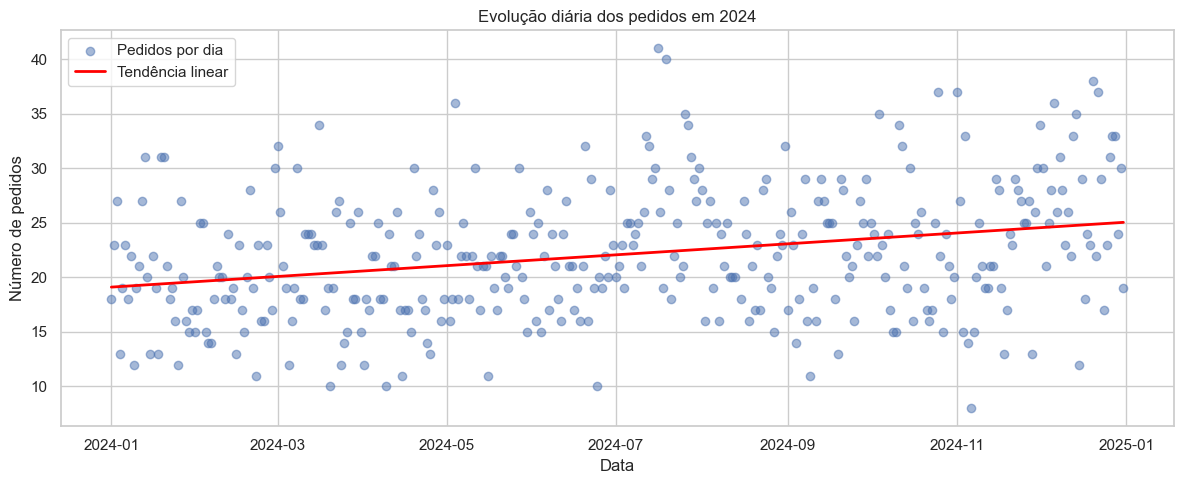

In [400]:
valores_reta = inclinacao * x + intercepto

plt.figure(figsize=(12, 5))

plt.scatter(
    pedidos_dia_reta.index,
    y,
    alpha=0.5,
    label="Pedidos por dia"
)

plt.plot(
    pedidos_dia_reta.index,
    valores_reta,
    color="red",
    linewidth=2,
    label="Tendência linear"
)

plt.title("Evolução diária dos pedidos em 2024")
plt.xlabel("Data")
plt.ylabel("Número de pedidos")
plt.legend()
plt.tight_layout()
plt.show()

O volume de pedidos cresceu ao longo de 2024 nas duas formas de análise.

Na comparação trimestral, a média passou de 20,04 pedidos por dia no 1º trimestre para 24,09 pedidos por dia no 4º trimestre, o que representa um crescimento de 20,17%.

Na tendência linear, após excluir o dia anômalo de 14/08/2024, a reta apresentou inclinação positiva de aproximadamente 0,02 pedido por dia. O modelo estimou 19,11 pedidos por dia no início de janeiro e 25,04 pedidos por dia no fim de dezembro, correspondendo a um crescimento estimado de 31,07% ao longo do ano.

Portanto, as duas abordagens confirmam crescimento no volume. A comparação entre trimestres mostra uma expansão de 20,17% entre períodos específicos, enquanto a reta, por considerar a tendência de toda a série diária, estima crescimento de 31,07% entre o início e o final de 2024.

Os percentuais não precisam ser iguais porque medem o crescimento de formas diferentes: a primeira abordagem compara as médias de dois trimestres completos; a segunda compara os valores estimados pela tendência linear nos extremos do ano.

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [401]:
# Paleta visual do projeto
COR_PRINCIPAL = "#2563EB"
COR_DESTAQUE = "#F97316"
COR_NEUTRA = "#B8C0CC"
COR_TEXTO = "#1F2937"
COR_GRADE = "#E5E7EB"

# Cores fixas para variáveis booleanas
CORES_CHUVA = {
    False: COR_NEUTRA,
    True: COR_PRINCIPAL
}

CORES_CUPOM = {
    False: COR_NEUTRA,
    True: COR_DESTAQUE
}

# Cores fixas para as cidades
CORES_CIDADE = {
    "São Paulo": "#2563EB",
    "Rio de Janeiro": "#F97316",
    "Belo Horizonte": "#16A34A"
}

# Formatação de valores em reais
def formatar_reais(valor, pos=None):
    return (
        f"R$ {valor:,.0f}"
        .replace(",", ".")
    )

FORMATADOR_REAIS = mticker.FuncFormatter(formatar_reais)

# Formatação de percentuais
def formatar_percentual(valor, pos=None):
    return f"{valor:.0f}%".replace(".", ",")

FORMATADOR_PERCENTUAL = mticker.FuncFormatter(
    formatar_percentual
)

# Função reutilizável para título e subtítulo
def adicionar_titulo(ax, titulo, subtitulo=None):
    ax.set_title(
        titulo,
        loc="left",
        fontsize=14,
        fontweight="bold",
        color=COR_TEXTO,
        pad=18
    )

    if subtitulo:
        ax.text(
            0,
            1.02,
            subtitulo,
            transform=ax.transAxes,
            fontsize=10,
            color="#6B7280"
        )

# Configuração geral dos gráficos
sns.set_theme(
    style="white",
    context="notebook"
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.labelcolor": COR_TEXTO,
    "xtick.color": COR_TEXTO,
    "ytick.color": COR_TEXTO
})

### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

In [402]:
# Estatísticas calculadas com a base inteira
media_ticket = df["valor_pedido"].mean()
mediana_ticket = df["valor_pedido"].median()

# Limite visual do gráfico
limite_visual = df["valor_pedido"].quantile(0.99)

# Quantidade de pedidos fora da área exibida
pedidos_fora_eixo = (
    df["valor_pedido"] > limite_visual
).sum()

# Quantidade marcada como pedido grande
quantidade_pedidos_grandes = df["pedido_grande"].sum()

# Dados usados somente na visualização do histograma
ticket_visual = df.loc[
    df["valor_pedido"] <= limite_visual,
    "valor_pedido"
]


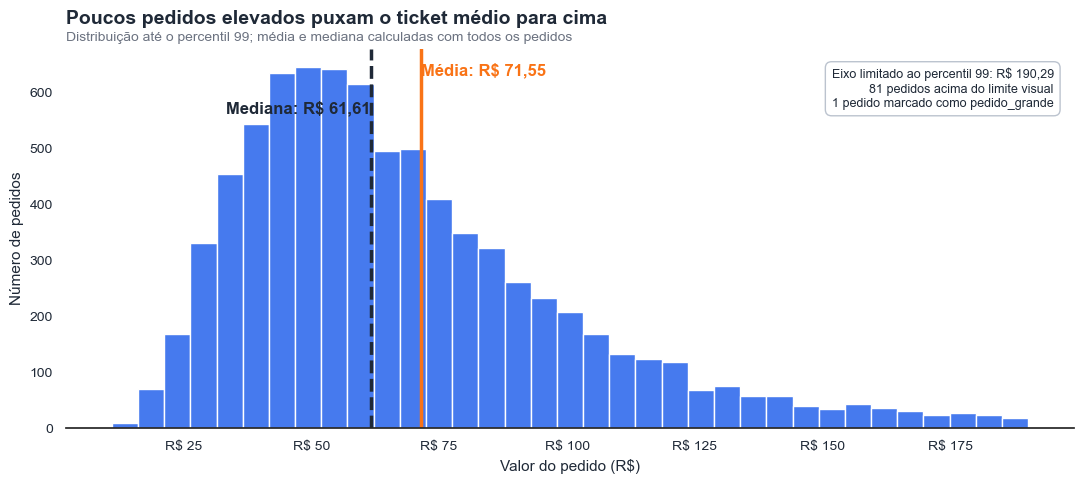

In [403]:
fig, ax = plt.subplots(figsize=(11, 5))

# Distribuição do ticket até o percentil 99
sns.histplot(
    data=ticket_visual,
    bins=35,
    color=COR_PRINCIPAL,
    edgecolor="white",
    alpha=0.85,
    ax=ax
)

# Linha da média
ax.axvline(
    media_ticket,
    color=COR_DESTAQUE,
    linewidth=2.5
)

# Linha da mediana
ax.axvline(
    mediana_ticket,
    color=COR_TEXTO,
    linewidth=2.5,
    linestyle="--"
)

# Identificação direta das medidas
altura_maxima = ax.get_ylim()[1]

ax.text(
    media_ticket,
    altura_maxima * 0.93,
    f"Média: R$ {media_ticket:.2f}".replace(".", ","),
    color=COR_DESTAQUE,
    fontweight="bold",
    ha="left"
)

ax.text(
    mediana_ticket,
    altura_maxima * 0.83,
    f"Mediana: R$ {mediana_ticket:.2f}".replace(".", ","),
    color=COR_TEXTO,
    fontweight="bold",
    ha="right"
)

# Informação sobre os valores não exibidos no eixo
texto_extremos = (
    f"Eixo limitado ao percentil 99: R$ {limite_visual:.2f}\n"
    f"{pedidos_fora_eixo} pedidos acima do limite visual\n"
    f"{quantidade_pedidos_grandes} pedido marcado como pedido_grande"
).replace(".", ",")

ax.text(
    0.98,
    0.95,
    texto_extremos,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    color=COR_TEXTO,
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": COR_NEUTRA,
        "alpha": 0.95
    }
)

# Título-conclusão e subtítulo
adicionar_titulo(
    ax,
    "Poucos pedidos elevados puxam o ticket médio para cima",
    "Distribuição até o percentil 99; média e mediana calculadas com todos os pedidos"
)

# Rótulos e formatação
ax.set_xlabel("Valor do pedido (R$)")
ax.set_ylabel("Número de pedidos")

ax.xaxis.set_major_formatter(FORMATADOR_REAIS)

# Remove elementos visuais desnecessários
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

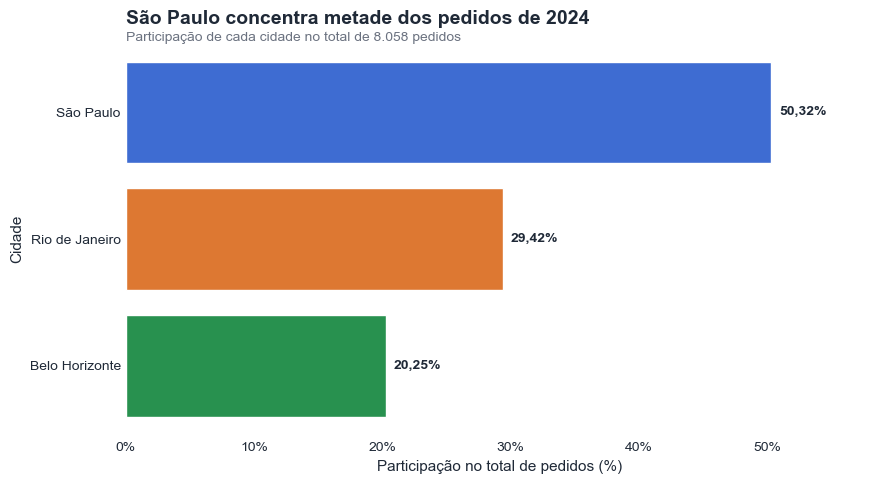

In [404]:
# Calcula a participação percentual de cada cidade
participacao_cidade = (
    df["cidade"]
    .value_counts(normalize=True)
    .mul(100)
    .rename_axis("cidade")
    .reset_index(name="participacao")
    .sort_values("participacao", ascending=False)
)

# Aplica as cores definidas no padrão visual
cores_barras = (
    participacao_cidade["cidade"]
    .map(CORES_CIDADE)
    .tolist()
)

# Cria o gráfico
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=participacao_cidade,
    x="participacao",
    y="cidade",
    hue="cidade",
    palette=CORES_CIDADE,
    legend=False,
    ax=ax
)

# Escreve o percentual em cada barra
for barra, percentual in zip(
    ax.patches,
    participacao_cidade["participacao"]
):
    ax.text(
        barra.get_width() + 0.6,
        barra.get_y() + barra.get_height() / 2,
        f"{percentual:.2f}%".replace(".", ","),
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color=COR_TEXTO
    )

# Título-conclusão e subtítulo
adicionar_titulo(
    ax,
    "São Paulo concentra metade dos pedidos de 2024",
    "Participação de cada cidade no total de 8.058 pedidos"
)

# Rótulos e formatação
ax.set_xlabel("Participação no total de pedidos (%)")
ax.set_ylabel("Cidade")
ax.xaxis.set_major_formatter(FORMATADOR_PERCENTUAL)

# Espaço para os rótulos das barras
ax.set_xlim(
    0,
    participacao_cidade["participacao"].max() + 8
)

# Remove elementos desnecessários
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()


### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

In [405]:
# Ordem das cozinhas pelo ticket mediano, da maior para a menor
ordem_cozinhas = (
    df.groupby("tipo_cozinha")["valor_pedido"]
      .median()
      .sort_values(ascending=False)
      .index
      .tolist()
)

# Identifica as cozinhas de maior e menor ticket mediano
cozinha_maior_ticket = ordem_cozinhas[0]
cozinha_menor_ticket = ordem_cozinhas[-1]

# Paleta: destaque nos extremos e cinza nas demais
cores_cozinhas = {
    cozinha: COR_NEUTRA
    for cozinha in ordem_cozinhas
}

cores_cozinhas[cozinha_maior_ticket] = COR_PRINCIPAL
cores_cozinhas[cozinha_menor_ticket] = COR_DESTAQUE


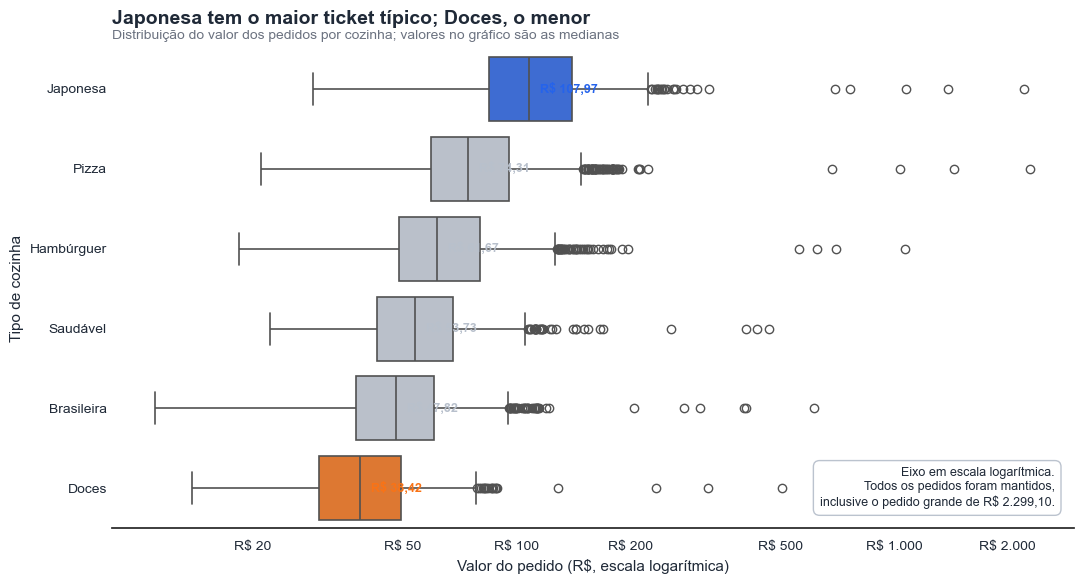

In [406]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="valor_pedido",
    y="tipo_cozinha",
    order=ordem_cozinhas,
    hue="tipo_cozinha",
    palette=cores_cozinhas,
    legend=False,
    showfliers=True,
    linewidth=1.2,
    ax=ax
)

# Escala logarítmica para manter os pedidos elevados visíveis
ax.set_xscale("log")

# Marcações legíveis no eixo
marcacoes_reais = [
    20, 50, 100, 200, 500, 1000, 2000
]

ax.set_xticks(marcacoes_reais)
ax.xaxis.set_major_formatter(FORMATADOR_REAIS)
ax.xaxis.set_minor_formatter(mticker.NullFormatter())

# Medianas por cozinha
medianas_cozinhas = (
    df.groupby("tipo_cozinha")["valor_pedido"]
      .median()
      .reindex(ordem_cozinhas)
)

# Escreve a mediana ao lado de cada cozinha
for posicao, (cozinha, mediana) in enumerate(
    medianas_cozinhas.items()
):
    ax.text(
        mediana * 1.07,
        posicao,
        f"R$ {mediana:.2f}".replace(".", ","),
        va="center",
        ha="left",
        fontsize=9,
        fontweight="bold",
        color=cores_cozinhas[cozinha]
    )

# Informa que os valores elevados continuam representados
ax.text(
    0.98,
    0.04,
    (
        "Eixo em escala logarítmica.\n"
        "Todos os pedidos foram mantidos,\n"
        "inclusive o pedido grande de R$ 2.299,10."
    ),
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    color=COR_TEXTO,
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": COR_NEUTRA,
        "alpha": 0.95
    }
)

adicionar_titulo(
    ax,
    "Japonesa tem o maior ticket típico; Doces, o menor",
    "Distribuição do valor dos pedidos por cozinha; valores no gráfico são as medianas"
)

ax.set_xlabel("Valor do pedido (R$, escala logarítmica)")
ax.set_ylabel("Tipo de cozinha")

# Remove elementos visuais desnecessários
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

In [407]:
# Série diária de pedidos
pedidos_dia = (
    df.set_index("data_hora")
      .resample("D")
      .size()
      .rename("pedidos")
)

# Média móvel de 7 dias
media_movel_7d = (
    pedidos_dia
    .rolling(window=7, min_periods=1)
    .mean()
)

# Datas indicadas pelo projeto e pela análise
inicio_campanha = pd.Timestamp("2024-07-01")
fim_campanha = pd.Timestamp("2024-07-31")
dia_instabilidade = pd.Timestamp("2024-08-14")

pedidos_instabilidade = pedidos_dia.loc[dia_instabilidade]



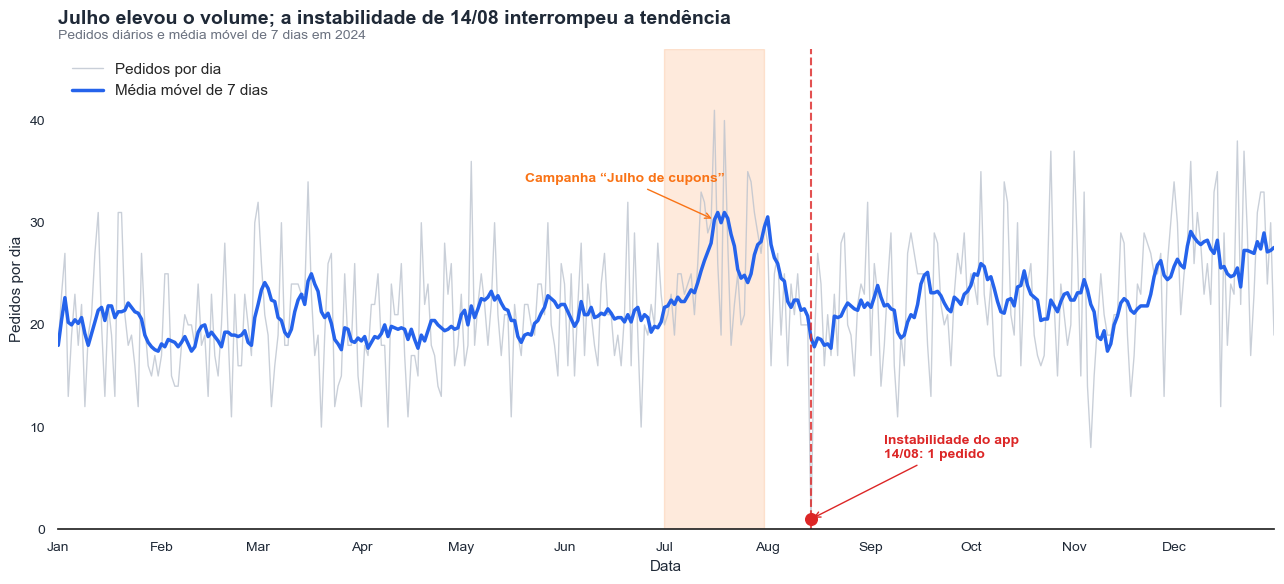

In [408]:
fig, ax = plt.subplots(figsize=(13, 6))

# Campanha de julho
ax.axvspan(
    inicio_campanha,
    fim_campanha,
    color=COR_DESTAQUE,
    alpha=0.15
)

# Série diária em cor neutra
ax.plot(
    pedidos_dia.index,
    pedidos_dia.values,
    color=COR_NEUTRA,
    linewidth=1,
    alpha=0.75,
    label="Pedidos por dia"
)

# Média móvel como informação principal
ax.plot(
    media_movel_7d.index,
    media_movel_7d.values,
    color=COR_PRINCIPAL,
    linewidth=2.5,
    label="Média móvel de 7 dias"
)

# Marca o dia de instabilidade
ax.scatter(
    dia_instabilidade,
    pedidos_instabilidade,
    color="#DC2626",
    s=70,
    zorder=5
)

# Linha vertical no dia de instabilidade
ax.axvline(
    dia_instabilidade,
    color="#DC2626",
    linewidth=1.5,
    linestyle="--",
    alpha=0.8
)

# Anotação da campanha
ax.annotate(
    "Campanha “Julho de cupons”",
    xy=(pd.Timestamp("2024-07-16"), media_movel_7d.loc["2024-07-16"]),
    xytext=(pd.Timestamp("2024-05-20"), 34),
    arrowprops={
        "arrowstyle": "->",
        "color": COR_DESTAQUE
    },
    color=COR_DESTAQUE,
    fontsize=10,
    fontweight="bold"
)

# Anotação da instabilidade
ax.annotate(
    f"Instabilidade do app\n14/08: {pedidos_instabilidade} pedido",
    xy=(dia_instabilidade, pedidos_instabilidade),
    xytext=(pd.Timestamp("2024-09-05"), 7),
    arrowprops={
        "arrowstyle": "->",
        "color": "#DC2626"
    },
    color="#DC2626",
    fontsize=10,
    fontweight="bold"
)

# Título-conclusão e subtítulo
adicionar_titulo(
    ax,
    "Julho elevou o volume; a instabilidade de 14/08 interrompeu a tendência",
    "Pedidos diários e média móvel de 7 dias em 2024"
)

# Rótulos dos eixos
ax.set_xlabel("Data")
ax.set_ylabel("Pedidos por dia")

# Formatação do eixo temporal
ax.xaxis.set_major_locator(
    mticker.FixedLocator(
        plt.matplotlib.dates.date2num(
            pd.date_range(
                "2024-01-01",
                "2024-12-01",
                freq="MS"
            )
        )
    )
)

ax.xaxis.set_major_formatter(
    plt.matplotlib.dates.DateFormatter("%b")
)

# Limites
ax.set_xlim(
    pd.Timestamp("2024-01-01"),
    pd.Timestamp("2024-12-31")
)

ax.set_ylim(
    0,
    pedidos_dia.max() + 6
)

# Legenda sem borda
ax.legend(
    frameon=False,
    loc="upper left"
)

# Remove elementos desnecessários
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

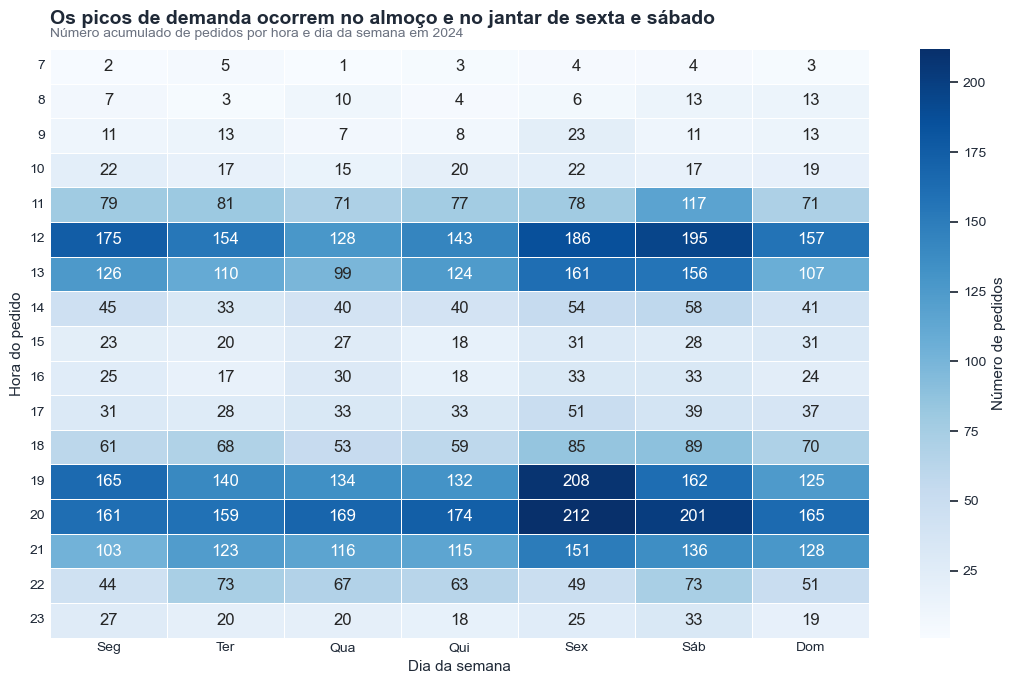

In [409]:
fig, ax = plt.subplots(figsize=(11, 7))

sns.heatmap(
    pedidos_hora_dia,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Número de pedidos"
    },
    ax=ax
)

adicionar_titulo(
    ax,
    "Os picos de demanda ocorrem no almoço e no jantar de sexta e sábado",
    "Número acumulado de pedidos por hora e dia da semana em 2024"
)

ax.set_xlabel("Dia da semana")
ax.set_ylabel("Hora do pedido")

ax.tick_params(
    axis="x",
    rotation=0,
    length=0
)

ax.tick_params(
    axis="y",
    rotation=0,
    length=0
)

plt.tight_layout()
plt.show()


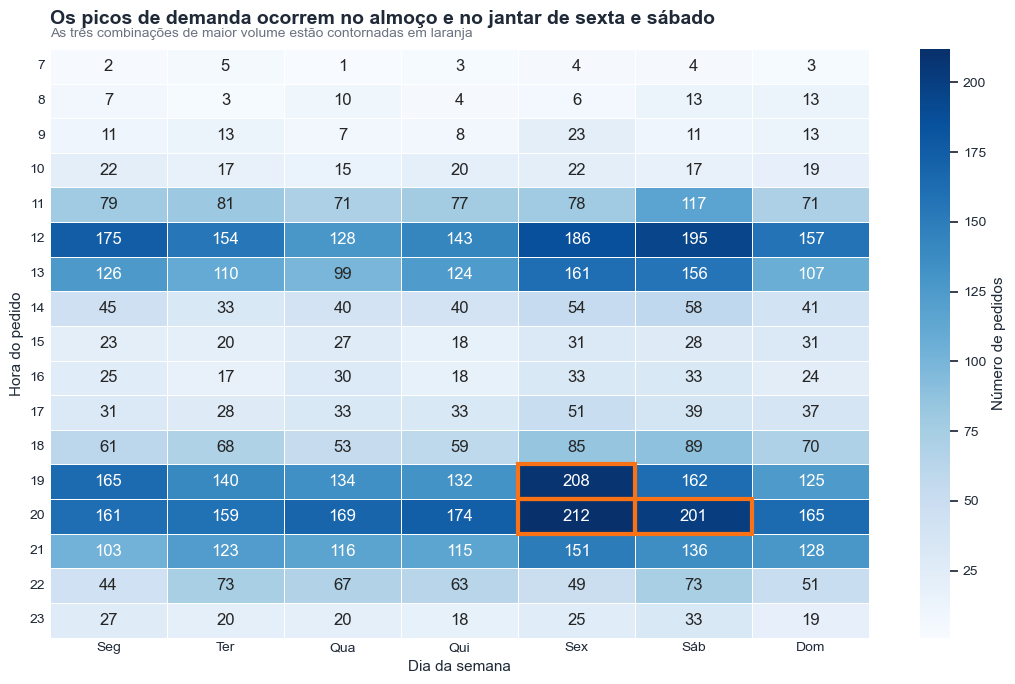

In [410]:
# Localiza os três maiores valores da tabela
maiores_picos = (
    pedidos_hora_dia
    .stack()
    .nlargest(3)
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.heatmap(
    pedidos_hora_dia,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Número de pedidos"
    },
    ax=ax
)

# Destaca as três células de maior volume
for (hora, dia_semana), valor in maiores_picos.items():
    linha = pedidos_hora_dia.index.get_loc(hora)
    coluna = pedidos_hora_dia.columns.get_loc(dia_semana)

    retangulo = plt.Rectangle(
        (coluna, linha),
        1,
        1,
        fill=False,
        edgecolor=COR_DESTAQUE,
        linewidth=3
    )

    ax.add_patch(retangulo)

adicionar_titulo(
    ax,
    "Os picos de demanda ocorrem no almoço e no jantar de sexta e sábado",
    "As três combinações de maior volume estão contornadas em laranja"
)

ax.set_xlabel("Dia da semana")
ax.set_ylabel("Hora do pedido")

ax.tick_params(
    axis="x",
    rotation=0,
    length=0
)

ax.tick_params(
    axis="y",
    rotation=0,
    length=0
)

plt.tight_layout()
plt.show()

### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

In [411]:
# Mantém somente os pedidos com tempo de entrega válido
dados_chuva_tempo = (
    df[["chuva", "tempo_entrega_min"]]
    .dropna()
    .copy()
)

# Cria rótulos mais claros
dados_chuva_tempo["condicao_chuva"] = (
    dados_chuva_tempo["chuva"]
    .map({
        False: "Sem chuva",
        True: "Com chuva"
    })
)

# Calcula as medianas
medianas_chuva = (
    dados_chuva_tempo
    .groupby("condicao_chuva")["tempo_entrega_min"]
    .median()
)

mediana_sem_chuva = medianas_chuva["Sem chuva"]
mediana_com_chuva = medianas_chuva["Com chuva"]

diferenca_mediana = (
    mediana_com_chuva - mediana_sem_chuva
)


In [412]:
# Título-conclusão baseado no resultado real
if diferenca_mediana > 0:
    titulo_chuva = (
        f"Na chuva, o tempo mediano de entrega aumenta "
        f"{diferenca_mediana:.1f} min"
    )
elif diferenca_mediana < 0:
    titulo_chuva = (
        f"Na chuva, o tempo mediano de entrega diminui "
        f"{abs(diferenca_mediana):.1f} min"
    )
else:
    titulo_chuva = (
        "O tempo mediano de entrega é igual com e sem chuva"
    )

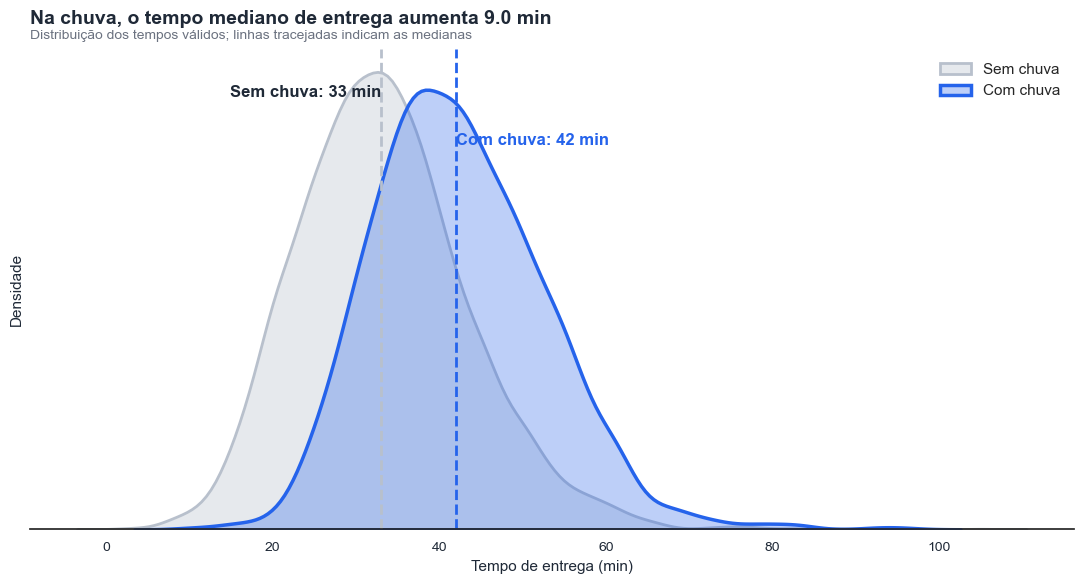

In [413]:
fig, ax = plt.subplots(figsize=(11, 6))

# Distribuição sem chuva
sns.kdeplot(
    data=dados_chuva_tempo[
        dados_chuva_tempo["condicao_chuva"] == "Sem chuva"
    ],
    x="tempo_entrega_min",
    color=CORES_CHUVA[False],
    fill=True,
    alpha=0.35,
    linewidth=2,
    common_norm=False,
    label="Sem chuva",
    ax=ax
)

# Distribuição com chuva
sns.kdeplot(
    data=dados_chuva_tempo[
        dados_chuva_tempo["condicao_chuva"] == "Com chuva"
    ],
    x="tempo_entrega_min",
    color=CORES_CHUVA[True],
    fill=True,
    alpha=0.30,
    linewidth=2.5,
    common_norm=False,
    label="Com chuva",
    ax=ax
)

# Mediana sem chuva
ax.axvline(
    mediana_sem_chuva,
    color=CORES_CHUVA[False],
    linestyle="--",
    linewidth=2
)

# Mediana com chuva
ax.axvline(
    mediana_com_chuva,
    color=CORES_CHUVA[True],
    linestyle="--",
    linewidth=2
)

# Rótulos das medianas
altura_maxima = ax.get_ylim()[1]

ax.text(
    mediana_sem_chuva,
    altura_maxima * 0.90,
    f"Sem chuva: {mediana_sem_chuva:.0f} min",
    color=COR_TEXTO,
    ha="right",
    fontweight="bold"
)

ax.text(
    mediana_com_chuva,
    altura_maxima * 0.80,
    f"Com chuva: {mediana_com_chuva:.0f} min",
    color=CORES_CHUVA[True],
    ha="left",
    fontweight="bold"
)

# Título e subtítulo
adicionar_titulo(
    ax,
    titulo_chuva,
    "Distribuição dos tempos válidos; linhas tracejadas indicam as medianas"
)

# Rótulos com unidade
ax.set_xlabel("Tempo de entrega (min)")
ax.set_ylabel("Densidade")

# Remove elementos desnecessários
ax.grid(False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    left=False,
    labelleft=False
)

ax.legend(
    title=None,
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()

In [414]:
resumo_chuva_tempo = (
    dados_chuva_tempo
    .groupby("condicao_chuva")["tempo_entrega_min"]
    .agg(
        pedidos="count",
        tempo_medio="mean",
        tempo_mediano="median"
    )
)

display(
    resumo_chuva_tempo.style
        .format({
            "pedidos": "{:.0f}",
            "tempo_medio": "{:.2f} min",
            "tempo_mediano": "{:.2f} min"
        })
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {
                "selector": "th",
                "props": [("text-align", "left")]
            }
        ])
)

,pedidos,tempo_medio,tempo_mediano
condicao_chuva,,,
Com chuva,2358,42.36 min,42.00 min
Sem chuva,5667,33.23 min,33.00 min


### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

In [415]:
# Mantém somente pedidos com tempo e avaliação válidos
dados_tempo_avaliacao = (
    df[["tempo_entrega_min", "avaliacao"]]
    .dropna()
    .copy()
)

# Limites e nomes das faixas
limites_tempo = list(range(0, 65, 5)) + [np.inf]

rotulos_tempo = [
    "0–5",
    "5–10",
    "10–15",
    "15–20",
    "20–25",
    "25–30",
    "30–35",
    "35–40",
    "40–45",
    "45–50",
    "50–55",
    "55–60",
    "60+"
]

# Cria as faixas de tempo
dados_tempo_avaliacao["faixa_tempo"] = pd.cut(
    dados_tempo_avaliacao["tempo_entrega_min"],
    bins=limites_tempo,
    labels=rotulos_tempo,
    right=False,
    include_lowest=True
)

# Resumo por faixa
avaliacao_por_faixa = (
    dados_tempo_avaliacao
    .groupby("faixa_tempo", observed=True)
    .agg(
        quantidade=("avaliacao", "count"),
        avaliacao_media=("avaliacao", "mean"),
        desvio_padrao=("avaliacao", "std")
    )
    .reset_index()
)

# Erro-padrão
avaliacao_por_faixa["erro_padrao"] = (
    avaliacao_por_faixa["desvio_padrao"]
    / np.sqrt(avaliacao_por_faixa["quantidade"])
)

# Intervalo de confiança de 95%
avaliacao_por_faixa["margem_erro_95"] = (
    stats.t.ppf(
        0.975,
        avaliacao_por_faixa["quantidade"] - 1
    )
    * avaliacao_por_faixa["erro_padrao"]
)

avaliacao_por_faixa["limite_inferior"] = (
    avaliacao_por_faixa["avaliacao_media"]
    - avaliacao_por_faixa["margem_erro_95"]
)

avaliacao_por_faixa["limite_superior"] = (
    avaliacao_por_faixa["avaliacao_media"]
    + avaliacao_por_faixa["margem_erro_95"]
)

display(
    avaliacao_por_faixa.style
        .format({
            "quantidade": "{:.0f}",
            "avaliacao_media": "{:.2f}",
            "desvio_padrao": "{:.2f}",
            "erro_padrao": "{:.3f}",
            "margem_erro_95": "{:.3f}",
            "limite_inferior": "{:.2f}",
            "limite_superior": "{:.2f}"
        })
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {
                "selector": "th",
                "props": [("text-align", "left")]
            }
        ])
)


faixa_tempo,quantidade,avaliacao_media,desvio_padrao,erro_padrao,margem_erro_95,limite_inferior,limite_superior
0–5,3,4.00,1.00,0.577,2.484,1.52,6.48
5–10,15,4.47,0.74,0.192,0.412,4.06,4.88
10–15,70,4.44,0.65,0.078,0.155,4.29,4.60
15–20,284,4.52,0.62,0.037,0.072,4.45,4.60
20–25,622,4.49,0.61,0.024,0.048,4.44,4.53
25–30,943,4.48,0.61,0.020,0.039,4.44,4.52
30–35,1248,4.49,0.62,0.018,0.034,4.46,4.53
35–40,1185,4.44,0.64,0.019,0.037,4.40,4.48
40–45,913,4.29,0.67,0.022,0.043,4.24,4.33
45–50,621,4.15,0.68,0.027,0.053,4.10,4.21


In [416]:
# Posição da faixa com maior avaliação média
posicao_pico = (
    avaliacao_por_faixa["avaliacao_media"]
    .idxmax()
)

# Primeira faixa após o pico
if posicao_pico < len(avaliacao_por_faixa) - 1:
    posicao_inicio_queda = posicao_pico + 1

    faixa_inicio_queda = (
        avaliacao_por_faixa.loc[
            posicao_inicio_queda,
            "faixa_tempo"
        ]
    )
else:
    posicao_inicio_queda = None
    faixa_inicio_queda = None

print(
    "Faixa com maior avaliação média:",
    avaliacao_por_faixa.loc[posicao_pico, "faixa_tempo"]
)

print(
    "Faixa a partir da qual a avaliação começa a cair:",
    faixa_inicio_queda
)

Faixa com maior avaliação média: 15–20
Faixa a partir da qual a avaliação começa a cair: 20–25


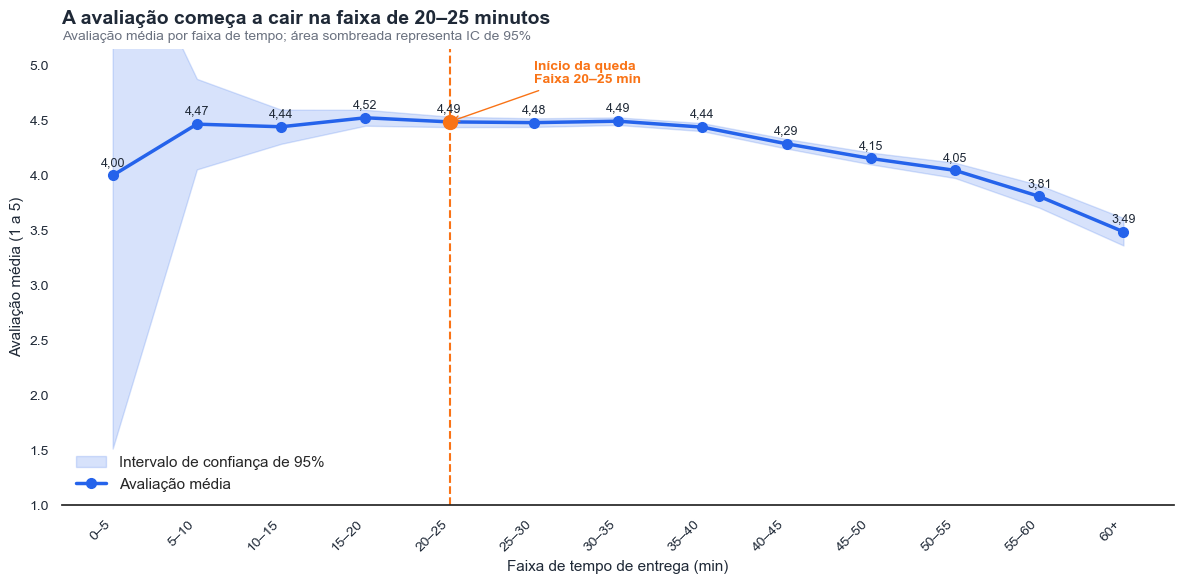

In [417]:
# Posições numéricas das faixas no gráfico
posicoes = np.arange(len(avaliacao_por_faixa))

fig, ax = plt.subplots(figsize=(12, 6))

# Intervalo de confiança
ax.fill_between(
    posicoes,
    avaliacao_por_faixa["limite_inferior"].to_numpy(),
    avaliacao_por_faixa["limite_superior"].to_numpy(),
    color=COR_PRINCIPAL,
    alpha=0.18,
    label="Intervalo de confiança de 95%"
)

# Avaliação média
ax.plot(
    posicoes,
    avaliacao_por_faixa["avaliacao_media"],
    color=COR_PRINCIPAL,
    marker="o",
    markersize=7,
    linewidth=2.5,
    label="Avaliação média"
)

# Destaca o início da queda
if posicao_inicio_queda is not None:
    avaliacao_inicio_queda = (
        avaliacao_por_faixa.loc[
            posicao_inicio_queda,
            "avaliacao_media"
        ]
    )

    ax.scatter(
        posicao_inicio_queda,
        avaliacao_inicio_queda,
        color=COR_DESTAQUE,
        s=100,
        zorder=5
    )

    ax.axvline(
        posicao_inicio_queda,
        color=COR_DESTAQUE,
        linestyle="--",
        linewidth=1.5
    )

    ax.annotate(
        f"Início da queda\nFaixa {faixa_inicio_queda} min",
        xy=(
            posicao_inicio_queda,
            avaliacao_inicio_queda
        ),
        xytext=(
            posicao_inicio_queda + 1,
            min(5, avaliacao_inicio_queda + 0.35)
        ),
        arrowprops={
            "arrowstyle": "->",
            "color": COR_DESTAQUE
        },
        color=COR_DESTAQUE,
        fontweight="bold",
        fontsize=10
    )

# Valores médios escritos nos pontos
for posicao, media in zip(
    posicoes,
    avaliacao_por_faixa["avaliacao_media"]
):
    ax.text(
        posicao,
        media + 0.06,
        f"{media:.2f}".replace(".", ","),
        ha="center",
        va="bottom",
        fontsize=9,
        color=COR_TEXTO
    )

# Título-conclusão calculado com o resultado
if faixa_inicio_queda is not None:
    titulo = (
        f"A avaliação começa a cair na faixa "
        f"de {faixa_inicio_queda} minutos"
    )
else:
    titulo = (
        "Não foi identificada queda após o pico "
        "da avaliação média"
    )

adicionar_titulo(
    ax,
    titulo,
    "Avaliação média por faixa de tempo; área sombreada representa IC de 95%"
)

# Eixos
ax.set_xlabel("Faixa de tempo de entrega (min)")
ax.set_ylabel("Avaliação média (1 a 5)")

ax.set_xticks(posicoes)
ax.set_xticklabels(
    avaliacao_por_faixa["faixa_tempo"],
    rotation=45,
    ha="right"
)

ax.set_ylim(1, 5.15)

# Limpeza visual
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.legend(
    frameon=False,
    loc="lower left"
)

plt.tight_layout()
plt.show()

### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

In [418]:
# Taxa mensal de uso de cupom
taxa_cupom_grafico = (
    df.groupby("mes")
      .agg(
          taxa_uso_cupom=("cupom", "mean")
      )
      .reset_index()
)

taxa_cupom_grafico["taxa_uso_cupom"] *= 100

# Percentual de clientes novos com e sem cupom
clientes_novos_cupom = (
    df.groupby("cupom")
      .agg(
          percentual_clientes_novos=("cliente_novo", "mean")
      )
      .reset_index()
)

clientes_novos_cupom["percentual_clientes_novos"] *= 100

clientes_novos_cupom["situacao_cupom"] = (
    clientes_novos_cupom["cupom"]
    .map({
        False: "Sem cupom",
        True: "Com cupom"
    })
)


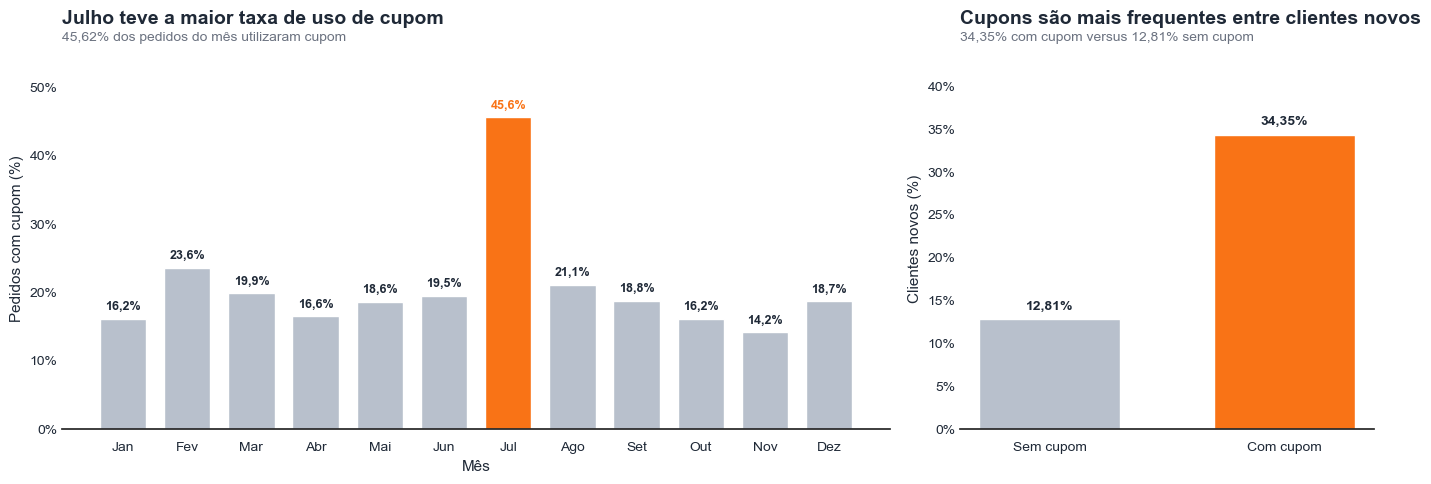

In [419]:
# Nomes dos meses
nomes_meses = [
    "Jan", "Fev", "Mar", "Abr",
    "Mai", "Jun", "Jul", "Ago",
    "Set", "Out", "Nov", "Dez"
]

# Cores do painel mensal: julho em destaque
cores_meses = [
    COR_DESTAQUE if mes == 7 else COR_NEUTRA
    for mes in taxa_cupom_grafico["mes"]
]

# Cores do painel com e sem cupom
cores_clientes = [
    CORES_CUPOM[False],
    CORES_CUPOM[True]
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    gridspec_kw={"width_ratios": [2, 1]}
)

# -------------------------------------------------
# Painel A: taxa mensal de uso de cupom
# -------------------------------------------------

ax1 = axes[0]

barras_meses = ax1.bar(
    taxa_cupom_grafico["mes"],
    taxa_cupom_grafico["taxa_uso_cupom"],
    color=cores_meses,
    width=0.72
)

# Escreve os percentuais nas barras
for barra, percentual in zip(
    barras_meses,
    taxa_cupom_grafico["taxa_uso_cupom"]
):
    ax1.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.8,
        f"{percentual:.1f}%".replace(".", ","),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        color=(
            COR_DESTAQUE
            if percentual == taxa_cupom_grafico.loc[
                taxa_cupom_grafico["mes"] == 7,
                "taxa_uso_cupom"
            ].iloc[0]
            else COR_TEXTO
        )
    )

ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(nomes_meses)

ax1.set_xlabel("Mês")
ax1.set_ylabel("Pedidos com cupom (%)")
ax1.yaxis.set_major_formatter(FORMATADOR_PERCENTUAL)

adicionar_titulo(
    ax1,
    "Julho teve a maior taxa de uso de cupom",
    "45,62% dos pedidos do mês utilizaram cupom"
)

ax1.set_ylim(
    0,
    taxa_cupom_grafico["taxa_uso_cupom"].max() + 10
)

# -------------------------------------------------
# Painel B: clientes novos com e sem cupom
# -------------------------------------------------

ax2 = axes[1]

barras_clientes = ax2.bar(
    clientes_novos_cupom["situacao_cupom"],
    clientes_novos_cupom["percentual_clientes_novos"],
    color=cores_clientes,
    width=0.6
)

# Escreve os percentuais nas barras
for barra, percentual in zip(
    barras_clientes,
    clientes_novos_cupom["percentual_clientes_novos"]
):
    ax2.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.8,
        f"{percentual:.2f}%".replace(".", ","),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color=COR_TEXTO
    )

ax2.set_xlabel("")
ax2.set_ylabel("Clientes novos (%)")
ax2.yaxis.set_major_formatter(FORMATADOR_PERCENTUAL)

adicionar_titulo(
    ax2,
    "Cupons são mais frequentes entre clientes novos",
    "34,35% com cupom versus 12,81% sem cupom"
)

ax2.set_ylim(
    0,
    clientes_novos_cupom[
        "percentual_clientes_novos"
    ].max() + 10
)

# -------------------------------------------------
# Limpeza visual dos dois painéis
# -------------------------------------------------

for ax in axes:
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

7.1: O histograma evidencia a assimetria do ticket e o afastamento entre média e mediana causado pelos pedidos de alto valor.

7.2: As barras horizontais permitem comparar diretamente a participação das cidades e destacar a concentração dos pedidos em São Paulo.

7.3: O boxplot compara mediana, dispersão e extremos, tornando intuitivas as diferenças de ticket entre as cozinhas.

7.4: O gráfico de linhas preserva a sequência temporal, enquanto a média móvel revela a tendência, a campanha de julho e a instabilidade de 14/08.

7.5: O mapa de calor transforma hora e dia em intensidade visual, fazendo os picos de almoço e jantar saltarem aos olhos.

7.6: As curvas de densidade sobrepostas evidenciam o deslocamento da distribuição do tempo de entrega entre dias com e sem chuva.

7.7: A linha com intervalo de confiança mostra a trajetória da avaliação conforme o tempo aumenta e comunica a incerteza em cada faixa.

7.8: Os dois painéis de barras conectam visualmente o pico de cupons em julho à maior presença de clientes novos entre pedidos com cupom.

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

In [420]:
colunas_correlacao = [
    "distancia_km",
    "tempo_entrega_min",
    "taxa_entrega",
    "valor_pedido",
    "avaliacao"
]

# Matriz de correlação de Pearson
correlacao_pearson = df[colunas_correlacao].corr(
    method="pearson"
)

# Matriz de correlação de Spearman
correlacao_spearman = df[colunas_correlacao].corr(
    method="spearman"
)


In [421]:
print("Correlação de Pearson:")

display(
    correlacao_pearson.style
        .format("{:.3f}")
        .background_gradient(
            cmap="RdBu_r",
            vmin=-1,
            vmax=1
        )
)

print("Correlação de Spearman:")

display(
    correlacao_spearman.style
        .format("{:.3f}")
        .background_gradient(
            cmap="RdBu_r",
            vmin=-1,
            vmax=1
        )
)

Correlação de Pearson:


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.000,0.704,0.578,-0.014,-0.228
tempo_entrega_min,0.704,1.000,0.418,-0.014,-0.287
taxa_entrega,0.578,0.418,1.000,0.015,-0.096
valor_pedido,-0.014,-0.014,0.015,1.000,-0.009
avaliacao,-0.228,-0.287,-0.096,-0.009,1.000


Correlação de Spearman:


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.000,0.653,0.789,-0.017,-0.168
tempo_entrega_min,0.653,1.000,0.522,-0.009,-0.244
taxa_entrega,0.789,0.522,1.000,0.015,-0.109
valor_pedido,-0.017,-0.009,0.015,1.000,0.005
avaliacao,-0.168,-0.244,-0.109,0.005,1.000


*Sua resposta aqui*

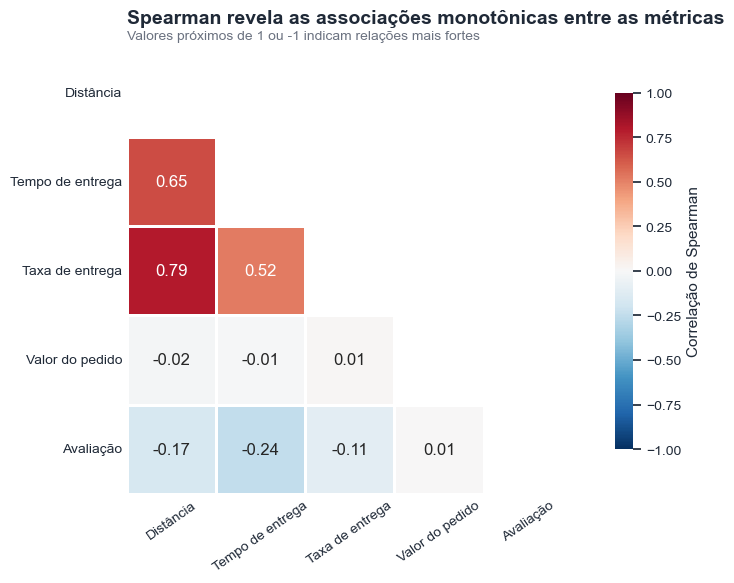

In [422]:
# Nomes mais claros para exibição no gráfico
nomes_correlacao = {
    "distancia_km": "Distância",
    "tempo_entrega_min": "Tempo de entrega",
    "taxa_entrega": "Taxa de entrega",
    "valor_pedido": "Valor do pedido",
    "avaliacao": "Avaliação"
}

spearman_grafico = correlacao_spearman.rename(
    index=nomes_correlacao,
    columns=nomes_correlacao
)

# Oculta a diagonal e o triângulo superior
mascara = np.triu(
    np.ones_like(
        spearman_grafico,
        dtype=bool
    ),
    k=0
)

fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    spearman_grafico,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.8,
    linecolor="white",
    square=True,
    cbar_kws={
        "label": "Correlação de Spearman",
        "shrink": 0.8
    },
    ax=ax
)

adicionar_titulo(
    ax,
    "Spearman revela as associações monotônicas entre as métricas",
    "Valores próximos de 1 ou -1 indicam relações mais fortes"
)

ax.set_xlabel("")
ax.set_ylabel("")

ax.tick_params(
    axis="x",
    rotation=35,
    length=0
)

ax.tick_params(
    axis="y",
    rotation=0,
    length=0
)

plt.tight_layout()
plt.show()

In [423]:
triangulo_inferior = correlacao_spearman.where(
    np.tril(
        np.ones(
            correlacao_spearman.shape,
            dtype=bool
        ),
        k=-1
    )
)

correlacoes_ordenadas = (
    triangulo_inferior
    .stack()
    .rename("correlacao_spearman")
    .reset_index()
    .rename(columns={
        "level_0": "variavel_1",
        "level_1": "variavel_2"
    })
)

correlacoes_ordenadas["correlacao_absoluta"] = (
    correlacoes_ordenadas["correlacao_spearman"].abs()
)

correlacoes_ordenadas = correlacoes_ordenadas.sort_values(
    "correlacao_absoluta",
    ascending=False
)

display(
    correlacoes_ordenadas.style
        .format({
            "correlacao_spearman": "{:.3f}",
            "correlacao_absoluta": "{:.3f}"
        })
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {
                "selector": "th",
                "props": [("text-align", "left")]
            }
        ])
)

variavel_1,variavel_2,correlacao_spearman,correlacao_absoluta
taxa_entrega,distancia_km,0.789,0.789
tempo_entrega_min,distancia_km,0.653,0.653
taxa_entrega,tempo_entrega_min,0.522,0.522
avaliacao,tempo_entrega_min,-0.244,0.244
avaliacao,distancia_km,-0.168,0.168
avaliacao,taxa_entrega,-0.109,0.109
valor_pedido,distancia_km,-0.017,0.017
valor_pedido,taxa_entrega,0.015,0.015
valor_pedido,tempo_entrega_min,-0.009,0.009
avaliacao,valor_pedido,0.005,0.005


### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

In [424]:
# Mantém somente pedidos com distância e tempo válidos
dados_dispersao = (
    df[
        [
            "distancia_km",
            "tempo_entrega_min",
            "chuva"
        ]
    ]
    .dropna()
    .sample(
        n=2000,
        random_state=42
    )
    .copy()
)

# Rótulos para o gráfico
dados_dispersao["condicao_chuva"] = (
    dados_dispersao["chuva"]
    .map({
        False: "Sem chuva",
        True: "Com chuva"
    })
)


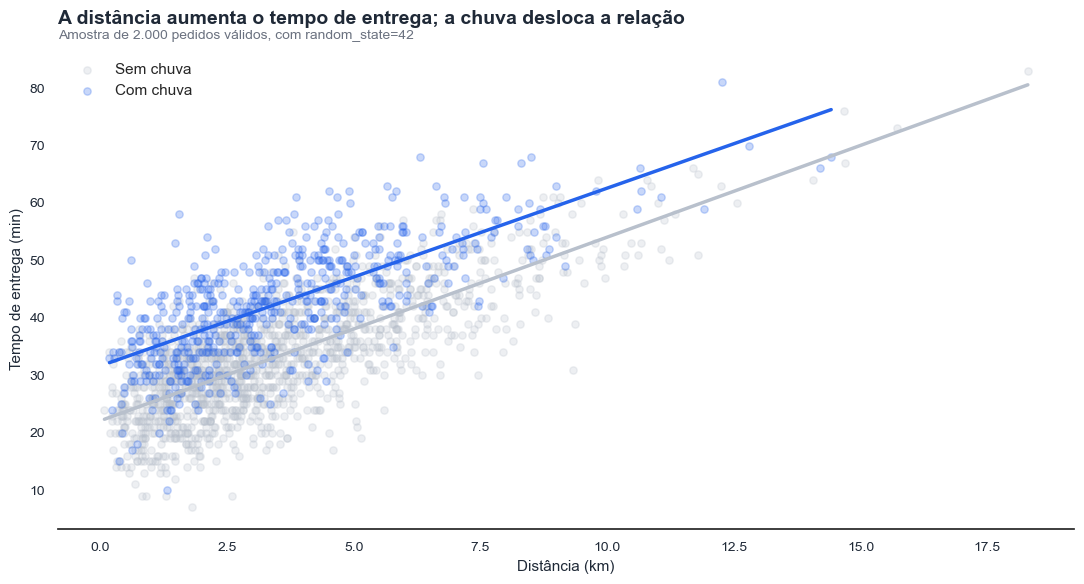

In [425]:
fig, ax = plt.subplots(figsize=(11, 6))

# Pontos e reta sem chuva
sns.regplot(
    data=dados_dispersao[
        dados_dispersao["chuva"] == False
    ],
    x="distancia_km",
    y="tempo_entrega_min",
    scatter_kws={
        "alpha": 0.25,
        "s": 28,
        "color": CORES_CHUVA[False]
    },
    line_kws={
        "color": CORES_CHUVA[False],
        "linewidth": 2.5
    },
    ci=None,
    label="Sem chuva",
    ax=ax
)

# Pontos e reta com chuva
sns.regplot(
    data=dados_dispersao[
        dados_dispersao["chuva"] == True
    ],
    x="distancia_km",
    y="tempo_entrega_min",
    scatter_kws={
        "alpha": 0.25,
        "s": 28,
        "color": CORES_CHUVA[True]
    },
    line_kws={
        "color": CORES_CHUVA[True],
        "linewidth": 2.5
    },
    ci=None,
    label="Com chuva",
    ax=ax
)

adicionar_titulo(
    ax,
    "A distância aumenta o tempo de entrega; a chuva desloca a relação",
    "Amostra de 2.000 pedidos válidos, com random_state=42"
)

ax.set_xlabel("Distância (km)")
ax.set_ylabel("Tempo de entrega (min)")

ax.legend(
    title=None,
    frameon=False,
    loc="upper left"
)

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

In [426]:
resultados_retas = []

for condicao, grupo in dados_dispersao.groupby("condicao_chuva"):

    inclinacao, intercepto = np.polyfit(
        grupo["distancia_km"],
        grupo["tempo_entrega_min"],
        1
    )

    resultados_retas.append({
        "condicao_chuva": condicao,
        "inclinacao_min_por_km": inclinacao,
        "intercepto": intercepto,
        "quantidade_pedidos": len(grupo)
    })

retas_chuva = pd.DataFrame(resultados_retas)

display(
    retas_chuva.style
        .format({
            "inclinacao_min_por_km": "{:.2f}",
            "intercepto": "{:.2f}",
            "quantidade_pedidos": "{:.0f}"
        })
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {
                "selector": "th",
                "props": [("text-align", "left")]
            }
        ])
)

condicao_chuva,inclinacao_min_por_km,intercepto,quantidade_pedidos
Com chuva,3.09,31.65,562
Sem chuva,3.20,22.09,1438


As duas retas apresentam inclinação positiva, confirmando que o tempo de entrega aumenta conforme a distância cresce. Sem chuva, cada quilômetro adicional está associado a aproximadamente 3,20 minutos a mais; com chuva, a aproximadamente 3,09 minutos.

Como as inclinações são muito próximas, a chuva não altera de forma relevante o efeito da distância sobre o tempo de entrega. A principal mudança está no intercepto: 31,65 minutos com chuva, contra 22,09 minutos sem chuva, uma diferença de 9,56 minutos.

Portanto, a chuva desloca a reta para cima, mantendo-a quase paralela à reta sem chuva. Para uma mesma distância, o modelo estima entregas aproximadamente 9,5 minutos mais demoradas quando chove. Essa conclusão descreve uma associação observada na amostra de 2.000 pedidos, e não comprova causalidade.

### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

In [427]:
# Mantém apenas registros com distância disponível
dados_taxa_distancia = (
    df[["distancia_km", "taxa_entrega"]]
    .dropna()
    .copy()
)

# Identifica pedidos com frete grátis e frete pago
dados_taxa_distancia["situacao_frete"] = np.where(
    dados_taxa_distancia["taxa_entrega"] == 0,
    "Frete grátis",
    "Frete pago"
)

# Correlação na base completa
correlacao_geral = dados_taxa_distancia[
    ["distancia_km", "taxa_entrega"]
].corr(method="pearson").iloc[0, 1]

# Correlação somente nos pedidos com frete pago
dados_frete_pago = dados_taxa_distancia[
    dados_taxa_distancia["taxa_entrega"] > 0
]

correlacao_frete_pago = dados_frete_pago[
    ["distancia_km", "taxa_entrega"]
].corr(method="pearson").iloc[0, 1]

# Quantidade de pedidos em cada grupo
quantidade_frete_gratis = (
    dados_taxa_distancia["taxa_entrega"] == 0
).sum()

quantidade_frete_pago = (
    dados_taxa_distancia["taxa_entrega"] > 0
).sum()

resultado_correlacao = pd.DataFrame({
    "grupo": [
        "Todos os pedidos",
        "Somente frete pago",
        "Frete grátis"
    ],
    "quantidade": [
        len(dados_taxa_distancia),
        quantidade_frete_pago,
        quantidade_frete_gratis
    ],
    "correlacao_pearson": [
        correlacao_geral,
        correlacao_frete_pago,
        np.nan
    ]
})

display(
    resultado_correlacao.style
        .format({
            "quantidade": "{:.0f}",
            "correlacao_pearson": "{:.3f}",
        }, na_rep="Não definida")
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {
                "selector": "th",
                "props": [("text-align", "left")]
            }
        ])
)


grupo,quantidade,correlacao_pearson
Todos os pedidos,7736,0.578
Somente frete pago,6861,1.000
Frete grátis,875,Não definida


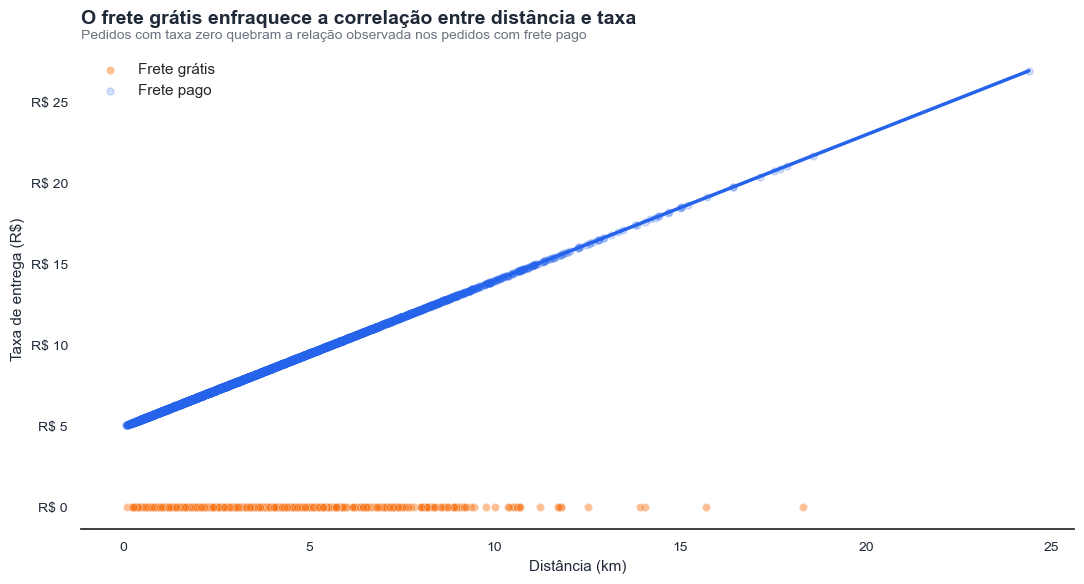

In [428]:
fig, ax = plt.subplots(figsize=(11, 6))

# Pedidos com frete grátis
sns.scatterplot(
    data=dados_taxa_distancia[
        dados_taxa_distancia["taxa_entrega"] == 0
    ],
    x="distancia_km",
    y="taxa_entrega",
    color=COR_DESTAQUE,
    alpha=0.45,
    s=35,
    label="Frete grátis",
    ax=ax
)

# Pedidos com frete pago
sns.regplot(
    data=dados_frete_pago,
    x="distancia_km",
    y="taxa_entrega",
    scatter_kws={
        "color": COR_PRINCIPAL,
        "alpha": 0.20,
        "s": 25
    },
    line_kws={
        "color": COR_PRINCIPAL,
        "linewidth": 2.5
    },
    ci=None,
    label="Frete pago",
    ax=ax
)

adicionar_titulo(
    ax,
    "O frete grátis enfraquece a correlação entre distância e taxa",
    "Pedidos com taxa zero quebram a relação observada nos pedidos com frete pago"
)

ax.set_xlabel("Distância (km)")
ax.set_ylabel("Taxa de entrega (R$)")
ax.yaxis.set_major_formatter(FORMATADOR_REAIS)

ax.legend(
    title=None,
    frameon=False,
    loc="upper left"
)

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

In [429]:
inclinacao_taxa, intercepto_taxa = np.polyfit(
    dados_frete_pago["distancia_km"],
    dados_frete_pago["taxa_entrega"],
    1
)

print(
    "Correlação geral:",
    round(correlacao_geral, 3)
)

print(
    "Correlação somente com frete pago:",
    round(correlacao_frete_pago, 3)
)

print(
    "Inclinação da reta:",
    round(inclinacao_taxa, 3),
    "R$ por km"
)

print(
    "Intercepto da reta:",
    round(intercepto_taxa, 3),
    "R$"
)

Correlação geral: 0.578
Correlação somente com frete pago: 1.0
Inclinação da reta: 0.9 R$ por km
Intercepto da reta: 4.99 R$


A correlação de Pearson entre distancia_km e taxa_entrega foi de 0,578 quando todos os pedidos foram considerados, indicando uma relação positiva moderada. Esse valor é reduzido pelos pedidos com frete grátis, nos quais taxa_entrega é igual a zero independentemente da distância.

Ao considerar somente os pedidos com frete pago, a correlação aumentou para 1,000, revelando uma relação linear perfeita. A reta estimada foi:

taxa_entrega = 4,99 + 0,90 × distancia_km

Isso significa que a taxa possui uma parcela inicial de aproximadamente R$ 4,99 e aumenta cerca de R$ 0,90 por quilômetro. Os pedidos com frete grátis enfraquecem a correlação geral porque uma decisão comercial faz a taxa permanecer em zero mesmo quando a distância varia.

Essa relação permitiria estimar e preencher os valores NaN de distancia_km nos pedidos com taxa de entrega maior que zero, invertendo a equação:

distancia_km = (taxa_entrega - 4,99) / 0,90

Porém, os NaN dos pedidos com frete grátis não poderiam ser estimados por essa fórmula, pois uma taxa de R$ 0,00 pode corresponder a diferentes distâncias. Além disso, qualquer distância preenchida dessa maneira deveria ser identificada como estimada, e não como uma distância observada no sistema.

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

1. Distância × tempo de entrega: é razoável supor que distâncias maiores contribuam para entregas mais demoradas, mas a correlação observada não comprova que a distância seja a única causa do aumento no tempo. A chuva é uma possível variável confundidora, pois está associada a tempos maiores e pode afetar simultaneamente o deslocamento dos entregadores. Outros fatores não registrados, como trânsito, disponibilidade de entregadores e tempo de preparo do restaurante, também podem explicar parte da relação.

2. Uso de cupom × cliente novo: clientes novos representaram 34,35% dos pedidos com cupom, contra 12,81% dos pedidos sem cupom. Porém, não é correto concluir somente com essa associação que o cupom causou a entrada de novos clientes. A campanha “Julho de cupons” é uma possível variável confundidora, pois pode ter concentrado simultaneamente ações de aquisição, publicidade e maior distribuição de cupons. Assim, tanto o aumento de clientes novos quanto o maior uso de cupons podem decorrer da campanha, e não necessariamente de uma relação causal direta entre as duas variáveis.

Portanto, as análises mostram associações compatíveis com hipóteses de negócio, mas a causalidade exigiria controles adicionais ou um experimento, como a comparação entre grupos semelhantes com e sem exposição ao cupom.

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [430]:
ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [431]:
# Separa os tempos válidos dos dois grupos
tempo_com_chuva = (
    df.loc[df["chuva"], "tempo_entrega_min"]
    .dropna()
)

tempo_sem_chuva = (
    df.loc[~df["chuva"], "tempo_entrega_min"]
    .dropna()
)

# Teste de Mann-Whitney unilateral
estatistica_h1, p_valor_h1 = stats.mannwhitneyu(
    tempo_com_chuva,
    tempo_sem_chuva,
    alternative="greater"
)

# Medianas dos grupos
mediana_com_chuva_h1 = tempo_com_chuva.median()
mediana_sem_chuva_h1 = tempo_sem_chuva.median()

# Tamanho de efeito em unidade de negócio
efeito_h1 = (
    mediana_com_chuva_h1
    - mediana_sem_chuva_h1
)

# Decisão ao nível de significância de 5%
decisao_h1 = (
    "Rejeitar H0"
    if p_valor_h1 < ALFA
    else "Não rejeitar H0"
)

# Adiciona o resultado à lista definida pelo projeto
resultados.append({
    "hipotese": "H1",
    "teste": "Mann-Whitney unilateral",
    "estatistica": estatistica_h1,
    "p_valor": p_valor_h1,
    "efeito": efeito_h1,
    "decisao": decisao_h1
})

# Apresenta os resultados
print("Mediana com chuva:", f"{mediana_com_chuva_h1:.2f} min")
print("Mediana sem chuva:", f"{mediana_sem_chuva_h1:.2f} min")
print("Estatística do teste:", f"{estatistica_h1:.2f}")
print("p-valor:", f"{p_valor_h1:.6g}")
print("Tamanho de efeito:", f"{efeito_h1:.2f} min")
print("Decisão:", decisao_h1)

Mediana com chuva: 42.00 min
Mediana sem chuva: 33.00 min
Estatística do teste: 9908765.00
p-valor: 6.21202e-256
Tamanho de efeito: 9.00 min
Decisão: Rejeitar H0


O teste de Mann-Whitney unilateral apresentou estatística de 9.908.765,00 e p-valor de aproximadamente 6,21 × 10⁻²⁵⁶. A mediana do tempo de entrega foi de 42 minutos em dias com chuva e 33 minutos em dias sem chuva, uma diferença de 9 minutos. Como o p-valor é menor que 0,05, rejeitamos H0 e concluímos que há evidência estatística de que as entregas demoram mais quando chove. Para o negócio, a chuva está associada a um aumento operacionalmente relevante de 9 minutos no tempo mediano de entrega, indicando a necessidade de reforçar a capacidade ou ajustar a promessa de prazo nesses dias.

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [432]:
# Separa os valores dos pedidos com e sem cupom
ticket_com_cupom = (
    df.loc[df["cupom"], "valor_pedido"]
    .dropna()
)

ticket_sem_cupom = (
    df.loc[~df["cupom"], "valor_pedido"]
    .dropna()
)

# Teste de Mann-Whitney bilateral
estatistica_h2, p_valor_h2 = stats.mannwhitneyu(
    ticket_com_cupom,
    ticket_sem_cupom,
    alternative="two-sided"
)

# Medianas dos dois grupos
mediana_com_cupom_h2 = ticket_com_cupom.median()
mediana_sem_cupom_h2 = ticket_sem_cupom.median()

# Tamanho de efeito em unidade de negócio
efeito_h2 = (
    mediana_com_cupom_h2
    - mediana_sem_cupom_h2
)

# Decisão ao nível de significância de 5%
decisao_h2 = (
    "Rejeitar H0"
    if p_valor_h2 < ALFA
    else "Não rejeitar H0"
)

# Adiciona o resultado à lista definida pelo projeto
resultados.append({
    "hipotese": "H2",
    "teste": "Mann-Whitney bilateral",
    "estatistica": estatistica_h2,
    "p_valor": p_valor_h2,
    "efeito": efeito_h2,
    "decisao": decisao_h2
})

# Apresenta os resultados
print(
    "Mediana com cupom:",
    f"R$ {mediana_com_cupom_h2:.2f}"
)

print(
    "Mediana sem cupom:",
    f"R$ {mediana_sem_cupom_h2:.2f}"
)

print(
    "Estatística do teste:",
    f"{estatistica_h2:.2f}"
)

print(
    "p-valor:",
    f"{p_valor_h2:.6g}"
)

print(
    "Tamanho de efeito:",
    f"R$ {efeito_h2:.2f}"
)

print(
    "Decisão:",
    decisao_h2
)


Mediana com cupom: R$ 57.22
Mediana sem cupom: R$ 62.82
Estatística do teste: 4777274.50
p-valor: 3.18912e-14
Tamanho de efeito: R$ -5.60
Decisão: Rejeitar H0


O teste de Mann-Whitney bilateral apresentou estatística de 4.777.274,50 e p-valor de aproximadamente 3,19 × 10⁻¹⁴. O ticket mediano foi de R$ 57,22 nos pedidos com cupom e de R$ 62,82 nos pedidos sem cupom, uma diferença de R$ 5,60 a menos para o grupo com cupom. Como o p-valor é menor que 0,05, rejeitamos H0 e concluímos que há evidência estatística de diferença no ticket entre os dois grupos. Para o negócio, o uso de cupom está associado a um ticket típico menor, mas essa diferença não comprova que o cupom causou a redução, pois o perfil dos pedidos e dos clientes pode ser diferente entre os grupos. O teste t de Student/Welch sobre o valor bruto seria frágil porque compara médias, enquanto valor_pedido apresenta forte assimetria e pedidos extremamente altos que podem distorcer essa medida; por isso, adotamos o teste de Mann-Whitney e a diferença entre medianas, ou, como análise complementar, poderíamos aplicar o teste de Welch ao logaritmo do ticket.

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [433]:
# Mantém somente pedidos com tempo e avaliação válidos
dados_h3 = (
    df[["tempo_entrega_min", "avaliacao"]]
    .dropna()
    .copy()
)

# Correlação de Spearman unilateral para relação negativa
rho_h3, p_valor_spearman_h3 = stats.spearmanr(
    dados_h3["tempo_entrega_min"],
    dados_h3["avaliacao"],
    alternative="less"
)

# Separa os pedidos pelo limite de 35 minutos
avaliacao_ate_35_h3 = (
    dados_h3.loc[
        dados_h3["tempo_entrega_min"] <= 35,
        "avaliacao"
    ]
)

avaliacao_acima_35_h3 = (
    dados_h3.loc[
        dados_h3["tempo_entrega_min"] > 35,
        "avaliacao"
    ]
)

# Mann-Whitney unilateral:
# avaliação até 35 min maior que avaliação acima de 35 min
estatistica_mw_h3, p_valor_mw_h3 = stats.mannwhitneyu(
    avaliacao_ate_35_h3,
    avaliacao_acima_35_h3,
    alternative="greater"
)

# Médias e medianas para interpretação do negócio
media_ate_35_h3 = avaliacao_ate_35_h3.mean()
media_acima_35_h3 = avaliacao_acima_35_h3.mean()

mediana_ate_35_h3 = avaliacao_ate_35_h3.median()
mediana_acima_35_h3 = avaliacao_acima_35_h3.median()

# Efeito em pontos de avaliação
efeito_h3 = media_ate_35_h3 - media_acima_35_h3

# Tamanho de efeito padronizado: correlação bisserial de postos
n_ate_35_h3 = len(avaliacao_ate_35_h3)
n_acima_35_h3 = len(avaliacao_acima_35_h3)

efeito_padronizado_h3 = (
    2 * estatistica_mw_h3
    / (n_ate_35_h3 * n_acima_35_h3)
) - 1

# A decisão considera os dois resultados
decisao_h3 = (
    "Rejeitar H0"
    if (
        p_valor_spearman_h3 < ALFA
        and p_valor_mw_h3 < ALFA
    )
    else "Não rejeitar H0"
)

# Adiciona um único dicionário para H3
resultados.append({
    "hipotese": "H3",
    "teste": "Spearman unilateral + Mann-Whitney unilateral",
    "estatistica": (
        f"rho={rho_h3:.4f}; U={estatistica_mw_h3:.2f}"
    ),
    "p_valor": (
        f"Spearman={p_valor_spearman_h3:.6g}; "
        f"Mann-Whitney={p_valor_mw_h3:.6g}"
    ),
    "efeito": (
        f"{efeito_h3:.3f} ponto de avaliação; "
        f"r bisserial={efeito_padronizado_h3:.4f}"
    ),
    "decisao": decisao_h3
})

# Apresenta os resultados
print("Correlação de Spearman:")
print(f"rho: {rho_h3:.4f}")
print(f"p-valor: {p_valor_spearman_h3:.6g}")

print("\nComparação das avaliações:")
print(f"Média até 35 min: {media_ate_35_h3:.3f}")
print(f"Média acima de 35 min: {media_acima_35_h3:.3f}")
print(f"Mediana até 35 min: {mediana_ate_35_h3:.2f}")
print(f"Mediana acima de 35 min: {mediana_acima_35_h3:.2f}")

print("\nTeste de Mann-Whitney:")
print(f"Estatística U: {estatistica_mw_h3:.2f}")
print(f"p-valor: {p_valor_mw_h3:.6g}")

print("\nTamanho de efeito:")
print(f"Diferença média: {efeito_h3:.3f} ponto")
print(f"Correlação bisserial de postos: {efeito_padronizado_h3:.4f}")

print("\nDecisão:", decisao_h3)


Correlação de Spearman:
rho: -0.2444
p-valor: 7.75072e-92

Comparação das avaliações:
Média até 35 min: 4.488
Média acima de 35 min: 4.203
Mediana até 35 min: 5.00
Mediana acima de 35 min: 4.00

Teste de Mann-Whitney:
Estatística U: 6766415.50
p-valor: 6.31603e-62

Tamanho de efeito:
Diferença média: 0.285 ponto
Correlação bisserial de postos: 0.2120

Decisão: Rejeitar H0


A correlação de Spearman apresentou rho = -0,2444 e p-valor de aproximadamente 7,75 × 10⁻⁹², indicando uma associação negativa entre o tempo de entrega e a avaliação. Na comparação por grupos, os pedidos entregues em até 35 minutos tiveram avaliação média de 4,488 e mediana de 5, enquanto aqueles entregues acima de 35 minutos tiveram média de 4,203 e mediana de 4. O teste de Mann-Whitney unilateral apresentou estatística de 6.766.415,50 e p-valor de aproximadamente 6,32 × 10⁻⁶². A diferença média foi de 0,285 ponto de avaliação, com correlação bisserial de postos de 0,2120, indicando efeito de pequena magnitude. Como os dois p-valores são menores que 0,05, rejeitamos H0. Para o negócio, entregas mais demoradas tendem a receber avaliações menores, e ultrapassar 35 minutos está associado a uma redução média de aproximadamente 0,29 ponto na nota, o que reforça a importância de controlar os atrasos para proteger a satisfação dos clientes.

### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [434]:
# Cria os grupos de valor_pedido por tipo de cozinha
grupos_h4 = [
    grupo["valor_pedido"].dropna().to_numpy()
    for _, grupo in df.groupby("tipo_cozinha")
]

# Teste principal: Kruskal-Wallis
estatistica_kruskal_h4, p_valor_kruskal_h4 = stats.kruskal(
    *grupos_h4
)

# ANOVA de uma via
estatistica_anova_h4, p_valor_anova_h4 = stats.f_oneway(
    *grupos_h4
)

# Quantidades necessárias para os tamanhos de efeito
n_h4 = df["valor_pedido"].notna().sum()
k_h4 = df["tipo_cozinha"].nunique()

# Tamanho de efeito do Kruskal-Wallis: epsilon ao quadrado
epsilon_quadrado_h4 = (
    (estatistica_kruskal_h4 - k_h4 + 1)
    / (n_h4 - k_h4)
)

# Tamanho de efeito da ANOVA: eta ao quadrado
media_geral_h4 = df["valor_pedido"].mean()

soma_quadrados_entre_h4 = sum(
    len(grupo) * (grupo.mean() - media_geral_h4) ** 2
    for grupo in grupos_h4
)

soma_quadrados_total_h4 = (
    (df["valor_pedido"] - media_geral_h4) ** 2
).sum()

eta_quadrado_h4 = (
    soma_quadrados_entre_h4
    / soma_quadrados_total_h4
)

# Medianas por tipo de cozinha
medianas_h4 = (
    df.groupby("tipo_cozinha")["valor_pedido"]
      .median()
      .sort_values(ascending=False)
)

# Efeito em unidade de negócio
diferenca_mediana_h4 = (
    medianas_h4.max() - medianas_h4.min()
)

# Decisão baseada no teste principal
decisao_h4 = (
    "Rejeitar H0"
    if p_valor_kruskal_h4 < ALFA
    else "Não rejeitar H0"
)

# Adiciona um dicionário à lista resultados
resultados.append({
    "hipotese": "H4",
    "teste": "Kruskal-Wallis e ANOVA de uma via",
    "estatistica": (
        f"H={estatistica_kruskal_h4:.4f}; "
        f"F={estatistica_anova_h4:.4f}"
    ),
    "p_valor": (
        f"Kruskal={p_valor_kruskal_h4:.6g}; "
        f"ANOVA={p_valor_anova_h4:.6g}"
    ),
    "efeito": (
        f"epsilon²={epsilon_quadrado_h4:.4f}; "
        f"eta²={eta_quadrado_h4:.4f}; "
        f"diferença entre medianas=R$ {diferenca_mediana_h4:.2f}"
    ),
    "decisao": decisao_h4
})

# Apresenta os resultados
print("Kruskal-Wallis:")
print(f"Estatística H: {estatistica_kruskal_h4:.4f}")
print(f"p-valor: {p_valor_kruskal_h4:.6g}")

print("\nANOVA de uma via:")
print(f"Estatística F: {estatistica_anova_h4:.4f}")
print(f"p-valor: {p_valor_anova_h4:.6g}")

print("\nTamanhos de efeito:")
print(f"Epsilon ao quadrado: {epsilon_quadrado_h4:.4f}")
print(f"Eta ao quadrado: {eta_quadrado_h4:.4f}")
print(
    "Diferença entre a maior e a menor mediana:",
    f"R$ {diferenca_mediana_h4:.2f}"
)

print("\nMedianas por tipo de cozinha:")
display(
    medianas_h4
        .rename("ticket_mediano")
        .to_frame()
        .style
        .format({"ticket_mediano": "R$ {:.2f}"})
)

print("\nDecisão:", decisao_h4)


Kruskal-Wallis:
Estatística H: 3272.5818
p-valor: 0

ANOVA de uma via:
Estatística F: 286.8198
p-valor: 2.93578e-283

Tamanhos de efeito:
Epsilon ao quadrado: 0.4058
Eta ao quadrado: 0.1512
Diferença entre a maior e a menor mediana: R$ 69.55

Medianas por tipo de cozinha:


,ticket_mediano
tipo_cozinha,
Japonesa,R$ 107.97
Pizza,R$ 74.31
Hambúrguer,R$ 61.67
Saudável,R$ 53.73
Brasileira,R$ 47.82
Doces,R$ 38.42



Decisão: Rejeitar H0


O teste de Kruskal-Wallis apresentou estatística H = 3.272,5818 e p-valor reportado pelo Python como 0, indicando um valor extremamente pequeno. A ANOVA de uma via confirmou a existência de diferenças entre os grupos, com F = 286,8198 e p-valor de aproximadamente 2,94 × 10⁻²⁸³. O tamanho de efeito foi expressivo: epsilon² = 0,4058 no Kruskal-Wallis e eta² = 0,1512 na ANOVA, mostrando que o tipo de cozinha explica uma parcela relevante da variação do ticket. A cozinha Japonesa apresentou o maior ticket mediano, de R$ 107,97, enquanto Doces apresentou o menor, de R$ 38,42, uma diferença de R$ 69,55. Como os p-valores são menores que 0,05, rejeitamos H0 e concluímos que o ticket varia conforme o tipo de cozinha. Para o negócio, o tipo de cozinha é uma característica importante na definição do valor típico do pedido, com diferenças relevantes entre as categorias. A ANOVA reforça o resultado, mas deve ser interpretada com cautela devido à forte assimetria e aos valores extremos de valor_pedido; por isso, o Kruskal-Wallis é o teste principal.

### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [435]:
# Tabela de frequências observadas
tabela_h5 = pd.crosstab(
    df["cidade"],
    df["forma_pagamento"]
)

# Teste qui-quadrado de independência
estatistica_h5, p_valor_h5, gl_h5, frequencias_esperadas_h5 = (
    stats.chi2_contingency(tabela_h5)
)

# Tabela de frequências esperadas
tabela_esperadas_h5 = pd.DataFrame(
    frequencias_esperadas_h5,
    index=tabela_h5.index,
    columns=tabela_h5.columns
)

# V de Cramér
n_h5 = tabela_h5.to_numpy().sum()

menor_dimensao_h5 = min(
    tabela_h5.shape[0] - 1,
    tabela_h5.shape[1] - 1
)

v_cramer_h5 = np.sqrt(
    estatistica_h5 /
    (n_h5 * menor_dimensao_h5)
)

# Decisão
decisao_h5 = (
    "Rejeitar H0"
    if p_valor_h5 < ALFA
    else "Não rejeitar H0"
)

# Registra H5 na lista de resultados
resultados.append({
    "hipotese": "H5",
    "teste": "Qui-quadrado de independência",
    "estatistica": estatistica_h5,
    "p_valor": p_valor_h5,
    "efeito": v_cramer_h5,
    "decisao": decisao_h5
})

# Resultados
print("Tabela de frequências observadas:")
display(tabela_h5)

print("\nTabela de frequências esperadas:")
display(
    tabela_esperadas_h5.style
        .format("{:.2f}")
)

print("\nResultado do teste:")
print(f"Estatística qui-quadrado: {estatistica_h5:.4f}")
print(f"Graus de liberdade: {gl_h5}")
print(f"p-valor: {p_valor_h5:.6g}")
print(f"Menor frequência esperada: {frequencias_esperadas_h5.min():.2f}")
print(f"V de Cramér: {v_cramer_h5:.4f}")
print(f"Decisão: {decisao_h5}")


Tabela de frequências observadas:


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,755,112,532,233
Rio de Janeiro,1078,163,785,345
São Paulo,1809,286,1316,644



Tabela de frequências esperadas:


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,737.62,113.62,533.27,247.49
Rio de Janeiro,1071.63,165.07,774.74,359.56
São Paulo,1832.75,282.31,1325.00,614.94



Resultado do teste:
Estatística qui-quadrado: 3.8641
Graus de liberdade: 6
p-valor: 0.695062
Menor frequência esperada: 113.62
V de Cramér: 0.0155
Decisão: Não rejeitar H0


In [436]:
# Tabela de frequências observadas
tabela_contraste = pd.crosstab(
    df["cupom"],
    df["cliente_novo"]
)

# Teste qui-quadrado de independência
estatistica_contraste, p_valor_contraste, gl_contraste, esperadas_contraste = (
    stats.chi2_contingency(tabela_contraste)
)

# Tabela de frequências esperadas
tabela_esperadas_contraste = pd.DataFrame(
    esperadas_contraste,
    index=tabela_contraste.index,
    columns=tabela_contraste.columns
)

# V de Cramér
n_contraste = tabela_contraste.to_numpy().sum()

menor_dimensao_contraste = min(
    tabela_contraste.shape[0] - 1,
    tabela_contraste.shape[1] - 1
)

v_cramer_contraste = np.sqrt(
    estatistica_contraste /
    (n_contraste * menor_dimensao_contraste)
)

# Decisão do contraste
decisao_contraste = (
    "Rejeitar H0"
    if p_valor_contraste < ALFA
    else "Não rejeitar H0"
)

# Resultados
print("Tabela observada — cupom × cliente_novo:")
display(tabela_contraste)

print("\nTabela esperada — cupom × cliente_novo:")
display(
    tabela_esperadas_contraste.style
        .format("{:.2f}")
)

print("\nResultado do contraste:")
print(f"Estatística qui-quadrado: {estatistica_contraste:.4f}")
print(f"Graus de liberdade: {gl_contraste}")
print(f"p-valor: {p_valor_contraste:.6g}")
print(f"Menor frequência esperada: {esperadas_contraste.min():.2f}")
print(f"V de Cramér: {v_cramer_contraste:.4f}")
print(f"Decisão: {decisao_contraste}")

Tabela observada — cupom × cliente_novo:


cliente_novo,False,True
cupom,,
False,5536,813
True,1122,587



Tabela esperada — cupom × cliente_novo:


cliente_novo,False,True
cupom,,
False,5245.92,1103.08
True,1412.08,296.92



Resultado do contraste:
Estatística qui-quadrado: 433.8032
Graus de liberdade: 1
p-valor: 2.41617e-96
Menor frequência esperada: 296.92
V de Cramér: 0.2320
Decisão: Rejeitar H0


O teste qui-quadrado de independência entre cidade e forma_pagamento apresentou estatística de 3,8641, com 6 graus de liberdade e p-valor de 0,6951. Todas as frequências esperadas ficaram acima de 5, sendo a menor igual a 113,62, portanto o requisito do teste foi atendido. Como o p-valor é maior que 0,05, não rejeitamos H0: não há evidência estatística de associação entre cidade e forma de pagamento. O V de Cramér de 0,0155 indica uma associação praticamente nula, confirmando que as pequenas diferenças observadas entre as cidades não possuem relevância prática. Para o negócio, as três cidades apresentam padrões de pagamento muito semelhantes, não justificando estratégias de pagamento diferentes por cidade. Como contraste, o teste entre cupom e cliente_novo apresentou estatística de 433,8032, com 1 grau de liberdade e p-valor de aproximadamente 2,42 × 10⁻⁹⁶. A menor frequência esperada foi 296,92, atendendo também ao requisito do teste. Nesse caso, rejeitamos H0 e concluímos que existe associação entre o uso de cupom e a condição de cliente novo. O V de Cramér de 0,2320 indica uma associação mais relevante do que a observada entre cidade e forma de pagamento. Nos pedidos com cupom, 34,35% eram de clientes novos, contra 12,81% nos pedidos sem cupom. Para o negócio, os cupons estão associados a uma presença proporcionalmente maior de clientes novos, embora o teste não demonstre, isoladamente, que o cupom tenha causado a aquisição desses clientes.

### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [437]:
# Cria o período: julho ou demais meses
dados_h6 = df[
    ["mes", "cupom", "cliente_novo"]
].copy()

dados_h6["periodo"] = np.where(
    dados_h6["mes"] == 7,
    "Julho",
    "Demais meses"
)

# Tabela observada
tabela_h6 = pd.crosstab(
    dados_h6["periodo"],
    dados_h6["cupom"]
)

# Teste qui-quadrado
estatistica_h6, p_valor_h6, gl_h6, esperadas_h6 = (
    stats.chi2_contingency(tabela_h6)
)

# Frequências esperadas
tabela_esperadas_h6 = pd.DataFrame(
    esperadas_h6,
    index=tabela_h6.index,
    columns=tabela_h6.columns
)

# Taxas de uso de cupom
taxa_julho_h6 = (
    dados_h6.loc[
        dados_h6["periodo"] == "Julho",
        "cupom"
    ].mean() * 100
)

taxa_demais_h6 = (
    dados_h6.loc[
        dados_h6["periodo"] == "Demais meses",
        "cupom"
    ].mean() * 100
)

# Tamanho de efeito em pontos percentuais
efeito_h6 = taxa_julho_h6 - taxa_demais_h6

# V de Cramér
n_h6 = tabela_h6.to_numpy().sum()

menor_dimensao_h6 = min(
    tabela_h6.shape[0] - 1,
    tabela_h6.shape[1] - 1
)

v_cramer_h6 = np.sqrt(
    estatistica_h6 /
    (n_h6 * menor_dimensao_h6)
)

# Decisão
decisao_h6 = (
    "Rejeitar H0"
    if p_valor_h6 < ALFA
    else "Não rejeitar H0"
)

# Registra H6 na lista resultados
resultados.append({
    "hipotese": "H6",
    "teste": "Qui-quadrado de independência",
    "estatistica": estatistica_h6,
    "p_valor": p_valor_h6,
    "efeito": efeito_h6,
    "decisao": decisao_h6
})

# Apresenta os resultados
print("Tabela de frequências observadas:")
display(tabela_h6)

print("\nTabela de frequências esperadas:")
display(
    tabela_esperadas_h6.style
        .format("{:.2f}")
)

print("\nResultado do teste:")
print(f"Estatística qui-quadrado: {estatistica_h6:.4f}")
print(f"Graus de liberdade: {gl_h6}")
print(f"p-valor: {p_valor_h6:.6g}")
print(f"Menor frequência esperada: {esperadas_h6.min():.2f}")
print(f"Taxa de cupom em julho: {taxa_julho_h6:.2f}%")
print(f"Taxa de cupom nos demais meses: {taxa_demais_h6:.2f}%")
print(f"Diferença: {efeito_h6:.2f} pontos percentuais")
print(f"V de Cramér: {v_cramer_h6:.4f}")
print(f"Decisão: {decisao_h6}")


Tabela de frequências observadas:


cupom,False,True
periodo,,
Demais meses,5902,1334
Julho,447,375



Tabela de frequências esperadas:


cupom,False,True
periodo,,
Demais meses,5701.34,1534.66
Julho,647.66,174.34



Resultado do teste:
Estatística qui-quadrado: 324.8155
Graus de liberdade: 1
p-valor: 1.2942e-72
Menor frequência esperada: 174.34
Taxa de cupom em julho: 45.62%
Taxa de cupom nos demais meses: 18.44%
Diferença: 27.18 pontos percentuais
V de Cramér: 0.2008
Decisão: Rejeitar H0


In [438]:
resultados_controle_h6 = []

for cliente_novo, grupo in dados_h6.groupby("cliente_novo"):

    tabela_controle = pd.crosstab(
        grupo["periodo"],
        grupo["cupom"]
    )

    estatistica, p_valor, gl, esperadas = (
        stats.chi2_contingency(tabela_controle)
    )

    taxa_julho = (
        grupo.loc[
            grupo["periodo"] == "Julho",
            "cupom"
        ].mean() * 100
    )

    taxa_demais = (
        grupo.loc[
            grupo["periodo"] == "Demais meses",
            "cupom"
        ].mean() * 100
    )

    resultados_controle_h6.append({
        "grupo": (
            "Clientes novos"
            if cliente_novo
            else "Clientes não novos"
        ),
        "taxa_julho": taxa_julho,
        "taxa_demais_meses": taxa_demais,
        "diferenca_pontos_percentuais": (
            taxa_julho - taxa_demais
        ),
        "estatistica": estatistica,
        "p_valor": p_valor,
        "decisao": (
            "Rejeitar H0"
            if p_valor < ALFA
            else "Não rejeitar H0"
        )
    })

controle_h6 = pd.DataFrame(
    resultados_controle_h6
)

display(
    controle_h6.style
        .format({
            "taxa_julho": "{:.2f}%",
            "taxa_demais_meses": "{:.2f}%",
            "diferenca_pontos_percentuais": "{:.2f} p.p.",
            "estatistica": "{:.4f}",
            "p_valor": "{:.6g}"
        })
        .hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([
            {
                "selector": "th",
                "props": [("text-align", "left")]
            }
        ])
)

grupo,taxa_julho,taxa_demais_meses,diferenca_pontos_percentuais,estatistica,p_valor,decisao
Clientes não novos,38.20%,14.51%,23.69 p.p.,235.4843,3.79637e-53,Rejeitar H0
Clientes novos,75.15%,37.49%,37.66 p.p.,83.2511,7.22665e-20,Rejeitar H0


O teste mostrou uma diferença clara no uso de cupons em julho. Nesse mês, 45,62% dos pedidos usaram cupom, contra 18,44% nos demais meses, um aumento de 27,18 pontos percentuais. O resultado foi estatisticamente significativo, com qui-quadrado de 324,8155, p-valor de aproximadamente 1,29 × 10⁻⁷² e V de Cramér de 0,2008. Por isso, rejeitamos H0 e concluímos que o uso de cupons foi maior em julho. Mesmo separando clientes novos e não novos, o resultado permaneceu: entre os clientes não novos, a taxa aumentou de 14,51% para 38,20%; entre os novos, passou de 37,49% para 75,15%. Para o negócio, a campanha “Julho de cupons” esteve associada a um forte aumento na utilização de cupons, principalmente entre clientes novos. Como a análise é observacional, porém, não é possível afirmar que a campanha foi a única causa desse aumento.

### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [439]:
# Transforma a lista de resultados em DataFrame
tabela_resultados = pd.DataFrame(resultados)

# Mantém as colunas na ordem definida pelo projeto
tabela_resultados = tabela_resultados[
    [
        "hipotese",
        "teste",
        "estatistica",
        "p_valor",
        "efeito",
        "decisao"
    ]
].copy()

# Formata valores numéricos
def formatar_estatistica(valor):
    if isinstance(valor, (int, float, np.integer, np.floating)):
        return f"{valor:.4f}"
    return valor

def formatar_p_valor(valor):
    if isinstance(valor, (int, float, np.integer, np.floating)):
        if valor < 0.001:
            return f"{valor:.2e}"
        return f"{valor:.4f}"
    return valor

def formatar_efeito(linha):
    valor = linha["efeito"]
    hipotese = linha["hipotese"]

    if not isinstance(valor, (int, float, np.integer, np.floating)):
        return valor

    if hipotese == "H1":
        return f"{valor:.2f} min"

    if hipotese == "H2":
        return f"R$ {valor:.2f}"

    if hipotese == "H5":
        return f"V de Cramér = {valor:.4f}"

    if hipotese == "H6":
        return f"{valor:.2f} p.p."

    return f"{valor:.4f}"

# Aplica a formatação
tabela_resultados["estatistica"] = (
    tabela_resultados["estatistica"]
    .apply(formatar_estatistica)
)

tabela_resultados["p_valor"] = (
    tabela_resultados["p_valor"]
    .apply(formatar_p_valor)
)

tabela_resultados["efeito"] = (
    tabela_resultados.apply(
        formatar_efeito,
        axis=1
    )
)

# Exibe a tabela
display(
    tabela_resultados.style
        .hide(axis="index")
        .set_properties(**{
            "text-align": "left",
            "white-space": "normal"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("text-align", "left"),
                    ("font-weight", "bold")
                ]
            }
        ])
)


hipotese,teste,estatistica,p_valor,efeito,decisao
H1,Mann-Whitney unilateral,9908765.0000,6.21e-256,9.00 min,Rejeitar H0
H2,Mann-Whitney bilateral,4777274.5000,3.19e-14,R$ -5.60,Rejeitar H0
H3,Spearman unilateral + Mann-Whitney unilateral,rho=-0.2444; U=6766415.50,Spearman=7.75072e-92; Mann-Whitney=6.31603e-62,0.285 ponto de avaliação; r bisserial=0.2120,Rejeitar H0
H4,Kruskal-Wallis e ANOVA de uma via,H=3272.5818; F=286.8198,Kruskal=0; ANOVA=2.93578e-283,epsilon²=0.4058; eta²=0.1512; diferença entre medianas=R$ 69.55,Rejeitar H0
H5,Qui-quadrado de independência,3.8641,0.6951,V de Cramér = 0.0155,Não rejeitar H0
H6,Qui-quadrado de independência,324.8155,1.29e-72,27.18 p.p.,Rejeitar H0


In [440]:
print(
    "Quantidade de hipóteses na tabela:",
    len(tabela_resultados)
)

Quantidade de hipóteses na tabela: 6


In [441]:
# Transforma a lista em DataFrame
tabela_resultados = pd.DataFrame(resultados).copy()

# Mantém a ordem pedida pelo projeto
tabela_resultados = tabela_resultados[
    [
        "hipotese",
        "teste",
        "estatistica",
        "p_valor",
        "efeito",
        "decisao"
    ]
]

In [442]:
def formatar_numero_grande(valor):
    if isinstance(valor, (int, float, np.integer, np.floating)):
        if abs(valor) >= 1_000_000:
            return (
                f"{valor / 1_000_000:.2f} milhões"
                .replace(".", ",")
            )

        return f"{valor:.4f}".replace(".", ",")

    return valor


def formatar_p_valor(valor):
    if isinstance(valor, (int, float, np.integer, np.floating)):
        if valor == 0:
            return "< 1 × 10⁻³⁰⁰"

        if valor < 0.001:
            return f"{valor:.2e}".replace(".", ",")

        return f"{valor:.4f}".replace(".", ",")

    return valor


def formatar_efeito(linha):
    valor = linha["efeito"]

    # Mantém efeitos que já foram salvos como texto
    if not isinstance(
        valor,
        (int, float, np.integer, np.floating)
    ):
        return valor

    if linha["hipotese"] == "H1":
        return f"{valor:.2f} min".replace(".", ",")

    if linha["hipotese"] == "H2":
        return f"R$ {valor:.2f}".replace(".", ",")

    if linha["hipotese"] == "H5":
        return (
            f"V de Cramér = {valor:.4f}"
            .replace(".", ",")
        )

    if linha["hipotese"] == "H6":
        return f"{valor:.2f} p.p.".replace(".", ",")

    return f"{valor:.4f}".replace(".", ",")

In [443]:
# Cria uma cópia somente para apresentação
tabela_publicacao = tabela_resultados.copy()

tabela_publicacao["estatistica"] = (
    tabela_publicacao["estatistica"]
    .apply(formatar_numero_grande)
)

tabela_publicacao["p_valor"] = (
    tabela_publicacao["p_valor"]
    .apply(formatar_p_valor)
)

tabela_publicacao["efeito"] = (
    tabela_publicacao.apply(
        formatar_efeito,
        axis=1
    )
)

# Nomes mais intuitivos para a apresentação
tabela_publicacao = tabela_publicacao.rename(columns={
    "hipotese": "Hipótese",
    "teste": "Teste aplicado",
    "estatistica": "Estatística",
    "p_valor": "p-valor",
    "efeito": "Tamanho de efeito",
    "decisao": "Decisão"
})

In [444]:
def destacar_decisao(valor):
    if valor == "Rejeitar H0":
        return (
            "background-color: #DCFCE7; "
            "color: #166534; "
            "font-weight: bold;"
        )

    return (
        "background-color: #FEF3C7; "
        "color: #92400E; "
        "font-weight: bold;"
    )


display(
    tabela_publicacao.style
        .set_caption(
            "Resumo dos testes de hipótese — App de Delivery, 2024"
        )
        .hide(axis="index")
        .map(
            destacar_decisao,
            subset=["Decisão"]
        )
        .set_properties(**{
            "text-align": "left",
            "vertical-align": "middle",
            "padding": "9px",
            "white-space": "normal",
            "border-bottom": "1px solid #E5E7EB"
        })
        .set_properties(
            subset=["Hipótese"],
            **{
                "text-align": "center",
                "font-weight": "bold",
                "width": "70px"
            }
        )
        .set_properties(
            subset=["Estatística", "p-valor"],
            **{
                "font-family": "monospace",
                "width": "160px"
            }
        )
        .set_properties(
            subset=["Decisão"],
            **{
                "text-align": "center",
                "width": "130px"
            }
        )
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("text-align", "left"),
                    ("font-size", "16px"),
                    ("font-weight", "bold"),
                    ("color", "#1F2937"),
                    ("padding", "0 0 12px 0")
                ]
            },
            {
                "selector": "thead th",
                "props": [
                    ("background-color", "#1F4E78"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "left"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    ("background-color", "#F8FAFC")
                ]
            },
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "collapse"),
                    ("width", "100%"),
                    ("font-size", "13px"),
                    ("border", "1px solid #E5E7EB")
                ]
            }
        ])
)

Hipótese,Teste aplicado,Estatística,p-valor,Tamanho de efeito,Decisão
H1,Mann-Whitney unilateral,"9,91 milhões","6,21e-256","9,00 min",Rejeitar H0
H2,Mann-Whitney bilateral,"4,78 milhões","3,19e-14","R$ -5,60",Rejeitar H0
H3,Spearman unilateral + Mann-Whitney unilateral,rho=-0.2444; U=6766415.50,Spearman=7.75072e-92; Mann-Whitney=6.31603e-62,0.285 ponto de avaliação; r bisserial=0.2120,Rejeitar H0
H4,Kruskal-Wallis e ANOVA de uma via,H=3272.5818; F=286.8198,Kruskal=0; ANOVA=2.93578e-283,epsilon²=0.4058; eta²=0.1512; diferença entre medianas=R$ 69.55,Rejeitar H0
H5,Qui-quadrado de independência,"3,8641","0,6951","V de Cramér = 0,0155",Não rejeitar H0
H6,Qui-quadrado de independência,"324,8155","1,29e-72","27,18 p,p,",Rejeitar H0


---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

In [445]:
import os

# Cria a pasta de saída, caso ainda não exista
os.makedirs("saidas", exist_ok=True)

In [446]:
# -----------------------------
# Dados do painel 1: chuva
# -----------------------------

tempo_chuva_figura = (
    df.groupby("chuva")
      .agg(
          tempo_mediano=("tempo_entrega_min", "median")
      )
      .rename(index={
          False: "Sem chuva",
          True: "Com chuva"
      })
      .reset_index()
)

# -----------------------------
# Dados do painel 2: cupons por mês
# -----------------------------

cupom_mes_figura = (
    df.groupby("mes")
      .agg(
          taxa_uso_cupom=("cupom", "mean")
      )
      .reset_index()
)

cupom_mes_figura["taxa_uso_cupom"] *= 100

# -----------------------------
# Dados do painel 3: ticket
# -----------------------------

ticket_cupom_figura = (
    df.groupby("cupom")
      .agg(
          ticket_mediano=("valor_pedido", "median")
      )
      .rename(index={
          False: "Sem cupom",
          True: "Com cupom"
      })
      .reset_index()
)


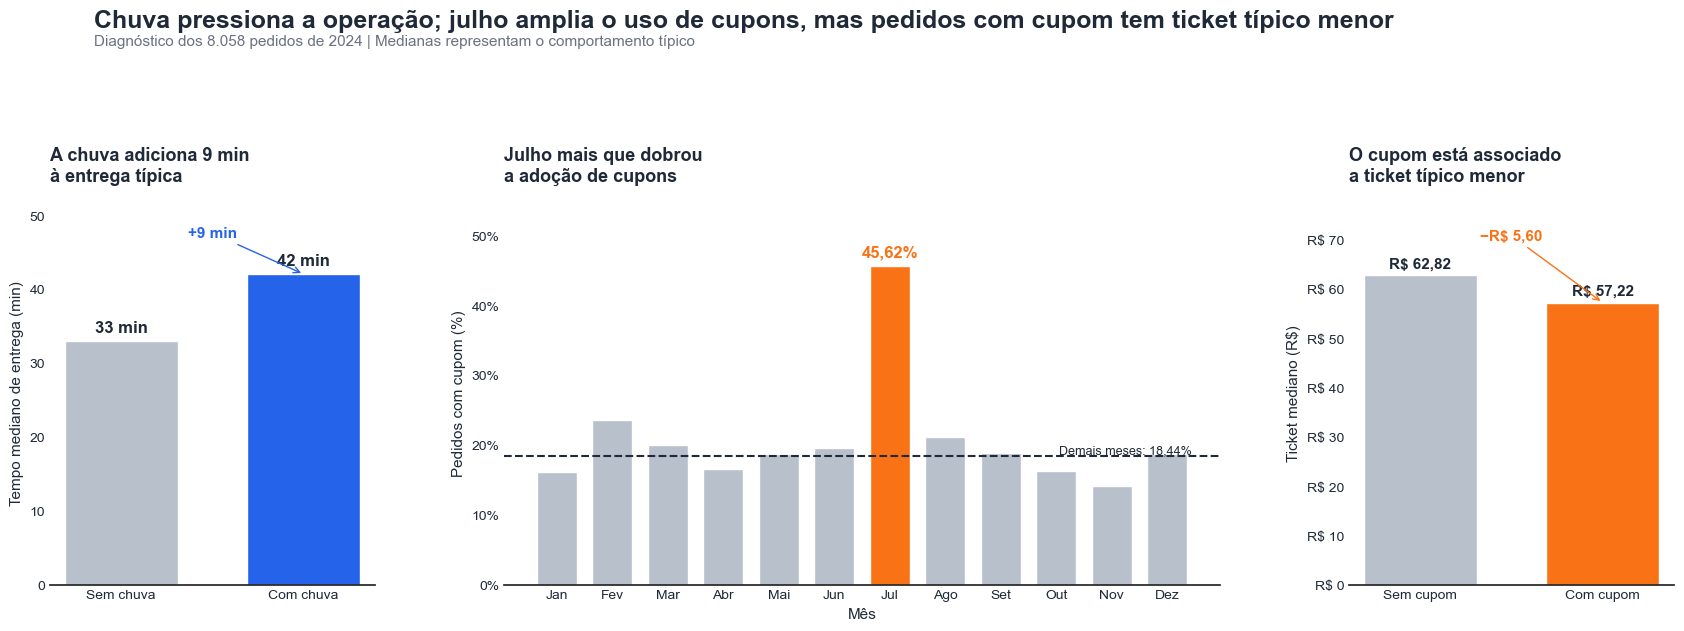

In [450]:
# Nomes dos meses
nomes_meses = [
    "Jan", "Fev", "Mar", "Abr",
    "Mai", "Jun", "Jul", "Ago",
    "Set", "Out", "Nov", "Dez"
]

# Cores dos meses, com julho em destaque
cores_meses = [
    COR_DESTAQUE if mes == 7 else COR_NEUTRA
    for mes in cupom_mes_figura["mes"]
]

# Criação da figura
fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 6),
    gridspec_kw={
        "width_ratios": [1, 2.2, 1]
    }
)

fig.patch.set_facecolor("white")

# ==================================================
# Painel 1 — Chuva e tempo de entrega
# ==================================================

ax1 = axes[0]

barras_chuva = ax1.bar(
    tempo_chuva_figura["chuva"],
    tempo_chuva_figura["tempo_mediano"],
    color=[
        CORES_CHUVA[False],
        CORES_CHUVA[True]
    ],
    width=0.62
)

for barra, valor in zip(
    barras_chuva,
    tempo_chuva_figura["tempo_mediano"]
):
    ax1.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.8,
        f"{valor:.0f} min",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color=COR_TEXTO
    )

ax1.annotate(
    "+9 min",
    xy=(1, 42),
    xytext=(0.50, 47),
    ha="center",
    fontsize=11,
    fontweight="bold",
    color=CORES_CHUVA[True],
    arrowprops={
        "arrowstyle": "->",
        "color": CORES_CHUVA[True]
    }
)

ax1.set_title(
    "A chuva adiciona 9 min\nà entrega típica",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color=COR_TEXTO,
    pad=14
)

ax1.set_xlabel("")
ax1.set_ylabel("Tempo mediano de entrega (min)")
ax1.set_ylim(0, 52)

# ==================================================
# Painel 2 — Taxa mensal de uso de cupom
# ==================================================

ax2 = axes[1]

barras_meses = ax2.bar(
    cupom_mes_figura["mes"],
    cupom_mes_figura["taxa_uso_cupom"],
    color=cores_meses,
    width=0.72
)

for barra, mes, valor in zip(
    barras_meses,
    cupom_mes_figura["mes"],
    cupom_mes_figura["taxa_uso_cupom"]
):
    if mes == 7:
        ax2.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 1,
            f"{valor:.2f}%".replace(".", ","),
            ha="center",
            va="bottom",
            fontsize=12,
            fontweight="bold",
            color=COR_DESTAQUE
        )

ax2.axhline(
    18.44,
    color=COR_TEXTO,
    linewidth=1.5,
    linestyle="--"
)

ax2.text(
    12.45,
    18.44,
    "Demais meses: 18,44%",
    ha="right",
    va="bottom",
    fontsize=9,
    color=COR_TEXTO
)

ax2.set_title(
    "Julho mais que dobrou\na adoção de cupons",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color=COR_TEXTO,
    pad=14
)

ax2.set_xlabel("Mês")
ax2.set_ylabel("Pedidos com cupom (%)")

ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(nomes_meses)
ax2.yaxis.set_major_formatter(FORMATADOR_PERCENTUAL)
ax2.set_ylim(0, 55)

# ==================================================
# Painel 3 — Ticket com e sem cupom
# ==================================================

ax3 = axes[2]

barras_ticket = ax3.bar(
    ticket_cupom_figura["cupom"],
    ticket_cupom_figura["ticket_mediano"],
    color=[
        CORES_CUPOM[False],
        CORES_CUPOM[True]
    ],
    width=0.62
)

for barra, valor in zip(
    barras_ticket,
    ticket_cupom_figura["ticket_mediano"]
):
    ax3.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"R$ {valor:.2f}".replace(".", ","),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=COR_TEXTO
    )

ax3.annotate(
    "−R$ 5,60",
    xy=(1, 57.22),
    xytext=(0.50, 70),
    ha="center",
    fontsize=11,
    fontweight="bold",
    color=COR_DESTAQUE,
    arrowprops={
        "arrowstyle": "->",
        "color": COR_DESTAQUE
    }
)

ax3.set_title(
    "O cupom está associado\na ticket típico menor",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color=COR_TEXTO,
    pad=14
)

ax3.set_xlabel("")
ax3.set_ylabel("Ticket mediano (R$)")
ax3.yaxis.set_major_formatter(FORMATADOR_REAIS)
ax3.set_ylim(0, 78)

# ==================================================
# Padronização visual
# ==================================================

for ax in axes:
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", length=0)

# Título geral da figura
fig.suptitle(
    "Chuva pressiona a operação; julho amplia o uso de cupons, mas pedidos com cupom tem ticket típico menor",
    x=0.06,
    y=1.05,
    ha="left",
    fontsize=18,
    fontweight="bold",
    color=COR_TEXTO
)

fig.text(
    0.06,
    0.99,
    (
        "Diagnóstico dos 8.058 pedidos de 2024 | "
        "Medianas representam o comportamento típico"
    ),
    ha="left",
    fontsize=11,
    color="#6B7280"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.92],
    w_pad=4
)

# Salva a figura conforme exigido pelo projeto
plt.savefig(
    "saidas/figura_principal.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [451]:
print(
    "Figura salva:",
    os.path.exists("saidas/figura_principal.png")
)

print(
    "Caminho:",
    os.path.abspath("saidas/figura_principal.png")
)

Figura salva: True
Caminho: c:\Users\Usuário\OneDrive\Desktop\saidas\figura_principal.png


A figura principal mostra que as alavancas analisadas têm efeitos distintos. A chuva está associada a um aumento de 9 minutos no tempo mediano de entrega, passando de 33 para 42 minutos, o que representa uma pressão operacional relevante. Em julho, a campanha esteve associada a uma taxa de uso de cupom de 45,62%, contra 18,44% nos demais meses. Contudo, os pedidos com cupom apresentaram ticket mediano de R$ 57,22, enquanto os pedidos sem cupom tiveram mediana de R$ 62,82, uma diferença de R$ 5,60 a menos. Assim, os cupons ampliaram sua adoção, especialmente em julho, mas não estiveram associados a um ticket típico maior.

### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

1. A chuva elevou o tempo mediano de entrega de 33 para 42 minutos, um aumento de 9 minutos confirmado pelo teste de Mann-Whitney (Tarefa 9.1), o que importa porque exige reforço operacional e revisão da promessa de prazo nos dias chuvosos.

2. Dos pedidos com tempo válido, 1.476, ou 18,39%, ultrapassaram 45 minutos (Tarefa 5.4), o que importa porque quase 1 em cada 5 entregas quebraria uma promessa de entrega em até 45 minutos.

3. Os pedidos entregues acima de 35 minutos tiveram avaliação média de 4,203, contra 4,488 nos pedidos entregues em até 35 minutos, uma redução de 0,285 ponto confirmada por Spearman e Mann-Whitney (Tarefa 9.3), o que importa porque atrasos estão associados à piora da satisfação do cliente.

4. Em julho, 45,62% dos pedidos usaram cupom, contra 18,44% nos demais meses, uma diferença de 27,18 pontos percentuais confirmada pelo qui-quadrado (Tarefa 9.6), o que importa porque a campanha “Julho de cupons” esteve associada a uma forte ampliação do uso do benefício.

5. Os pedidos com cupom tiveram ticket mediano de R$ 57,22, contra R$ 62,82 sem cupom, uma diferença de R$ 5,60 confirmada pelo teste de Mann-Whitney (Tarefa 9.2), o que importa porque o maior uso de cupons não esteve associado a um ticket típico maior.

### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

1. Reforçar a operação nos dias chuvosos, ampliando a disponibilidade de entregadores e ajustando a previsão de prazo, pois a chuva elevou o tempo mediano de entrega de 33 para 42 minutos; acompanhar pela mediana do tempo de entrega na chuva e pelo percentual de entregas acima de 45 minutos.

2. Atuar antes que o pedido ultrapasse 35 minutos, priorizando pedidos próximos desse limite e enviando alertas operacionais, pois entregas acima de 35 minutos tiveram avaliação média 0,285 ponto menor; acompanhar pela avaliação média dos pedidos acima de 35 minutos e pelo percentual entregue em até 35 minutos.

3. Redesenhar os cupons para estimular valor incremental, testando condições como valor mínimo do pedido, pois o uso de cupons aumentou fortemente em julho, mas o ticket mediano com cupom foi R$ 5,60 menor; acompanhar pela taxa de uso de cupom, pelo ticket mediano com cupom e pela participação de clientes novos entre os pedidos com cupom.

### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).



1. A análise identifica associações, mas não comprova causalidade: não é possível afirmar que a chuva causou todo o aumento no tempo de entrega ou que a campanha de julho causou o crescimento dos pedidos, pois outras variáveis podem ter influenciado os resultados.

2. Faltam variáveis operacionais importantes: a base não informa trânsito, disponibilidade de entregadores, tempo de preparo do restaurante ou quantidade de itens, fatores que podem explicar parte das diferenças no tempo de entrega e no valor dos pedidos.

3. A avaliação é opcional: como 16,65% dos pedidos não possuem avaliação, as conclusões sobre satisfação representam apenas os clientes que decidiram avaliar e podem conter viés de resposta.

4. Existem informações ausentes ou inválidas: foram encontrados 315 valores originalmente faltantes em distancia_km, além de 7 distâncias classificadas como inválidas e 33 tempos de entrega inválidos, reduzindo a quantidade de observações disponíveis em algumas análises.

5. A base cobre somente 2024 e três cidades: os resultados descrevem São Paulo, Rio de Janeiro e Belo Horizonte nesse período, mas não permitem afirmar que os mesmos padrões ocorrerão em outros anos, cidades ou operações.

6. Não há identificação do cliente: a coluna cliente_novo informa apenas se aquele é o primeiro pedido, mas não existe um identificador individual que permita analisar recorrência, retenção, frequência de compra ou valor do cliente ao longo do tempo.

---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [452]:
# Colunas usadas somente como apoio aos cálculos
colunas_auxiliares = [
    "razao_mediana_cozinha"
]

# Cria a base limpa para publicação sem alterar df
df_publicacao = df.drop(
    columns=colunas_auxiliares,
    errors="ignore"
).copy()

print("Dimensão da base tratada:")
print(df_publicacao.shape)

print("\nColunas da base tratada:")
print(df_publicacao.columns.tolist())


Dimensão da base tratada:
(8058, 23)

Colunas da base tratada:
['pedido_id', 'data_hora', 'cidade', 'bairro', 'restaurante_id', 'tipo_cozinha', 'plataforma', 'forma_pagamento', 'cupom', 'cliente_novo', 'chuva', 'distancia_km', 'tempo_entrega_min', 'valor_pedido', 'taxa_entrega', 'avaliacao', 'data', 'mes', 'hora', 'dia_semana', 'tempo_invalido', 'distancia_invalida', 'pedido_grande']


In [453]:
import os

# Garante que a pasta de saída exista
os.makedirs("saidas", exist_ok=True)

# Salva a base limpa sem o índice do DataFrame
df_publicacao.to_csv(
    "saidas/delivery_pedidos_limpo.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Base limpa salva em:")
print("saidas/delivery_pedidos_limpo.csv")

Base limpa salva em:
saidas/delivery_pedidos_limpo.csv


In [454]:
# Função para obter um exemplo não nulo de cada coluna
def obter_exemplo(serie):
    valores_validos = serie.dropna()

    if valores_validos.empty:
        return "Sem valor disponível"

    return valores_validos.iloc[0]


dicionario_dados = pd.DataFrame({
    "coluna": df_publicacao.columns,
    "tipo": [
        str(df_publicacao[coluna].dtype)
        for coluna in df_publicacao.columns
    ],
    "percentual_faltantes": [
        df_publicacao[coluna].isna().mean() * 100
        for coluna in df_publicacao.columns
    ],
    "exemplo": [
        obter_exemplo(df_publicacao[coluna])
        for coluna in df_publicacao.columns
    ]
})

In [455]:
# Cria uma cópia apenas para visualização
dicionario_visual = dicionario_dados.copy()

# Formata exemplos do tipo float com duas casas decimais
def formatar_exemplo(valor):
    if isinstance(valor, (float, np.floating)):
        return f"{valor:.2f}"
    return valor

dicionario_visual["exemplo"] = (
    dicionario_visual["exemplo"]
    .apply(formatar_exemplo)
)

# Renomeia as colunas para facilitar a leitura
dicionario_visual = dicionario_visual.rename(columns={
    "coluna": "Coluna",
    "tipo": "Tipo",
    "percentual_faltantes": "% de faltantes",
    "exemplo": "Exemplo de valor"
})

# Exibe o dicionário com visualização profissional
display(
    dicionario_visual.style
        .set_caption("Dicionário de dados da base limpa")
        .format({
            "% de faltantes": "{:.2f}%"
        })
        .hide(axis="index")
        .set_properties(**{
            "text-align": "left",
            "vertical-align": "middle",
            "padding": "8px 12px",
            "border-bottom": "1px solid #E5E7EB"
        })
        .set_properties(
            subset=["Coluna"],
            **{
                "font-weight": "bold",
                "color": "#1F4E78"
            }
        )
        .set_properties(
            subset=["Tipo", "% de faltantes"],
            **{
                "text-align": "center"
            }
        )
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("text-align", "left"),
                    ("font-size", "16px"),
                    ("font-weight", "bold"),
                    ("color", "#1F2937"),
                    ("padding", "0 0 12px 0")
                ]
            },
            {
                "selector": "thead th",
                "props": [
                    ("background-color", "#1F4E78"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "left"),
                    ("padding", "10px 12px")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    ("background-color", "#F8FAFC")
                ]
            },
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "collapse"),
                    ("width", "100%"),
                    ("font-size", "13px"),
                    ("border", "1px solid #E5E7EB")
                ]
            }
        ])
)

Coluna,Tipo,% de faltantes,Exemplo de valor
pedido_id,int64,0.00%,500000
data_hora,datetime64[ns],0.00%,2024-01-01 11:21:00
cidade,object,0.00%,São Paulo
bairro,object,0.00%,Tatuapé
restaurante_id,object,0.00%,R912
tipo_cozinha,object,0.00%,Hambúrguer
plataforma,object,0.00%,Android
forma_pagamento,object,0.00%,Pix
cupom,bool,0.00%,False
cliente_novo,bool,0.00%,False


### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

1.  A chuva elevou o tempo mediano de entrega de 33 para 42 minutos. O aumento de 9 minutos foi confirmado pelo Mann-Whitney na Tarefa 9.1 e importa porque exige reforço operacional e revisão da promessa de prazo em dias chuvosos.

2. 1.476 pedidos, ou 18,39% dos pedidos com tempo válido, ultrapassaram 45 minutos. A métrica vem da Tarefa 5.4 e mostra que quase 1 em cada 5 entregas quebraria uma promessa de entrega em até 45 minutos.

3. Pedidos acima de 35 minutos tiveram avaliação média de 4,203, contra 4,488 nos pedidos entregues em até 35 minutos. A queda de 0,285 ponto foi confirmada por Spearman e Mann-Whitney na Tarefa 9.3 e importa porque atrasos estão associados à piora da satisfação.

4. Em julho, 45,62% dos pedidos usaram cupom, contra 18,44% nos demais meses. A diferença de 27,18 pontos percentuais foi confirmada pelo qui-quadrado na Tarefa 9.6 e mostra que a campanha esteve associada a forte aumento no uso do benefício.

5. Pedidos com cupom tiveram ticket mediano de R$ 57,22, contra R$ 62,82 sem cupom. A diferença de R$ 5,60 foi confirmada pelo Mann-Whitney na Tarefa 9.2 e importa porque o maior uso de cupons não esteve associado a ticket típico maior.

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [ ] Repositório Git criado e repositório público.
- [ ] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [ ] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [ ] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [ ] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |